# Parkinson's Disease Classification from Speech-Derived Heatmaps

### MTP — Reproduction and Lightweight CNN Extension

This notebook reproduces the approach proposed in:

> Omar El Ariss and Kaoning Hu,  
> **"ResNet-Based Parkinson's Disease Classification"**,  
> IEEE Transactions on Artificial Intelligence, 2023.

## Objective

The project has three stages:

1. Reproduce the paper's TQWT heatmap + ImageNet-pretrained ResNet50 pipeline.
2. Evaluate the same representation using a lightweight CNN architecture such as MobileNetV3.
3. Investigate alternative training workflows and feature representations.

## Core pipeline

Speech recordings
→ frequency-domain features
→ TQWT feature matrix
→ 2-D heatmap
→ CNN
→ PD / Healthy classification

## Dataset

UCI Parkinson's Disease Classification Dataset (#470).

The dataset contains 756 voice recordings from 252 participants,
with three recordings per participant.

## Main research questions

- Can the reported ResNet50 results be reproduced?
- How important is the TQWT representation?
- How does transfer learning affect performance?
- How does a lightweight architecture such as MobileNetV3 compare with ResNet50?
- How does performance change under subject-wise evaluation?

In [ ]:
!pip install -q ucimlrepo

In [ ]:

import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

PyTorch: 2.11.0+cu128
NumPy: 2.1.3
Pandas: 2.2.3


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
ROOT = Path("/content/mtp_parkinsons")

RAW_DATA_DIR = ROOT / "data" / "raw"
PROCESSED_DATA_DIR = ROOT / "data" / "processed"
HEATMAP_DIR = PROCESSED_DATA_DIR / "heatmaps"

CHECKPOINT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"
FIGURE_DIR = ROOT / "figures"

for directory in [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    HEATMAP_DIR,
    CHECKPOINT_DIR,
    RESULTS_DIR,
    FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print(ROOT)

/content/mtp_parkinsons


In [ ]:
if torch.cuda.is_available():
    total_memory = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"GPU memory: {total_memory:.2f} GB")

GPU memory: 14.56 GB


# 1. Dataset Acquisition

# 1. Dataset Acquisition

We use the Parkinson's Disease Classification dataset from the
UCI Machine Learning Repository (Dataset ID: 470).

The dataset contains:
- 756 voice recordings
- 252 subjects
- 3 recordings per subject
- 188 Parkinson's disease subjects
- 64 healthy subjects
- 754 features

The recordings correspond to sustained phonation of the vowel /a/.

In [ ]:
# Download UCI Parkinson's Disease Classification dataset

DATASET_ZIP = RAW_DATA_DIR / "parkinson_dataset.zip"

!wget -q -O {DATASET_ZIP} \
    "https://archive.ics.uci.edu/static/public/470/parkinson+s+disease+classification.zip"

print("Downloaded:", DATASET_ZIP)
print("Size:", DATASET_ZIP.stat().st_size / 1024**2, "MB")

Downloaded: /content/mtp_parkinsons/data/raw/parkinson_dataset.zip
Size: 2.04099178314209 MB


In [ ]:
import zipfile

with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    print("Files in archive:")
    for name in z.namelist():
        print(name)

Files in archive:
pd_speech_features.rar


In [ ]:
with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    z.extractall(RAW_DATA_DIR / "extracted")

print("Extraction complete.")

for path in (RAW_DATA_DIR / "extracted").rglob("*"):
    if path.is_file():
        print(path)

Extraction complete.
/content/mtp_parkinsons/data/raw/extracted/pd_speech_features.rar


In [ ]:
!apt-get -qq update
!apt-get -qq install -y unrar

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
RAR_PATH = RAW_DATA_DIR / "extracted" / "pd_speech_features.rar"
RAR_EXTRACT_DIR = RAW_DATA_DIR / "dataset"

RAR_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

!unrar x -o+ "{RAR_PATH}" "{RAR_EXTRACT_DIR}/"

print("Extraction complete.")


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/mtp_parkinsons/data/raw/extracted/pd_speech_features.rar

Extracting  /content/mtp_parkinsons/data/raw/dataset/pd_speech_features.csv       1%  3%  4%  6%  7%  9% 10% 12% 13% 15% 16% 18% 19% 21% 22% 24% 26% 27% 29% 30% 32% 33% 35% 36% 38% 39% 41% 42% 44% 45% 47% 48% 50% 52% 53% 55% 56% 58% 59% 61% 62% 64% 65% 67% 68% 70% 71% 73% 74% 76% 78% 79% 81% 82% 84% 85% 87% 88% 90% 91% 93% 94% 96% 97% 99%100%  OK 
All OK
Extraction complete.


In [ ]:
for path in RAR_EXTRACT_DIR.rglob("*"):
    if path.is_file():
        print(path)

/content/mtp_parkinsons/data/raw/dataset/pd_speech_features.csv


In [ ]:
DATA_PATH="/content/mtp_parkinsons/data/raw/dataset/pd_speech_features.csv"

In [ ]:
df = pd.read_csv(
    DATA_PATH,
    header=1
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [ ]:
df.columns = df.columns.astype(str).str.strip()

print(df.columns[:20].tolist())
print(df.columns[-10:].tolist())

['id', 'gender', 'PPE', 'DFA', 'RPDE', 'numPulses', 'numPeriodsPulses', 'meanPeriodPulses', 'stdDevPeriodPulses', 'locPctJitter', 'locAbsJitter', 'rapJitter', 'ppq5Jitter', 'ddpJitter', 'locShimmer', 'locDbShimmer', 'apq3Shimmer', 'apq5Shimmer', 'apq11Shimmer', 'ddaShimmer']
['tqwt_kurtosisValue_dec_28', 'tqwt_kurtosisValue_dec_29', 'tqwt_kurtosisValue_dec_30', 'tqwt_kurtosisValue_dec_31', 'tqwt_kurtosisValue_dec_32', 'tqwt_kurtosisValue_dec_33', 'tqwt_kurtosisValue_dec_34', 'tqwt_kurtosisValue_dec_35', 'tqwt_kurtosisValue_dec_36', 'class']


In [ ]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nUnique subjects:")
print(df["id"].nunique())

Shape: (756, 755)
Missing values: 0

Class distribution:
class
1    564
0    192
Name: count, dtype: int64

Unique subjects:
252


In [ ]:
recordings_per_subject = df.groupby("id").size()

print(recordings_per_subject.value_counts())

print("\nSubjects with recording count != 3:")
print(recordings_per_subject[recordings_per_subject != 3])

3    252
Name: count, dtype: int64

Subjects with recording count != 3:
Series([], dtype: int64)


In [ ]:
tqwt_cols = [
    col for col in df.columns
    if "tqwt" in col.lower()
]

print("Number of TQWT columns:", len(tqwt_cols))

for col in tqwt_cols:
    print(col)

Number of TQWT columns: 432
tqwt_energy_dec_1
tqwt_energy_dec_2
tqwt_energy_dec_3
tqwt_energy_dec_4
tqwt_energy_dec_5
tqwt_energy_dec_6
tqwt_energy_dec_7
tqwt_energy_dec_8
tqwt_energy_dec_9
tqwt_energy_dec_10
tqwt_energy_dec_11
tqwt_energy_dec_12
tqwt_energy_dec_13
tqwt_energy_dec_14
tqwt_energy_dec_15
tqwt_energy_dec_16
tqwt_energy_dec_17
tqwt_energy_dec_18
tqwt_energy_dec_19
tqwt_energy_dec_20
tqwt_energy_dec_21
tqwt_energy_dec_22
tqwt_energy_dec_23
tqwt_energy_dec_24
tqwt_energy_dec_25
tqwt_energy_dec_26
tqwt_energy_dec_27
tqwt_energy_dec_28
tqwt_energy_dec_29
tqwt_energy_dec_30
tqwt_energy_dec_31
tqwt_energy_dec_32
tqwt_energy_dec_33
tqwt_energy_dec_34
tqwt_energy_dec_35
tqwt_energy_dec_36
tqwt_entropy_shannon_dec_1
tqwt_entropy_shannon_dec_2
tqwt_entropy_shannon_dec_3
tqwt_entropy_shannon_dec_4
tqwt_entropy_shannon_dec_5
tqwt_entropy_shannon_dec_6
tqwt_entropy_shannon_dec_7
tqwt_entropy_shannon_dec_8
tqwt_entropy_shannon_dec_9
tqwt_entropy_shannon_dec_10
tqwt_entropy_shannon_dec_1

In [ ]:
from collections import defaultdict

tqwt_groups = defaultdict(list)

for col in tqwt_cols:
    # Everything before the final "_<number>" is the feature function
    match = re.match(r"(.+)_(\d+)$", col)

    if match:
        group_name = match.group(1)
        feature_idx = int(match.group(2))
        tqwt_groups[group_name].append((feature_idx, col))

for group_name, values in tqwt_groups.items():
    values.sort(key=lambda x: x[0])
    print(f"{group_name:40s} -> {len(values)} values")

tqwt_energy_dec                          -> 36 values
tqwt_entropy_shannon_dec                 -> 36 values
tqwt_entropy_log_dec                     -> 36 values
tqwt_TKEO_mean_dec                       -> 36 values
tqwt_TKEO_std_dec                        -> 36 values
tqwt_medianValue_dec                     -> 36 values
tqwt_meanValue_dec                       -> 36 values
tqwt_stdValue_dec                        -> 36 values
tqwt_minValue_dec                        -> 36 values
tqwt_maxValue_dec                        -> 36 values
tqwt_skewnessValue_dec                   -> 36 values
tqwt_kurtosisValue_dec                   -> 36 values


In [ ]:
print("Number of TQWT groups:", len(tqwt_groups))

for group_name, values in tqwt_groups.items():
    indices = [idx for idx, _ in values]

    print(
        group_name,
        "→",
        len(values),
        "values",
        f"(indices {min(indices)}–{max(indices)})"
    )

assert len(tqwt_groups) == 12
assert all(len(values) == 36 for values in tqwt_groups.values())

print("\nVerified: TQWT = 12 × 36 = 432 features")

Number of TQWT groups: 12
tqwt_energy_dec → 36 values (indices 1–36)
tqwt_entropy_shannon_dec → 36 values (indices 1–36)
tqwt_entropy_log_dec → 36 values (indices 1–36)
tqwt_TKEO_mean_dec → 36 values (indices 1–36)
tqwt_TKEO_std_dec → 36 values (indices 1–36)
tqwt_medianValue_dec → 36 values (indices 1–36)
tqwt_meanValue_dec → 36 values (indices 1–36)
tqwt_stdValue_dec → 36 values (indices 1–36)
tqwt_minValue_dec → 36 values (indices 1–36)
tqwt_maxValue_dec → 36 values (indices 1–36)
tqwt_skewnessValue_dec → 36 values (indices 1–36)
tqwt_kurtosisValue_dec → 36 values (indices 1–36)

Verified: TQWT = 12 × 36 = 432 features


In [ ]:
TQWT_GROUP_ORDER = list(tqwt_groups.keys())

for i, group in enumerate(TQWT_GROUP_ORDER):
    print(i, group)

0 tqwt_energy_dec
1 tqwt_entropy_shannon_dec
2 tqwt_entropy_log_dec
3 tqwt_TKEO_mean_dec
4 tqwt_TKEO_std_dec
5 tqwt_medianValue_dec
6 tqwt_meanValue_dec
7 tqwt_stdValue_dec
8 tqwt_minValue_dec
9 tqwt_maxValue_dec
10 tqwt_skewnessValue_dec
11 tqwt_kurtosisValue_dec


In [ ]:
def get_tqwt_matrix(row):
    matrix = []

    for group in TQWT_GROUP_ORDER:
        values = tqwt_groups[group]

        # Sort by feature number: _1, _2, ..., _36
        values = sorted(values, key=lambda x: x[0])

        row_values = [
            row[column]
            for _, column in values
        ]

        matrix.append(row_values)

    return np.array(matrix, dtype=np.float32)

In [ ]:
sample_matrix = get_tqwt_matrix(df.iloc[0])

print("Shape:", sample_matrix.shape)
print(sample_matrix)

Shape: (12, 36)
[[ 1.1100000e-05  3.9800002e-06  4.9199998e-06  3.5400001e-06
   7.1899999e-06  3.8700000e-05  1.6363000e-04  3.7610001e-04
   3.9246000e-04  4.0610001e-04  4.1457999e-04  2.3899000e-04
   1.9048000e-03  1.2066000e-02  2.9439000e-02  3.7555002e-02
   8.9055002e-02  1.7727999e-01  1.3122000e-01  5.1587999e-02
   1.9785000e-02  5.6090001e-02  1.2525000e-01  5.7907999e-02
   1.0070000e-02  5.7574999e-02  1.0807000e-01  3.2742999e-02
   2.5665000e-04  1.3300000e-05  6.7500000e-06  2.7500000e-06
   2.0400000e-06  1.6700000e-06  1.1100000e-06  5.3500000e-05]
 [ 2.0497000e-01  7.6626003e-02  9.1514997e-02  6.6105001e-02
   1.2716000e-01  5.9587002e-01  2.1831999e+00  4.5851002e+00
   4.6876998e+00  4.8635001e+00  4.8839998e+00  2.8180001e+00
   1.8862499e+01  8.9752502e+01  1.7469200e+02  1.8950000e+02
   3.6071259e+02  5.4167188e+02  4.2283020e+02  2.2564610e+02
   9.9364799e+01  2.1478951e+02  3.3781409e+02  2.0138409e+02
   5.3731400e+01  1.7872870e+02  2.3024020e+02  1.110

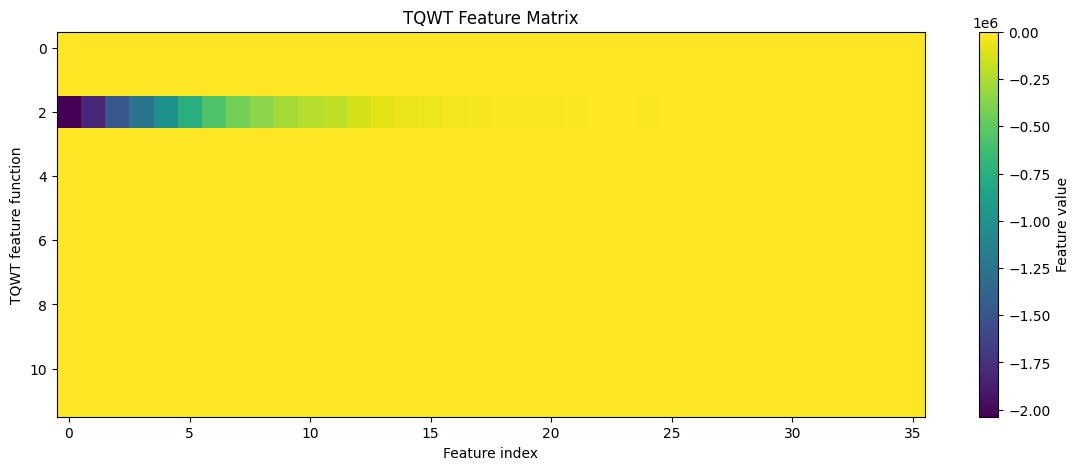

In [ ]:
plt.figure(figsize=(14, 5))

plt.imshow(
    sample_matrix,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Feature value")

plt.xlabel("Feature index")
plt.ylabel("TQWT feature function")
plt.title("TQWT Feature Matrix")

plt.show()

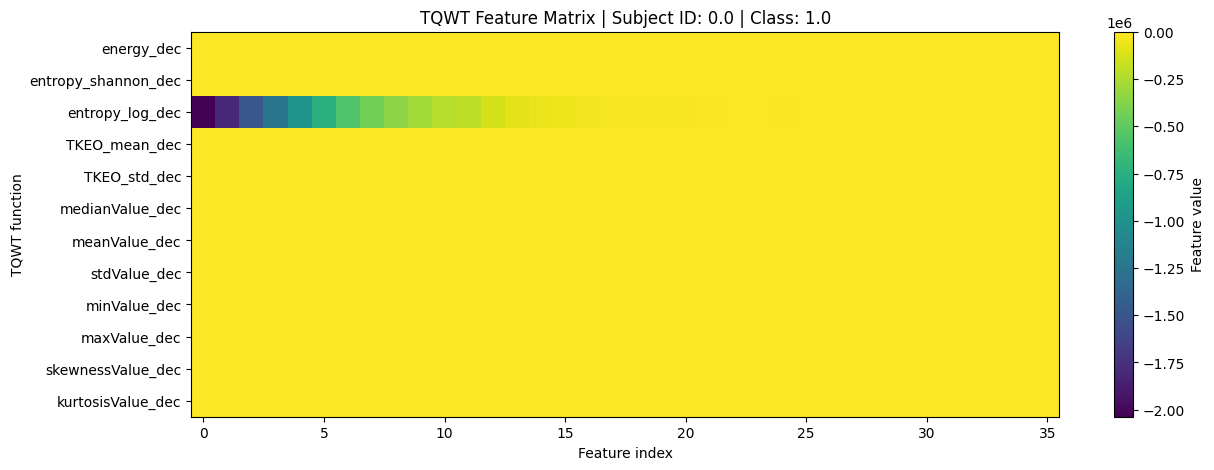

In [ ]:
plt.figure(figsize=(14, 5))

plt.imshow(
    sample_matrix,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Feature value")

plt.yticks(
    range(len(TQWT_GROUP_ORDER)),
    [group.replace("tqwt_", "") for group in TQWT_GROUP_ORDER]
)

plt.xlabel("Feature index")
plt.ylabel("TQWT function")
plt.title(
    f"TQWT Feature Matrix | "
    f"Subject ID: {df.iloc[0]['id']} | "
    f"Class: {df.iloc[0]['class']}"
)

plt.show()

In [ ]:
tqwt_stats = []

for group in TQWT_GROUP_ORDER:

    # Get the 36 columns belonging to this TQWT function
    cols = [
        col for _, col in sorted(
            tqwt_groups[group],
            key=lambda x: x[0]
        )
    ]

    values = df[cols].to_numpy(dtype=np.float64)

    tqwt_stats.append({
        "group": group,
        "min": values.min(),
        "max": values.max(),
        "mean": values.mean(),
        "std": values.std()
    })

tqwt_stats_df = pd.DataFrame(tqwt_stats)

display(tqwt_stats_df)

,group,min,max,mean,std
0,tqwt_energy_dec,1.160000e-08,0.483210,0.027778,0.058159
1,tqwt_entropy_shannon_dec,-9.758008e+03,3091.513900,139.499459,341.353961
2,tqwt_entropy_log_dec,-2.943848e+06,870.514200,-262533.754982,471441.309433
3,tqwt_TKEO_mean_dec,2.250000e-11,11.383100,0.057606,0.273498
4,tqwt_TKEO_std_dec,2.410000e-11,3.750500,0.030812,0.114049
5,tqwt_medianValue_dec,-1.984400e-01,0.133670,-0.000152,0.003789
6,tqwt_meanValue_dec,-7.898900e-02,0.032668,-0.000144,0.001538
7,tqwt_stdValue_dec,3.640000e-06,2.401000,0.091994,0.159850
8,tqwt_minValue_dec,-4.443400e+00,-0.000028,-0.252408,0.346835
9,tqwt_maxValue_dec,-1.227000e-02,4.472200,0.252174,0.347470


In [ ]:
tqwt_stats_df["range"] = (
    tqwt_stats_df["max"] - tqwt_stats_df["min"]
)

display(
    tqwt_stats_df[
        ["group", "min", "max", "range", "mean", "std"]
    ].sort_values("range", ascending=False)
)

,group,min,max,range,mean,std
2,tqwt_entropy_log_dec,-2.943848e+06,870.514200,2.944719e+06,-262533.754982,471441.309433
11,tqwt_kurtosisValue_dec,1.342700e+00,29579.921900,2.957858e+04,80.700068,776.274715
1,tqwt_entropy_shannon_dec,-9.758008e+03,3091.513900,1.284952e+04,139.499459,341.353961
10,tqwt_skewnessValue_dec,-8.278030e+01,80.934100,1.637144e+02,-0.003983,2.430166
3,tqwt_TKEO_mean_dec,2.250000e-11,11.383100,1.138310e+01,0.057606,0.273498
9,tqwt_maxValue_dec,-1.227000e-02,4.472200,4.484470e+00,0.252174,0.347470
8,tqwt_minValue_dec,-4.443400e+00,-0.000028,4.443372e+00,-0.252408,0.346835
4,tqwt_TKEO_std_dec,2.410000e-11,3.750500,3.750500e+00,0.030812,0.114049
7,tqwt_stdValue_dec,3.640000e-06,2.401000,2.400996e+00,0.091994,0.159850
0,tqwt_energy_dec,1.160000e-08,0.483210,4.832100e-01,0.027778,0.058159


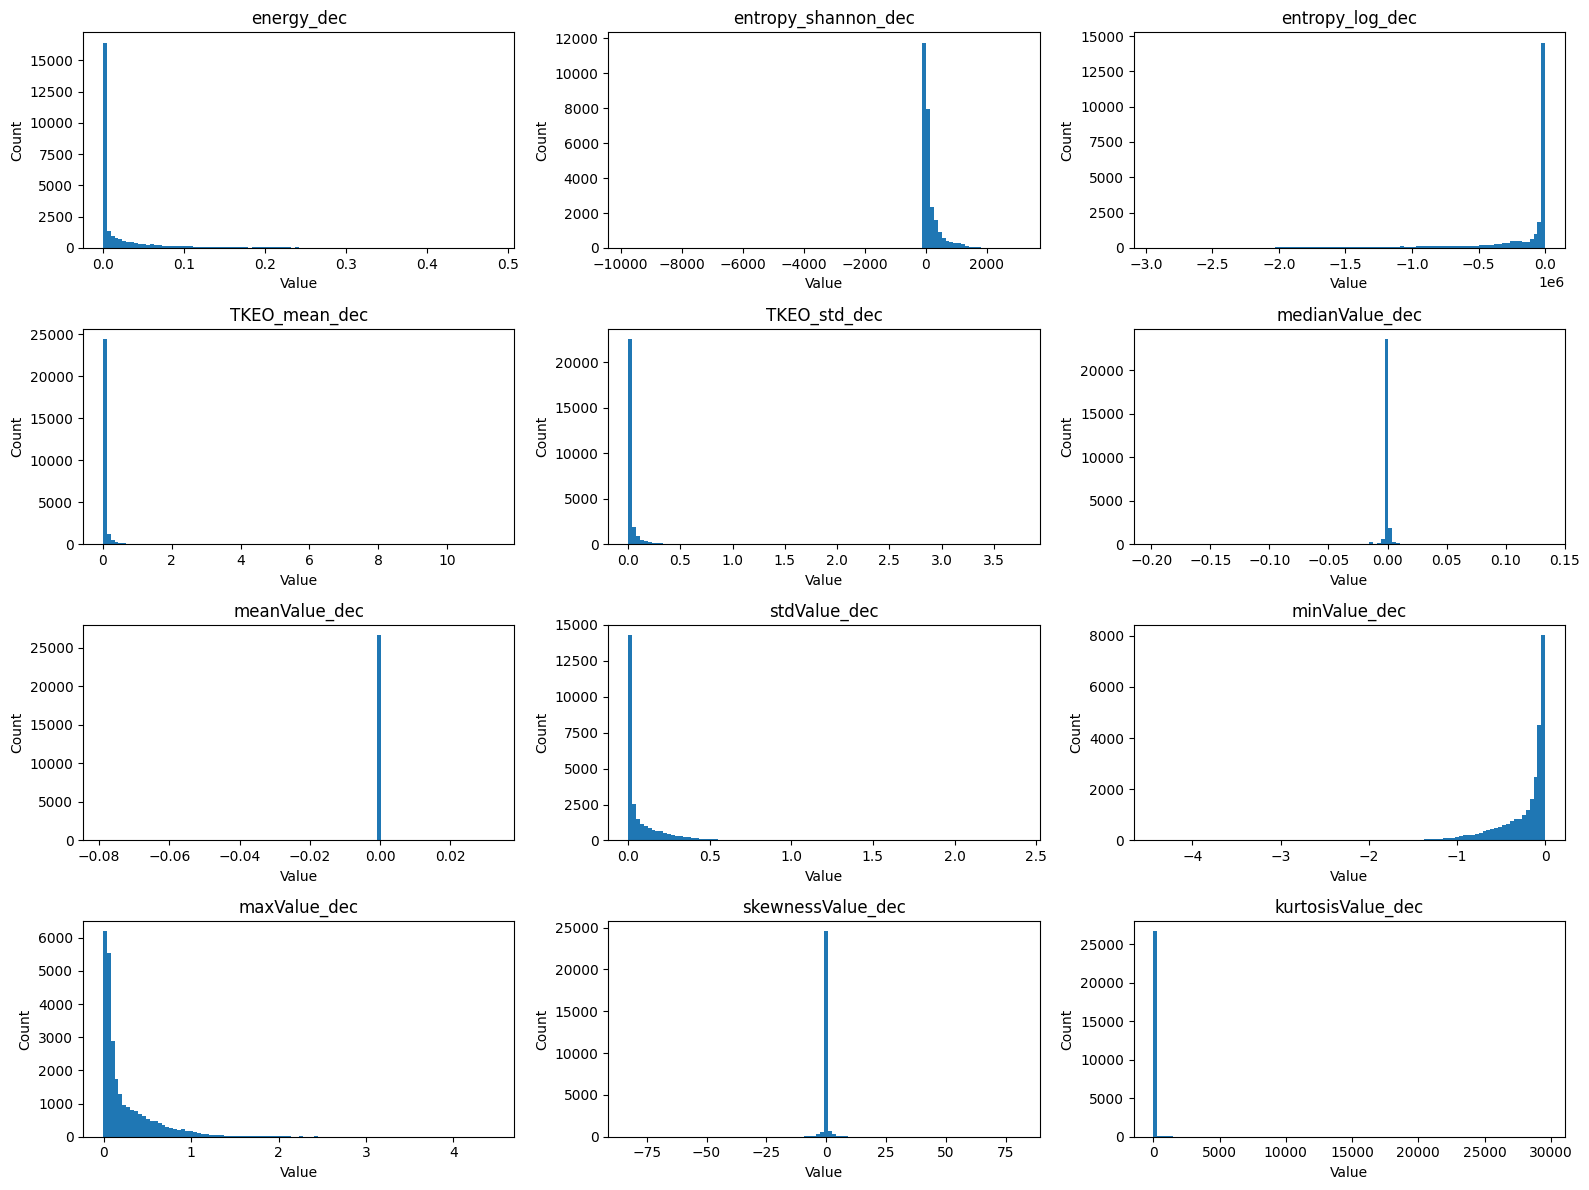

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))

for ax, group in zip(axes.flat, TQWT_GROUP_ORDER):

    cols = [
        col for _, col
        in sorted(tqwt_groups[group], key=lambda x: x[0])
    ]

    values = df[cols].to_numpy().flatten()

    ax.hist(values, bins=100)
    ax.set_title(group.replace("tqwt_", ""))
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

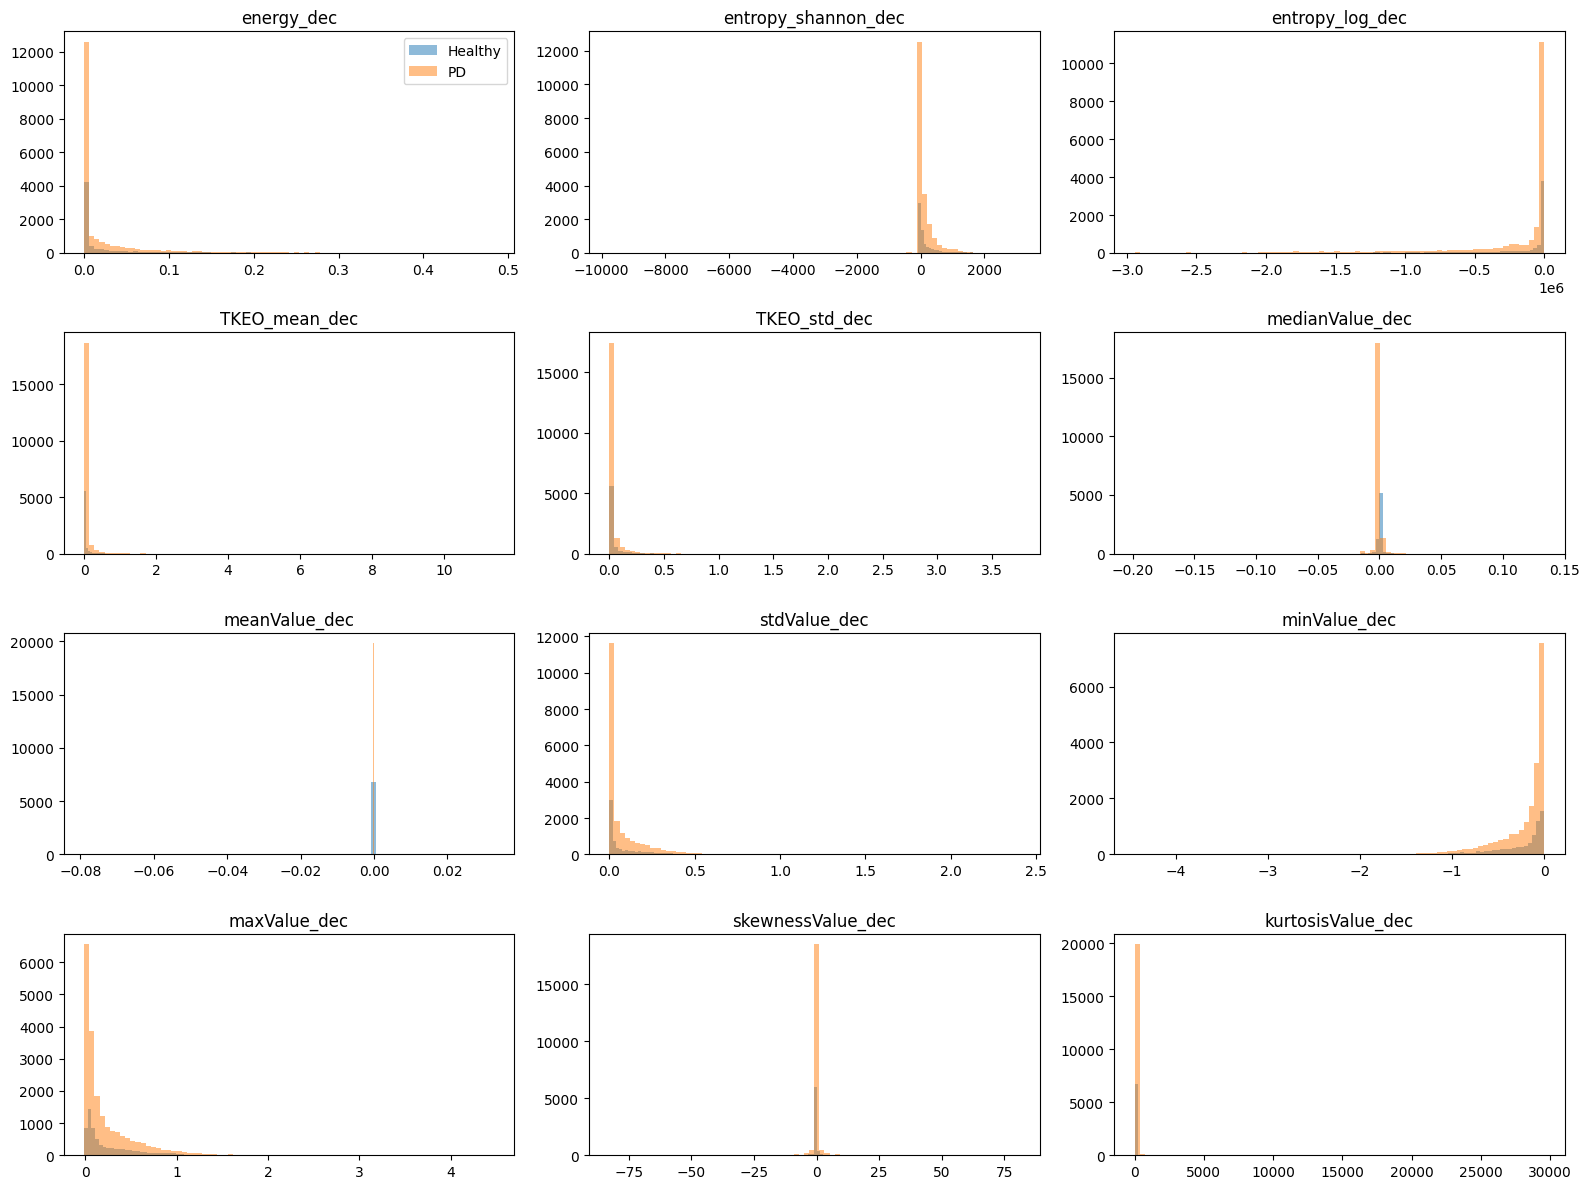

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12))

for ax, group in zip(axes.flat, TQWT_GROUP_ORDER):

    cols = [
        col for _, col
        in sorted(tqwt_groups[group], key=lambda x: x[0])
    ]

    healthy = df[df["class"] == 0][cols].to_numpy().flatten()
    pd_group = df[df["class"] == 1][cols].to_numpy().flatten()

    ax.hist(healthy, bins=80, alpha=0.5, label="Healthy")
    ax.hist(pd_group, bins=80, alpha=0.5, label="PD")

    ax.set_title(group.replace("tqwt_", ""))

axes[0, 0].legend()

plt.tight_layout()
plt.show()

In [ ]:
problem_features = [
    "tqwt_entropy_log_dec",
    "tqwt_entropy_shannon_dec",
    "tqwt_kurtosisValue_dec"
]

for prefix in problem_features:

    cols = [
        col for col in df.columns
        if col.startswith(prefix + "_")
    ]

    values = df[cols].to_numpy().flatten()

    print("\n", prefix)

    print(
        pd.Series(values).quantile(
            [
                0,
                0.001,
                0.01,
                0.05,
                0.25,
                0.50,
                0.75,
                0.95,
                0.99,
                0.999,
                1
            ]
        )
    )


 tqwt_entropy_log_dec
0.000   -2.943848e+06
0.001   -2.565617e+06
0.010   -1.945031e+06
0.050   -1.450724e+06
0.250   -2.775633e+05
0.500   -2.208249e+04
0.750   -6.116901e+03
0.950   -2.460652e+03
0.990   -1.314798e+03
0.999   -6.565828e+01
1.000    8.705142e+02
dtype: float64

 tqwt_entropy_shannon_dec
0.000   -9758.007800
0.001   -2502.072324
0.010       0.000070
0.050       0.045417
0.250       1.036600
0.500      14.179050
0.750     161.358225
0.950     818.284325
0.990    1349.460765
0.999    1883.718935
1.000    3091.513900
dtype: float64

 tqwt_kurtosisValue_dec
0.000        1.342700
0.001        1.518664
0.010        1.558430
0.050        1.678575
0.250        2.452850
0.500        3.886000
0.750        8.356950
0.950       79.882450
0.990     1560.318110
0.999    11234.006070
1.000    29579.921900
dtype: float64


In [ ]:
for group in TQWT_GROUP_ORDER:

    cols = [
        col
        for _, col in sorted(
            tqwt_groups[group],
            key=lambda x: x[0]
        )
    ]

    values = df[cols]

    print("\n" + "=" * 80)
    print(group)

    stats = pd.DataFrame({
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(),
        "min": values.min(),
        "max": values.max(),
        "q01": values.quantile(0.01),
        "q99": values.quantile(0.99),
    })

    print(stats.round(4))


tqwt_energy_dec
                      mean  median     std     min     max     q01     q99
tqwt_energy_dec_1   0.0005  0.0001  0.0028  0.0000  0.0428  0.0000  0.0095
tqwt_energy_dec_2   0.0005  0.0001  0.0027  0.0000  0.0447  0.0000  0.0074
tqwt_energy_dec_3   0.0008  0.0001  0.0037  0.0000  0.0576  0.0000  0.0111
tqwt_energy_dec_4   0.0010  0.0001  0.0041  0.0000  0.0620  0.0000  0.0179
tqwt_energy_dec_5   0.0011  0.0002  0.0045  0.0000  0.0545  0.0000  0.0179
tqwt_energy_dec_6   0.0009  0.0002  0.0037  0.0000  0.0621  0.0000  0.0106
tqwt_energy_dec_7   0.0009  0.0003  0.0025  0.0000  0.0465  0.0000  0.0077
tqwt_energy_dec_8   0.0014  0.0006  0.0034  0.0000  0.0649  0.0000  0.0110
tqwt_energy_dec_9   0.0020  0.0009  0.0042  0.0000  0.0845  0.0000  0.0145
tqwt_energy_dec_10  0.0022  0.0009  0.0067  0.0000  0.1410  0.0000  0.0165
tqwt_energy_dec_11  0.0022  0.0006  0.0061  0.0000  0.0958  0.0000  0.0245
tqwt_energy_dec_12  0.0060  0.0016  0.0121  0.0000  0.0993  0.0000  0.0681
tqwt_ene

In [ ]:
profiles = {}

for group in TQWT_GROUP_ORDER:

    cols = [
        col
        for _, col in sorted(
            tqwt_groups[group],
            key=lambda x: x[0]
        )
    ]

    profiles[group] = df[cols].median(axis=0).to_numpy()

profile_df = pd.DataFrame(profiles).T

profile_df.columns = range(1, 37)

profile_df

,1,2,3,4,5,6,7,8,9,10,...,27,28,29,30,31,32,33,34,35,36
tqwt_energy_dec,6.145000e-05,5.565000e-05,8.320000e-05,1.247000e-04,0.000153,2.068800e-04,3.017450e-04,5.667400e-04,8.528700e-04,8.772000e-04,...,1.630700e-03,1.839350e-04,9.615000e-05,6.585000e-05,0.000071,6.220000e-05,3.310000e-05,0.000014,0.000010,0.000086
tqwt_entropy_shannon_dec,1.699750e+00,1.714850e+00,2.499000e+00,3.384850e+00,4.191150,4.838450e+00,8.535150e+00,1.319325e+01,1.889720e+01,1.696810e+01,...,7.828400e+00,1.760800e+00,9.945900e-01,7.168300e-01,0.753030,6.323650e-01,3.378950e-01,0.158760,0.115770,0.723070
tqwt_entropy_log_dec,-1.862477e+06,-1.523398e+06,-1.224109e+06,-9.773592e+05,-791223.163100,-6.324396e+05,-4.897031e+05,-3.817770e+05,-3.012131e+05,-2.476556e+05,...,-7.228635e+03,-8.256018e+03,-7.307274e+03,-6.202038e+03,-4960.675900,-4.100229e+03,-3.616165e+03,-3405.506350,-2919.294550,-2511.849800
tqwt_TKEO_mean_dec,1.695000e-06,2.260000e-06,3.965000e-06,7.215000e-06,0.000011,1.400000e-05,2.680000e-05,6.855000e-05,1.312050e-04,1.478800e-04,...,2.238300e-03,6.170550e-04,3.379500e-04,2.607700e-04,0.000350,3.705000e-04,2.169750e-04,0.000116,0.000103,0.000367
tqwt_TKEO_std_dec,1.120000e-05,8.855000e-06,1.455000e-05,2.260000e-05,0.000030,3.585000e-05,5.715000e-05,1.293550e-04,2.158000e-04,2.619550e-04,...,5.535850e-03,1.861700e-03,9.758150e-04,7.701600e-04,0.000691,7.199500e-04,4.643400e-04,0.000354,0.000312,0.001258
tqwt_medianValue_dec,-2.235000e-08,-8.530000e-09,0.000000e+00,7.250000e-09,0.000000,6.560000e-09,3.050000e-07,3.110000e-20,2.070000e-07,-1.265000e-06,...,2.155000e-05,1.525000e-06,-9.535000e-06,1.600000e-19,0.000005,4.820000e-06,-6.090000e-06,-0.000006,-0.000001,-0.002087
tqwt_meanValue_dec,-8.850000e-23,-2.660000e-23,7.035000e-23,-5.260000e-23,0.000000,6.425000e-23,-2.945000e-22,2.940000e-22,8.225000e-23,3.375000e-22,...,6.750000e-21,1.620000e-20,2.430000e-21,0.000000e+00,0.000000,-8.420000e-21,-1.010000e-20,0.000000,0.000000,-0.001923
tqwt_stdValue_dec,1.100450e-03,1.222050e-03,1.665200e-03,2.152500e-03,0.002662,3.196800e-03,4.741350e-03,6.772000e-03,9.110850e-03,9.589450e-03,...,5.250350e-02,1.999600e-02,1.465250e-02,1.315000e-02,0.014557,1.472500e-02,1.159000e-02,0.008670,0.008149,0.016976
tqwt_minValue_dec,-2.954800e-02,-1.896300e-02,-2.277450e-02,-2.720100e-02,-0.031233,-3.308500e-02,-3.755050e-02,-5.156200e-02,-6.041650e-02,-6.043050e-02,...,-2.329600e-01,-1.364950e-01,-9.191800e-02,-8.353950e-02,-0.069936,-6.187650e-02,-5.134850e-02,-0.043723,-0.040795,-0.088305
tqwt_maxValue_dec,3.081900e-02,1.980550e-02,2.309950e-02,2.798900e-02,0.031549,3.303800e-02,3.891900e-02,5.163650e-02,6.143700e-02,6.275150e-02,...,2.261050e-01,1.311000e-01,8.679500e-02,7.852950e-02,0.067090,6.054150e-02,4.883850e-02,0.042243,0.038430,0.077166


In [ ]:
print(df["class"].value_counts())
print()
print(df.groupby("class")["id"].nunique())

class
1    564
0    192
Name: count, dtype: int64

class
0     64
1    188
Name: id, dtype: int64


In [ ]:
sample = get_tqwt_matrix(df.iloc[0])

print("RAW")
print("global min:", sample.min())
print("global max:", sample.max())

# A: row-wise min-max
row_min = sample.min(axis=1, keepdims=True)
row_max = sample.max(axis=1, keepdims=True)

row_norm = (sample - row_min) / (
    row_max - row_min + 1e-12
)

print("\nROW NORMALIZED")
print("global min:", row_norm.min())
print("global max:", row_norm.max())

# B: feature-wise standardization
# We'll construct this carefully from the 756 recordings next.

RAW
global min: -2037542.2
global max: 541.6719

ROW NORMALIZED
global min: 0.0
global max: 1.0


In [ ]:
# Build TQWT matrix for every recording
tqwt_tensor = np.stack([
    get_tqwt_matrix(df.iloc[i])
    for i in range(len(df))
])

print("TQWT tensor shape:", tqwt_tensor.shape)

TQWT tensor shape: (756, 12, 36)


In [ ]:
# Flatten each 12x36 TQWT matrix into 432 features
X_tqwt = tqwt_tensor.reshape(len(tqwt_tensor), -1)

print("X shape:", X_tqwt.shape)

# Feature-wise statistics across all recordings
feature_median = np.median(X_tqwt, axis=0)
feature_q1 = np.percentile(X_tqwt, 25, axis=0)
feature_q3 = np.percentile(X_tqwt, 75, axis=0)
feature_iqr = feature_q3 - feature_q1

print("Feature-wise median range:",
      feature_median.min(), "to", feature_median.max())

print("Feature-wise IQR range:",
      feature_iqr.min(), "to", feature_iqr.max())

X shape: (756, 432)
Feature-wise median range: -1862476.5 to 633.32104
Feature-wise IQR range: 3.9799997e-21 to 243920.62


In [ ]:
# Identify nearly-constant feature positions
EPS = 1e-10

near_constant = feature_iqr < EPS

print("Total features:", len(feature_iqr))
print("Near-constant features:", near_constant.sum())
print("Non-constant features:", (~near_constant).sum())

# Show which TQWT functions contain near-constant features
for row_idx, group_name in enumerate(TQWT_GROUP_ORDER):
    start = row_idx * 36
    end = start + 36

    count = near_constant[start:end].sum()

    print(f"{group_name:30s}: {count} near-constant coefficients")

Total features: 432
Near-constant features: 35
Non-constant features: 397
tqwt_energy_dec               : 0 near-constant coefficients
tqwt_entropy_shannon_dec      : 0 near-constant coefficients
tqwt_entropy_log_dec          : 0 near-constant coefficients
tqwt_TKEO_mean_dec            : 0 near-constant coefficients
tqwt_TKEO_std_dec             : 0 near-constant coefficients
tqwt_medianValue_dec          : 0 near-constant coefficients
tqwt_meanValue_dec            : 35 near-constant coefficients
tqwt_stdValue_dec             : 0 near-constant coefficients
tqwt_minValue_dec             : 0 near-constant coefficients
tqwt_maxValue_dec             : 0 near-constant coefficients
tqwt_skewnessValue_dec        : 0 near-constant coefficients
tqwt_kurtosisValue_dec        : 0 near-constant coefficients


In [ ]:
# Robust feature-wise normalization
X_robust = np.zeros_like(X_tqwt, dtype=np.float32)

valid_features = feature_iqr >= EPS

# Normalize only features with meaningful variation
X_robust[:, valid_features] = (
    X_tqwt[:, valid_features] - feature_median[valid_features]
) / feature_iqr[valid_features]

# Inspect the resulting range
print("Robust normalized min:", X_robust.min())
print("Robust normalized max:", X_robust.max())

# Percentiles of the normalized values
print("\nPercentiles:")
for p in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
    print(f"{p:>3}% :", np.percentile(X_robust, p))

Robust normalized min: -19583.35
Robust normalized max: 13052.486

Percentiles:
  0% : -19583.35
  1% : -5.206599
  5% : -1.050486
 25% : -0.2425849
 50% : 0.0
 75% : 0.48809505
 95% : 3.1203728
 99% : 15.400253
100% : 13052.486


In [ ]:
# Check how many values would be clipped at different thresholds

for threshold in [2, 3, 5, 10]:
    below = np.sum(X_robust < -threshold)
    above = np.sum(X_robust > threshold)
    total = X_robust.size

    clipped = below + above

    print(
        f"Threshold ±{threshold}: "
        f"{clipped:,} / {total:,} values clipped "
        f"({100 * clipped / total:.3f}%)"
    )

Threshold ±2: 34,051 / 326,592 values clipped (10.426%)
Threshold ±3: 22,907 / 326,592 values clipped (7.014%)
Threshold ±5: 13,544 / 326,592 values clipped (4.147%)
Threshold ±10: 6,658 / 326,592 values clipped (2.039%)


In [ ]:
# Clipping contribution by TQWT function

for threshold in [3, 5, 10]:
    print(f"\n--- Threshold ±{threshold} ---")

    for row_idx, group_name in enumerate(TQWT_GROUP_ORDER):
        start = row_idx * 36
        end = start + 36

        row_values = X_robust[:, start:end]

        clipped = np.sum(
            (row_values < -threshold) |
            (row_values > threshold)
        )

        total = row_values.size

        print(
            f"{group_name:30s}: "
            f"{clipped:5d} / {total} "
            f"({100 * clipped / total:.2f}%)"
        )


--- Threshold ±3 ---
tqwt_energy_dec               :  2107 / 27216 (7.74%)
tqwt_entropy_shannon_dec      :  1656 / 27216 (6.08%)
tqwt_entropy_log_dec          :   273 / 27216 (1.00%)
tqwt_TKEO_mean_dec            :  2510 / 27216 (9.22%)
tqwt_TKEO_std_dec             :  2165 / 27216 (7.95%)
tqwt_medianValue_dec          :  4032 / 27216 (14.81%)
tqwt_meanValue_dec            :     2 / 27216 (0.01%)
tqwt_stdValue_dec             :   861 / 27216 (3.16%)
tqwt_minValue_dec             :   596 / 27216 (2.19%)
tqwt_maxValue_dec             :   609 / 27216 (2.24%)
tqwt_skewnessValue_dec        :  5911 / 27216 (21.72%)
tqwt_kurtosisValue_dec        :  2185 / 27216 (8.03%)

--- Threshold ±5 ---
tqwt_energy_dec               :  1271 / 27216 (4.67%)
tqwt_entropy_shannon_dec      :   948 / 27216 (3.48%)
tqwt_entropy_log_dec          :     1 / 27216 (0.00%)
tqwt_TKEO_mean_dec            :  1536 / 27216 (5.64%)
tqwt_TKEO_std_dec             :  1303 / 27216 (4.79%)
tqwt_medianValue_dec          :  221

In [ ]:
# Compare robust-normalized distributions between classes
# for each TQWT function.

labels = df["class"].to_numpy()

for row_idx, group_name in enumerate(TQWT_GROUP_ORDER):
    start = row_idx * 36
    end = start + 36

    row_values = X_robust[:, start:end]

    pd_values = row_values[labels == 1]
    healthy_values = row_values[labels == 0]

    print(f"\n{group_name}")

    print(
        "  PD      median:",
        np.median(pd_values),
        " | 95%:",
        np.percentile(pd_values, 95),
        " | 99%:",
        np.percentile(pd_values, 99)
    )

    print(
        "  Healthy median:",
        np.median(healthy_values),
        " | 95%:",
        np.percentile(healthy_values, 95),
        " | 99%:",
        np.percentile(healthy_values, 99)
    )


tqwt_energy_dec
  PD      median: -0.003661964  | 95%: 4.2326155  | 99%: 24.80974
  Healthy median: 0.014215995  | 95%: 5.870636  | 99%: 52.965725

tqwt_entropy_shannon_dec
  PD      median: -0.04137846  | 95%: 2.8354945  | 99%: 9.245459
  Healthy median: 0.22495592  | 95%: 4.8695397  | 99%: 17.049446

tqwt_entropy_log_dec
  PD      median: -0.06801849  | 95%: 1.0360535  | 99%: 1.6101574
  Healthy median: 0.22435889  | 95%: 1.2148174  | 99%: 1.7355582

tqwt_TKEO_mean_dec
  PD      median: -0.027772259  | 95%: 4.9064326  | 99%: 20.348455
  Healthy median: 0.20554608  | 95%: 8.139949  | 99%: 38.810966

tqwt_TKEO_std_dec
  PD      median: -0.049113423  | 95%: 4.0949874  | 99%: 15.5071535
  Healthy median: 0.18333879  | 95%: 6.7044806  | 99%: 26.796362

tqwt_medianValue_dec
  PD      median: 0.0  | 95%: 3.933147  | 99%: 12.704325
  Healthy median: 0.0  | 95%: 5.0185275  | 99%: 14.641814

tqwt_meanValue_dec
  PD      median: 0.0  | 95%: 0.0  | 99%: 0.051919013
  Healthy median: 0.0  | 95%:

In [ ]:
# Find one healthy and one PD recording
healthy_idx = np.where(labels == 0)[0][0]
pd_idx = np.where(labels == 1)[0][0]

healthy_matrix = tqwt_tensor[healthy_idx]
pd_matrix = tqwt_tensor[pd_idx]

print("Healthy matrix shape:", healthy_matrix.shape)
print("PD matrix shape:", pd_matrix.shape)

print("\nHealthy matrix:")
print(healthy_matrix)

print("\nPD matrix:")
print(pd_matrix)

Healthy matrix shape: (12, 36)
PD matrix shape: (12, 36)

Healthy matrix:
[[ 5.7500001e-05  6.6799999e-05  1.0169000e-04  7.6999997e-05
   2.9000001e-05  2.2500000e-05  1.1583000e-04  9.8489004e-04
   4.3254001e-03  8.7353997e-03  5.7597002e-03  2.4377001e-03
   1.4501000e-02  4.8868001e-02  5.6970999e-02  2.6812000e-02
   8.7316997e-02  2.6385999e-01  2.2812000e-01  3.7958998e-02
   2.8239001e-02  5.4994002e-03  2.1112001e-02  7.8769997e-02
   7.0933998e-02  5.5209999e-03  2.2599999e-05  3.5400000e-05
   6.6699999e-05  1.1844000e-04  2.1015000e-04  2.7667001e-04
   2.4607001e-04  2.1761000e-04  2.4851999e-04  1.3593000e-03]
 [ 3.5471001e+00  4.0535002e+00  5.8308001e+00  4.4310999e+00
   1.7968000e+00  1.4126000e+00  6.2775002e+00  4.0881699e+01
   1.4232899e+02  2.5461659e+02  1.7800340e+02  8.1308800e+01
   3.5159930e+02  8.3822559e+02  8.7848407e+02  4.6402460e+02
   9.7829022e+02  1.3088903e+03  1.0978787e+03  4.5435089e+02
   3.9285349e+02  1.1389660e+02  2.8672321e+02  4.4319101

In [ ]:
for i, group_name in enumerate(TQWT_GROUP_ORDER):
    healthy_row = healthy_matrix[i]
    pd_row = pd_matrix[i]

    print(f"\n{group_name}")
    print(f"  Healthy: min={healthy_row.min():.6g}, "
          f"max={healthy_row.max():.6g}, "
          f"mean={healthy_row.mean():.6g}")

    print(f"  PD:      min={pd_row.min():.6g}, "
          f"max={pd_row.max():.6g}, "
          f"mean={pd_row.mean():.6g}")


tqwt_energy_dec
  Healthy: min=2.25e-05, max=0.26386, mean=0.0277777
  PD:      min=1.11e-06, max=0.17728, mean=0.0277777

tqwt_entropy_shannon_dec
  Healthy: min=0.83562, max=1308.89, mean=246.042
  PD:      min=0.015562, max=541.672, mean=96.6409

tqwt_entropy_log_dec
  Healthy: min=-1.73036e+06, max=-1596.51, mean=-237775
  PD:      min=-2.03754e+06, max=-2528.92, mean=-302601

tqwt_TKEO_mean_dec
  Healthy: min=3.9e-06, max=0.52499, mean=0.0674593
  PD:      min=7.56e-08, max=0.25704, mean=0.0243545

tqwt_TKEO_std_dec
  Healthy: min=7.86e-06, max=0.21051, mean=0.0352812
  PD:      min=4.14e-07, max=0.080709, mean=0.0127858

tqwt_medianValue_dec
  Healthy: min=-0.0063032, max=0.0055193, mean=-1.40941e-05
  PD:      min=-0.01432, max=0.056236, mean=0.000799778

tqwt_meanValue_dec
  Healthy: min=-8.08e-19, max=0.0010859, mean=3.01639e-05
  PD:      min=-0.01461, max=1.84e-18, mean=-0.000405833

tqwt_stdValue_dec
  Healthy: min=0.0015919, max=0.52479, mean=0.125464
  PD:      min=0.000

In [ ]:
# --------------------------------------------------
# Candidate representations for one recording
# --------------------------------------------------

# A. Raw
healthy_raw = healthy_matrix.copy()
pd_raw = pd_matrix.copy()

# B. Feature-wise robust normalized
healthy_robust = X_robust[healthy_idx].reshape(12, 36)
pd_robust = X_robust[pd_idx].reshape(12, 36)

# C. Row-wise min-max normalized
def row_minmax(matrix):
    row_min = matrix.min(axis=1, keepdims=True)
    row_max = matrix.max(axis=1, keepdims=True)

    denominator = row_max - row_min

    # Avoid division by zero for constant rows
    denominator = np.where(denominator < 1e-12, 1.0, denominator)

    return (matrix - row_min) / denominator


healthy_row_norm = row_minmax(healthy_matrix)
pd_row_norm = row_minmax(pd_matrix)

print("Raw:", healthy_raw.shape)
print("Robust:", healthy_robust.shape)
print("Row-normalized:", healthy_row_norm.shape)

Raw: (12, 36)
Robust: (12, 36)
Row-normalized: (12, 36)


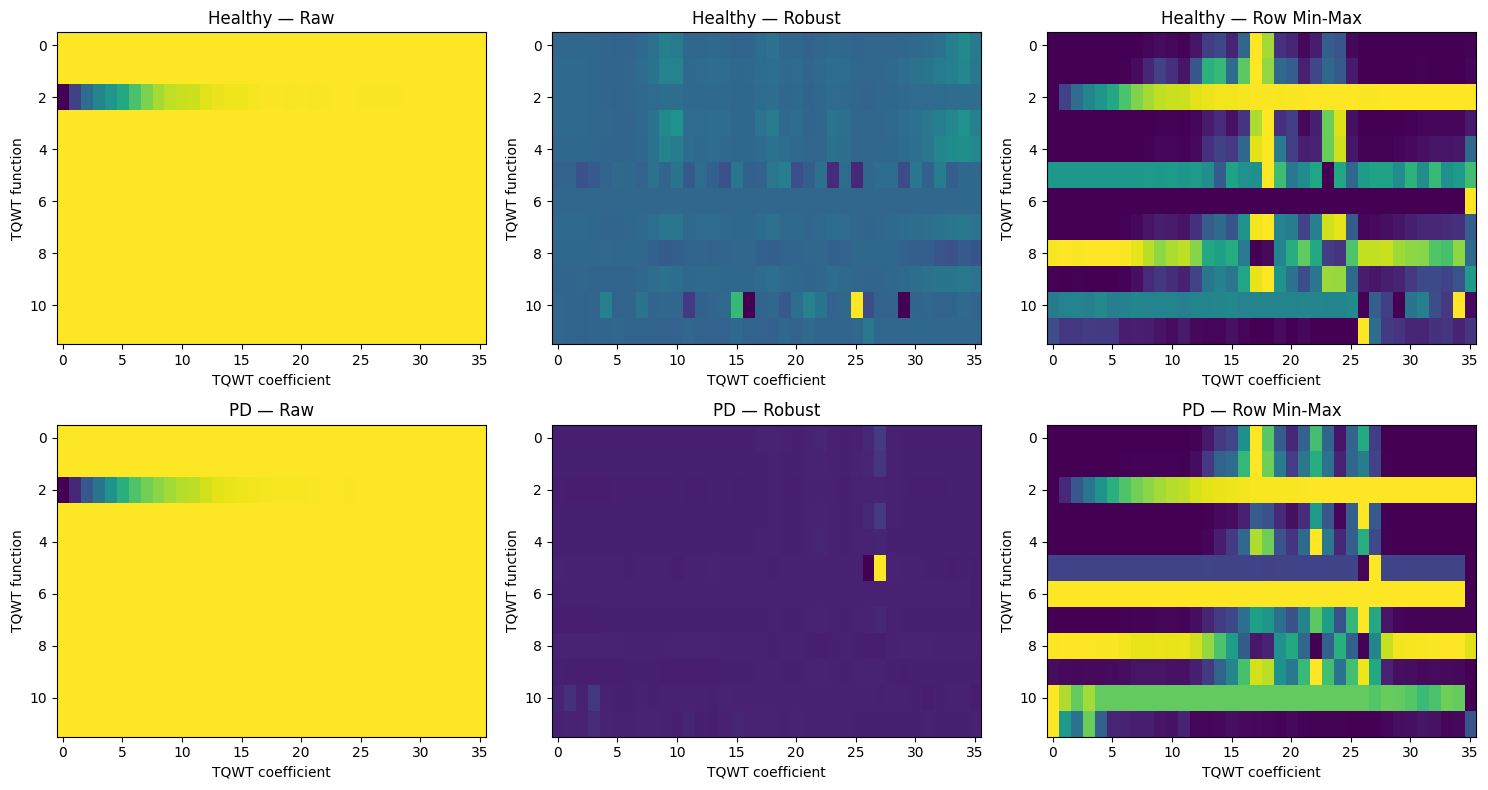

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Healthy
axes[0, 0].imshow(healthy_raw, aspect="auto", cmap="viridis")
axes[0, 0].set_title("Healthy — Raw")

axes[0, 1].imshow(healthy_robust, aspect="auto", cmap="viridis")
axes[0, 1].set_title("Healthy — Robust")

axes[0, 2].imshow(healthy_row_norm, aspect="auto", cmap="viridis")
axes[0, 2].set_title("Healthy — Row Min-Max")

# PD
axes[1, 0].imshow(pd_raw, aspect="auto", cmap="viridis")
axes[1, 0].set_title("PD — Raw")

axes[1, 1].imshow(pd_robust, aspect="auto", cmap="viridis")
axes[1, 1].set_title("PD — Robust")

axes[1, 2].imshow(pd_row_norm, aspect="auto", cmap="viridis")
axes[1, 2].set_title("PD — Row Min-Max")

for ax in axes.flat:
    ax.set_xlabel("TQWT coefficient")
    ax.set_ylabel("TQWT function")

plt.tight_layout()
plt.show()

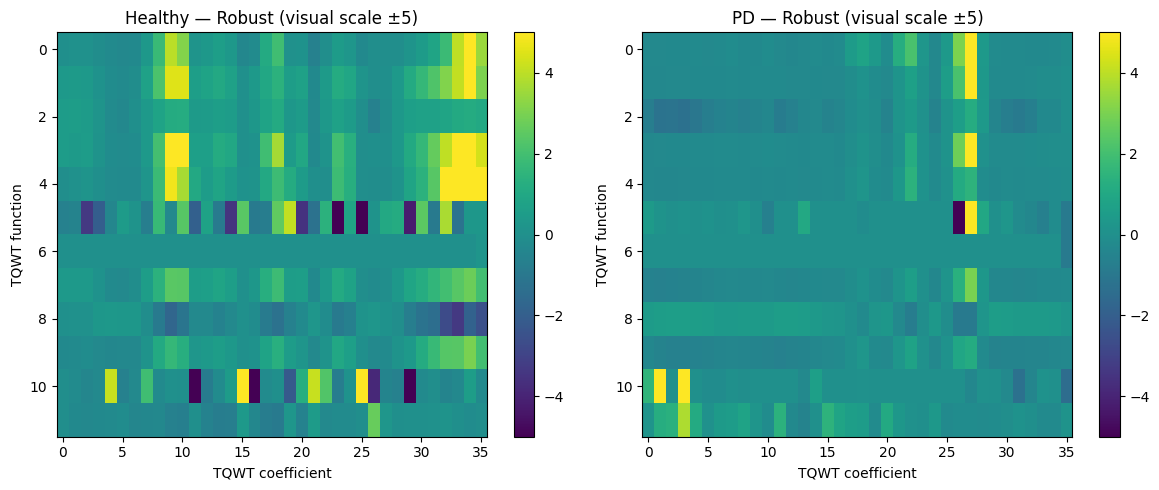

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(
    healthy_robust,
    aspect="auto",
    cmap="viridis",
    vmin=-5,
    vmax=5
)
axes[0].set_title("Healthy — Robust (visual scale ±5)")
axes[0].set_xlabel("TQWT coefficient")
axes[0].set_ylabel("TQWT function")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(
    pd_robust,
    aspect="auto",
    cmap="viridis",
    vmin=-5,
    vmax=5
)
axes[1].set_title("PD — Robust (visual scale ±5)")
axes[1].set_xlabel("TQWT coefficient")
axes[1].set_ylabel("TQWT function")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

In [ ]:
# Canonical TQWT matrix for one recording
sample_idx = 0

sample_matrix = tqwt_tensor[sample_idx]

print("Shape:", sample_matrix.shape)
print("Min:", sample_matrix.min())
print("Max:", sample_matrix.max())

print("\nRows:")
for i, name in enumerate(TQWT_GROUP_ORDER):
    print(f"{i:2d}: {name}")

Shape: (12, 36)
Min: -2037542.2
Max: 541.6719

Rows:
 0: tqwt_energy_dec
 1: tqwt_entropy_shannon_dec
 2: tqwt_entropy_log_dec
 3: tqwt_TKEO_mean_dec
 4: tqwt_TKEO_std_dec
 5: tqwt_medianValue_dec
 6: tqwt_meanValue_dec
 7: tqwt_stdValue_dec
 8: tqwt_minValue_dec
 9: tqwt_maxValue_dec
10: tqwt_skewnessValue_dec
11: tqwt_kurtosisValue_dec


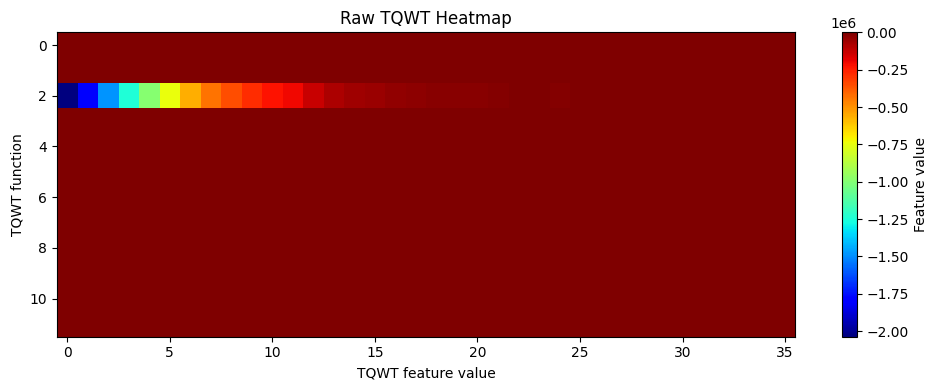

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.imshow(
    sample_matrix,
    aspect="auto",
    cmap="jet"
)

plt.xlabel("TQWT feature value")
plt.ylabel("TQWT function")
plt.title("Raw TQWT Heatmap")

plt.colorbar(label="Feature value")

plt.tight_layout()
plt.show()

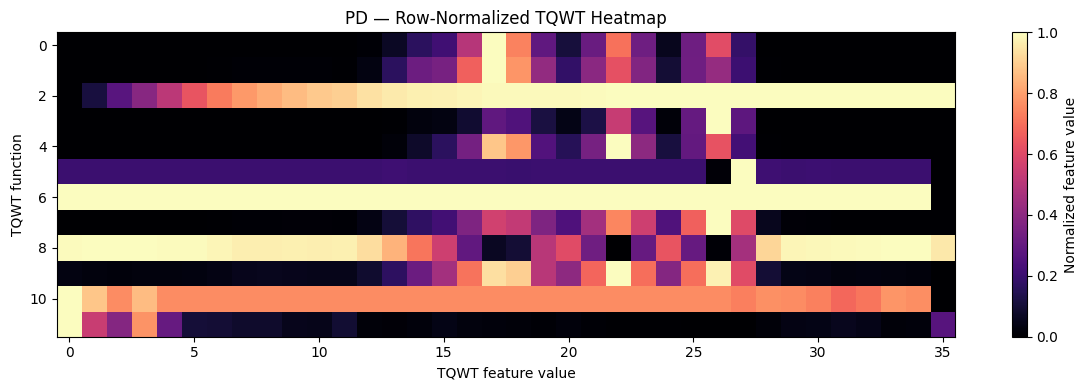

In [ ]:
plt.figure(figsize=(12, 4))

plt.imshow(
    pd_row_norm,
    aspect="auto",
    cmap="magma",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

plt.xlabel("TQWT feature value")
plt.ylabel("TQWT function")
plt.title("PD — Row-Normalized TQWT Heatmap")

plt.colorbar(label="Normalized feature value")

plt.tight_layout()
plt.show()

In [ ]:
def signed_log_transform(matrix):
    return np.sign(matrix) * np.log1p(np.abs(matrix))

pd_log = signed_log_transform(pd_raw)
healthy_log = signed_log_transform(healthy_raw)

print("PD transformed range:",
      pd_log.min(), "to", pd_log.max())

print("Healthy transformed range:",
      healthy_log.min(), "to", healthy_log.max())

PD transformed range: -14.527255 to 6.296505
Healthy transformed range: -14.36384 to 7.1776986


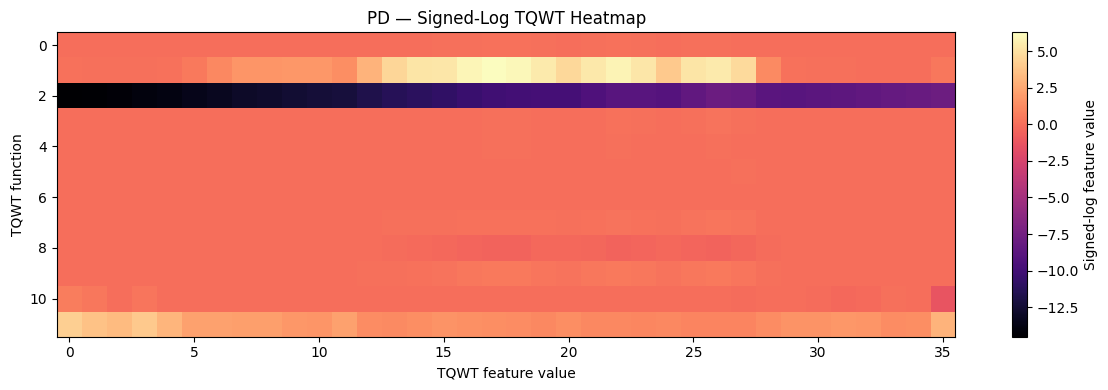

In [ ]:
plt.figure(figsize=(12, 4))

plt.imshow(
    pd_log,
    aspect="auto",
    cmap="magma",
    interpolation="nearest"
)

plt.xlabel("TQWT feature value")
plt.ylabel("TQWT function")
plt.title("PD — Signed-Log TQWT Heatmap")

plt.colorbar(label="Signed-log feature value")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


HEATMAP_WIDTH = 707
HEATMAP_HEIGHT = 263


def matrix_to_heatmap(
    matrix,
    output_path,
    width=HEATMAP_WIDTH,
    height=HEATMAP_HEIGHT,
    cmap="magma",
    vmin=None,
    vmax=None
):
    """
    Convert a 2-D feature matrix into a color-encoded heatmap image.

    No axes, labels, title, or colorbar are included because the
    resulting image will be the CNN input.
    """

    dpi = 100

    fig = plt.figure(
        figsize=(width / dpi, height / dpi),
        dpi=dpi
    )

    # Fill the entire canvas
    ax = fig.add_axes([0, 0, 1, 1])

    ax.imshow(
        matrix,
        aspect="auto",
        cmap=cmap,
        interpolation="nearest",
        vmin=vmin,
        vmax=vmax
    )

    ax.axis("off")

    fig.savefig(
        output_path,
        dpi=dpi,
        pad_inches=0
    )

    plt.close(fig)

In [ ]:
pd_robust = X_robust[pd_idx].reshape(12, 36)

pd_heatmap_path = HEATMAP_DIR / "pd_sample.png"

matrix_to_heatmap(
    pd_robust,
    pd_heatmap_path,
    cmap="magma",
    vmin=-5,
    vmax=5
)

print("Saved:", pd_heatmap_path)

Saved: /content/mtp_parkinsons/data/processed/heatmaps/pd_sample.png


In [ ]:
from PIL import Image

img = Image.open(pd_heatmap_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (707, 263)
Image mode: RGBA


In [ ]:
from PIL import Image

# Load our generated heatmap
img = Image.open(pd_heatmap_path).convert("RGB")

print("Original:", img.size, img.mode)

# Resize to ImageNet / ResNet input size
img_224 = img.resize(
    (224, 224),
    Image.Resampling.BILINEAR
)

# Save
pd_224_path = HEATMAP_DIR / "pd_sample_224.png"
img_224.save(pd_224_path)

print("Resized:", img_224.size, img_224.mode)
print("Saved:", pd_224_path)

Original: (707, 263) RGB
Resized: (224, 224) RGB
Saved: /content/mtp_parkinsons/data/processed/heatmaps/pd_sample_224.png


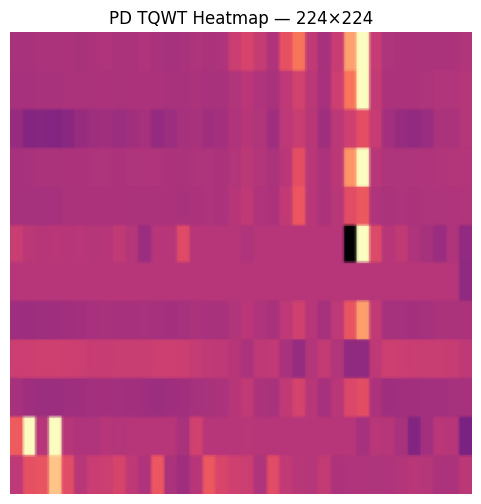

In [ ]:
plt.figure(figsize=(6, 6))
plt.imshow(img_224)
plt.axis("off")
plt.title("PD TQWT Heatmap — 224×224")
plt.show()

In [ ]:
# Generate healthy sample heatmap

healthy_robust = X_robust[healthy_idx].reshape(12, 36)

healthy_heatmap_path = HEATMAP_DIR / "healthy_sample.png"

matrix_to_heatmap(
    healthy_robust,
    healthy_heatmap_path,
    cmap="magma",
    vmin=-5,
    vmax=5
)

# Convert to RGB and resize
healthy_img = Image.open(healthy_heatmap_path).convert("RGB")

healthy_224 = healthy_img.resize(
    (224, 224),
    Image.Resampling.BILINEAR
)

healthy_224_path = HEATMAP_DIR / "healthy_sample_224.png"
healthy_224.save(healthy_224_path)

print("Original:", healthy_img.size)
print("Resized:", healthy_224.size)
print("Saved:", healthy_224_path)

Original: (707, 263)
Resized: (224, 224)
Saved: /content/mtp_parkinsons/data/processed/heatmaps/healthy_sample_224.png


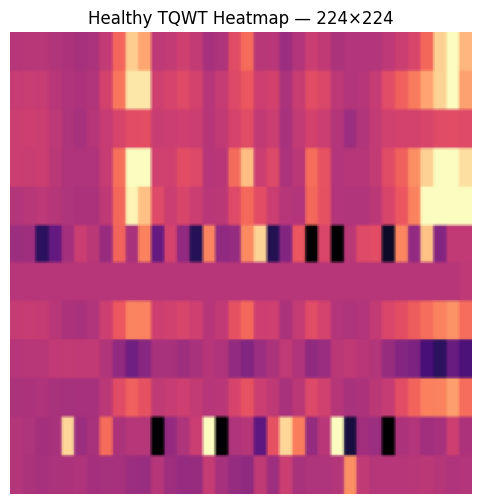

In [ ]:
plt.figure(figsize=(6, 6))
plt.imshow(healthy_224)
plt.axis("off")
plt.title("Healthy TQWT Heatmap — 224×224")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Recording-level split, matching the paper's main experiment
indices = np.arange(len(df))
labels = df["class"].to_numpy()

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

print("Total:", len(indices))
print("Train:", len(train_idx))
print("Test :", len(test_idx))

print("\nTrain class distribution:")
print(df.iloc[train_idx]["class"].value_counts())

print("\nTest class distribution:")
print(df.iloc[test_idx]["class"].value_counts())

Total: 756
Train: 604
Test : 152

Train class distribution:
class
1    451
0    153
Name: count, dtype: int64

Test class distribution:
class
1    113
0     39
Name: count, dtype: int64


In [ ]:
# --------------------------------------------------
# Calculate feature-wise robust statistics
# using TRAINING DATA ONLY
# --------------------------------------------------

X_train_raw = X_tqwt[train_idx]
X_test_raw = X_tqwt[test_idx]

print("Training raw shape:", X_train_raw.shape)
print("Test raw shape:", X_test_raw.shape)

# Feature-wise statistics from TRAINING SET ONLY
train_median = np.median(X_train_raw, axis=0)

train_q1 = np.percentile(X_train_raw, 25, axis=0)
train_q3 = np.percentile(X_train_raw, 75, axis=0)

train_iqr = train_q3 - train_q1

# Features with essentially zero variation
train_valid_features = train_iqr >= EPS

print("\nNear-constant training features:",
      (~train_valid_features).sum())

print("Valid varying features:",
      train_valid_features.sum())

Training raw shape: (604, 432)
Test raw shape: (152, 432)

Near-constant training features: 35
Valid varying features: 397


In [ ]:
# --------------------------------------------------
# Apply training-derived robust normalization
# --------------------------------------------------

X_train_robust = np.zeros_like(X_train_raw, dtype=np.float32)
X_test_robust = np.zeros_like(X_test_raw, dtype=np.float32)

# Training set
X_train_robust[:, train_valid_features] = (
    X_train_raw[:, train_valid_features]
    - train_median[train_valid_features]
) / train_iqr[train_valid_features]

# Test set
X_test_robust[:, train_valid_features] = (
    X_test_raw[:, train_valid_features]
    - train_median[train_valid_features]
) / train_iqr[train_valid_features]

print("Train robust shape:", X_train_robust.shape)
print("Test robust shape :", X_test_robust.shape)

print("\nTrain range:",
      X_train_robust.min(), "to", X_train_robust.max())

print("Test range:",
      X_test_robust.min(), "to", X_test_robust.max())

Train robust shape: (604, 432)
Test robust shape : (152, 432)

Train range: -20012.764 to 9008.1045
Test range: -8888.5 to 13338.695


In [ ]:
# Determine candidate color limits from TRAINING data only

train_p01 = np.percentile(X_train_robust, 1)
train_p05 = np.percentile(X_train_robust, 5)
train_p95 = np.percentile(X_train_robust, 95)
train_p99 = np.percentile(X_train_robust, 99)

print("Training robust percentiles:")
print("  1% :", train_p01)
print("  5% :", train_p05)
print(" 95% :", train_p95)
print(" 99% :", train_p99)

Training robust percentiles:
  1% : -5.353101
  5% : -1.0502243
 95% : 3.1303303
 99% : 15.669776


In [ ]:
# Final color limits derived from TRAINING data only

COLOR_VMIN = train_p01
COLOR_VMAX = train_p99

print("Color range:")
print("vmin =", COLOR_VMIN)
print("vmax =", COLOR_VMAX)

Color range:
vmin = -5.353101
vmax = 15.669776


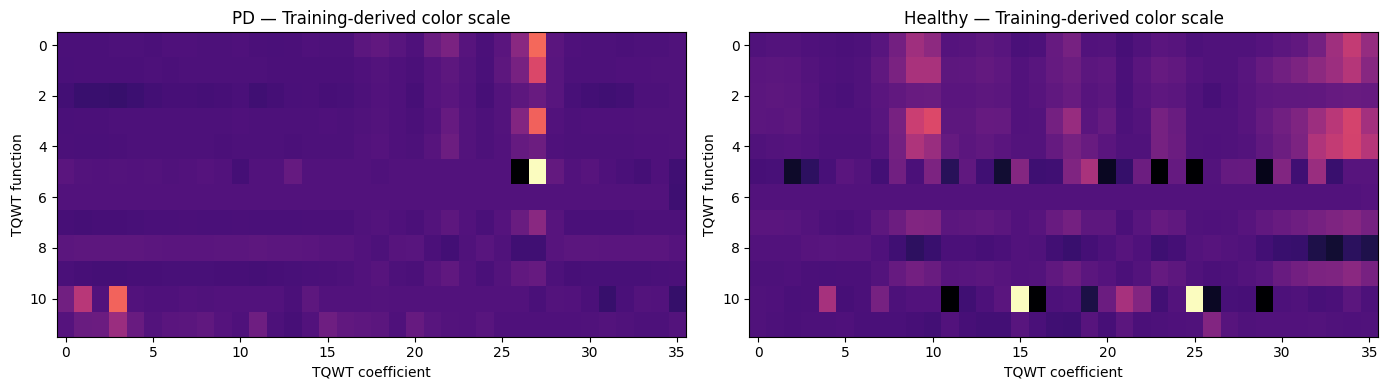

In [ ]:
# --------------------------------------------------
# Preview using the final training-derived color range
# --------------------------------------------------

pd_robust_trainstyle = X_train_robust[
    np.where(train_idx == pd_idx)[0][0]
].reshape(12, 36) if pd_idx in train_idx else None

healthy_robust_trainstyle = X_train_robust[
    np.where(train_idx == healthy_idx)[0][0]
].reshape(12, 36) if healthy_idx in train_idx else None

# If our earlier sample isn't in the training set,
# simply select one sample from each class in TRAIN.
if pd_robust_trainstyle is None:
    pd_train_pos = np.where(
        df.iloc[train_idx]["class"].to_numpy() == 1
    )[0][0]
    pd_robust_trainstyle = X_train_robust[pd_train_pos].reshape(12, 36)

if healthy_robust_trainstyle is None:
    healthy_train_pos = np.where(
        df.iloc[train_idx]["class"].to_numpy() == 0
    )[0][0]
    healthy_robust_trainstyle = X_train_robust[healthy_train_pos].reshape(12, 36)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].imshow(
    pd_robust_trainstyle,
    aspect="auto",
    cmap="magma",
    interpolation="nearest",
    vmin=COLOR_VMIN,
    vmax=COLOR_VMAX
)
axes[0].set_title("PD — Training-derived color scale")
axes[0].set_xlabel("TQWT coefficient")
axes[0].set_ylabel("TQWT function")

axes[1].imshow(
    healthy_robust_trainstyle,
    aspect="auto",
    cmap="magma",
    interpolation="nearest",
    vmin=COLOR_VMIN,
    vmax=COLOR_VMAX
)
axes[1].set_title("Healthy — Training-derived color scale")
axes[1].set_xlabel("TQWT coefficient")
axes[1].set_ylabel("TQWT function")

plt.tight_layout()
plt.show()

In [ ]:
TRAIN_HEATMAP_DIR = PROCESSED_DATA_DIR / "heatmaps_707x263"
TRAIN_IMAGE_DIR = PROCESSED_DATA_DIR / "images_224"

TRAIN_HEATMAP_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Original heatmaps:", TRAIN_HEATMAP_DIR)
print("224x224 images:", TRAIN_IMAGE_DIR)

Original heatmaps: /content/mtp_parkinsons/data/processed/heatmaps_707x263
224x224 images: /content/mtp_parkinsons/data/processed/images_224


In [ ]:
from PIL import Image
import pandas as pd

# --------------------------------------------------
# Generate all 756 heatmaps
# --------------------------------------------------

metadata = []

for idx in range(len(df)):

    # Get robust-normalized 12x36 matrix
    if idx in set(train_idx):
        pos = np.where(train_idx == idx)[0][0]
        matrix = X_train_robust[pos].reshape(12, 36)
        split = "train"
    else:
        pos = np.where(test_idx == idx)[0][0]
        matrix = X_test_robust[pos].reshape(12, 36)
        split = "test"

    # Image name
    image_name = f"recording_{idx:04d}.png"

    # 707x263 path
    heatmap_path = TRAIN_HEATMAP_DIR / image_name

    # 224x224 path
    image_path = TRAIN_IMAGE_DIR / image_name

    # Generate heatmap
    matrix_to_heatmap(
        matrix,
        heatmap_path,
        width=707,
        height=263,
        cmap="magma",
        vmin=COLOR_VMIN,
        vmax=COLOR_VMAX
    )

    # Convert RGBA -> RGB and resize
    img = Image.open(heatmap_path).convert("RGB")

    img_224 = img.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    img_224.save(image_path)

    # Store metadata
    metadata.append({
        "image_name": image_name,
        "recording_index": idx,
        "id": df.iloc[idx]["id"],
        "class": int(df.iloc[idx]["class"]),
        "split": split
    })

metadata_df = pd.DataFrame(metadata)

print("Generated images:", len(metadata_df))
print("\nSplit:")
print(metadata_df["split"].value_counts())

print("\nClass:")
print(metadata_df["class"].value_counts())

Generated images: 756

Split:
split
train    604
test     152
Name: count, dtype: int64

Class:
class
1    564
0    192
Name: count, dtype: int64


In [ ]:
METADATA_PATH = PROCESSED_DATA_DIR / "metadata.csv"

metadata_df.to_csv(
    METADATA_PATH,
    index=False
)

print("Metadata saved to:", METADATA_PATH)

Metadata saved to: /content/mtp_parkinsons/data/processed/metadata.csv


In [ ]:
from PIL import Image
import random

# --------------------------------------------------
# Dataset integrity check
# --------------------------------------------------

print("Metadata rows:", len(metadata_df))
print("Train:", (metadata_df["split"] == "train").sum())
print("Test :", (metadata_df["split"] == "test").sum())

print("\nClass distribution:")
print(metadata_df.groupby(["split", "class"]).size())

print("\nChecking image files...")

missing = []
bad_dimensions = []
bad_modes = []

for _, row in metadata_df.iterrows():
    path = TRAIN_IMAGE_DIR / row["image_name"]

    if not path.exists():
        missing.append(row["image_name"])
        continue

    img = Image.open(path)

    if img.size != (224, 224):
        bad_dimensions.append(
            (row["image_name"], img.size)
        )

    if img.mode != "RGB":
        bad_modes.append(
            (row["image_name"], img.mode)
        )

print("Missing files:", len(missing))
print("Wrong dimensions:", len(bad_dimensions))
print("Wrong modes:", len(bad_modes))

Metadata rows: 756
Train: 604
Test : 152

Class distribution:
split  class
test   0         39
       1        113
train  0        153
       1        451
dtype: int64

Checking image files...
Missing files: 0
Wrong dimensions: 0
Wrong modes: 0


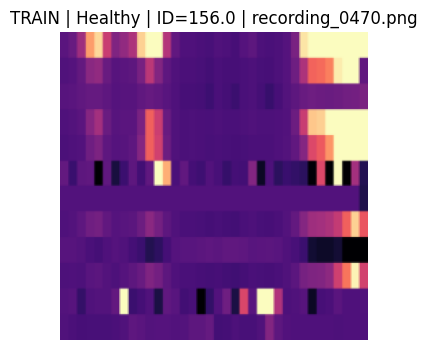

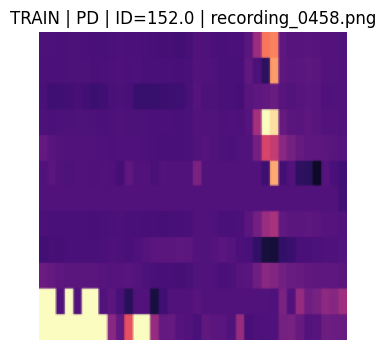

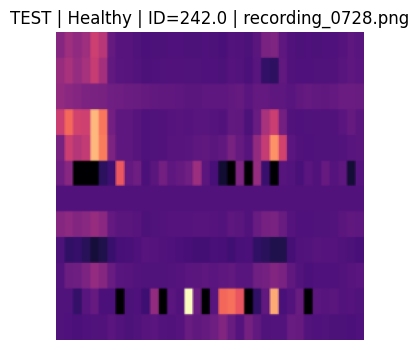

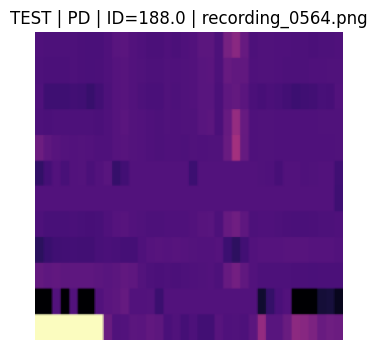

In [ ]:
# Random samples from each split/class combination

for split in ["train", "test"]:
    for cls in [0, 1]:

        subset = metadata_df[
            (metadata_df["split"] == split) &
            (metadata_df["class"] == cls)
        ]

        row = subset.sample(
            n=1,
            random_state=SEED
        ).iloc[0]

        path = TRAIN_IMAGE_DIR / row["image_name"]
        img = Image.open(path)

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis("off")

        label = "PD" if cls == 1 else "Healthy"

        plt.title(
            f"{split.upper()} | {label} | "
            f"ID={row['id']} | {row['image_name']}"
        )

        plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ImageNet normalization for pretrained ResNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Transform ready.")

Transform ready.


In [ ]:
class ParkinsonHeatmapDataset(Dataset):

    def __init__(self, metadata_df, image_dir, transform=None):
        self.metadata = metadata_df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):

        row = self.metadata.iloc[idx]

        image_path = self.image_dir / row["image_name"]

        image = Image.open(image_path).convert("RGB")

        label = int(row["class"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [ ]:
train_metadata = metadata_df[
    metadata_df["split"] == "train"
].copy()

test_metadata = metadata_df[
    metadata_df["split"] == "test"
].copy()

train_dataset = ParkinsonHeatmapDataset(
    train_metadata,
    TRAIN_IMAGE_DIR,
    transform=image_transform
)

test_dataset = ParkinsonHeatmapDataset(
    test_metadata,
    TRAIN_IMAGE_DIR,
    transform=image_transform
)

print("Train dataset:", len(train_dataset))
print("Test dataset :", len(test_dataset))

Train dataset: 604
Test dataset : 152


In [ ]:
sample_image, sample_label = train_dataset[0]

print("Tensor shape:", sample_image.shape)
print("Tensor dtype:", sample_image.dtype)
print("Label:", sample_label)

print(
    "Tensor range:",
    sample_image.min().item(),
    "to",
    sample_image.max().item()
)

Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32
Label: 1
Tensor range: -2.1179039478302 to 2.3760502338409424


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

Train batches: 19
Test batches : 5


In [ ]:
images, labels_batch = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels_batch.shape)

print("Image dtype:", images.dtype)
print("Labels dtype:", labels_batch.dtype)

print(
    "Image range:",
    images.min().item(),
    "to",
    images.max().item()
)

print("Labels:", labels_batch.tolist())

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Labels dtype: torch.int64
Image range: -2.1179039478302 to 2.3760502338409424
Labels: [1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1]


In [ ]:
import torchvision.models as models
from torchvision.models import ResNet50_Weights

# Load ImageNet-pretrained ResNet50
weights = ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(weights=weights)

# Replace the final classifier
num_features = model.fc.in_features

model.fc = torch.nn.Linear(
    num_features,
    2
)

model = model.to(DEVICE)

print(model.fc)
print("Device:", DEVICE)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 114MB/s]


Linear(in_features=2048, out_features=2, bias=True)
Device: cuda


In [ ]:
# --------------------------------------------------
# Stage 1: Freeze the ResNet50 backbone
# --------------------------------------------------

for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in model.fc.parameters():
    param.requires_grad = True

# Check trainable parameters
trainable_params = [
    (name, param)
    for name, param in model.named_parameters()
    if param.requires_grad
]

print("Trainable parameters:")
for name, param in trainable_params:
    print(f"{name:30s} {tuple(param.shape)}")

total_trainable = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

total_params = sum(
    param.numel()
    for param in model.parameters()
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{total_trainable:,}")

Trainable parameters:
fc.weight                      (2, 2048)
fc.bias                        (2,)

Total parameters: 23,512,130
Trainable parameters: 4,098


In [ ]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

# Stage 1 learning rate from the paper
STAGE1_MAX_LR = 0.3

optimizer = torch.optim.SGD(
    model.fc.parameters(),
    lr=STAGE1_MAX_LR,
    momentum=0.9
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.3
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)


In [ ]:
STAGE1_EPOCHS = 15

steps_per_epoch = len(train_loader)
total_steps = STAGE1_EPOCHS * steps_per_epoch

print("Steps per epoch:", steps_per_epoch)
print("Total Stage 1 steps:", total_steps)

Steps per epoch: 19
Total Stage 1 steps: 285


In [ ]:
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=STAGE1_MAX_LR,
    total_steps=total_steps,
    pct_start=0.3,
    anneal_strategy="cos",
    div_factor=25,
    final_div_factor=1e4
)

print("OneCycleLR created.")

OneCycleLR created.


In [ ]:
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

In [ ]:
def train_stage1(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    scheduler,
    device,
    epochs
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
        "lr": []
    }

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()
            scheduler.step()

            running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        test_loss, test_acc = evaluate(
            model,
            test_loader,
            criterion,
            device
        )

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        history["lr"].append(current_lr)

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.4f} | "
            f"LR: {current_lr:.6f}"
        )

    return history

In [ ]:
stage1_history = train_stage1(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    device=DEVICE,
    epochs=STAGE1_EPOCHS
)

Epoch 01/15 | Train Loss: 0.5860 | Train Acc: 0.7533 | Test Loss: 0.5513 | Test Acc: 0.7434 | LR: 0.046458
Epoch 02/15 | Train Loss: 0.4635 | Train Acc: 0.7930 | Test Loss: 0.5199 | Test Acc: 0.7500 | LR: 0.133341
Epoch 03/15 | Train Loss: 0.3418 | Train Acc: 0.8444 | Test Loss: 0.7912 | Test Acc: 0.6118 | LR: 0.231069
Epoch 04/15 | Train Loss: 0.3425 | Train Acc: 0.8576 | Test Loss: 1.1878 | Test Acc: 0.7566 | LR: 0.292869
Epoch 05/15 | Train Loss: 0.6843 | Train Acc: 0.7765 | Test Loss: 1.0308 | Test Acc: 0.7763 | LR: 0.297954
Epoch 06/15 | Train Loss: 0.2503 | Train Acc: 0.9073 | Test Loss: 0.7846 | Test Acc: 0.7632 | LR: 0.284104
Epoch 07/15 | Train Loss: 0.2255 | Train Acc: 0.9056 | Test Loss: 1.0837 | Test Acc: 0.7500 | LR: 0.258338
Epoch 08/15 | Train Loss: 0.2993 | Train Acc: 0.8874 | Test Loss: 0.7944 | Test Acc: 0.7105 | LR: 0.222945
Epoch 09/15 | Train Loss: 0.1680 | Train Acc: 0.9387 | Test Loss: 1.0352 | Test Acc: 0.7632 | LR: 0.181072
Epoch 10/15 | Train Loss: 0.1098 | Tr

In [ ]:
# Save Stage 1 checkpoint
STAGE1_CHECKPOINT = CHECKPOINT_DIR / "resnet50_stage1.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "stage1_history": stage1_history,
    "best_test_acc": max(stage1_history["test_acc"]),
    "best_epoch": np.argmax(stage1_history["test_acc"]) + 1,
}, STAGE1_CHECKPOINT)

print("Stage 1 checkpoint saved to:", STAGE1_CHECKPOINT)
print(
    f"Best Stage 1 test accuracy: "
    f"{max(stage1_history['test_acc']):.4f} "
    f"(epoch {np.argmax(stage1_history['test_acc']) + 1})"
)

Stage 1 checkpoint saved to: /content/mtp_parkinsons/checkpoints/resnet50_stage1.pth
Best Stage 1 test accuracy: 0.7961 (epoch 10)


In [ ]:
# --------------------------------------------------
# Stage 2: Unfreeze the entire ResNet50
# --------------------------------------------------

for param in model.parameters():
    param.requires_grad = True

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

print("Trainable parameters:", f"{trainable_params:,}")
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Trainable parameters: 23,512,130
Total parameters: 23,512,130


In [ ]:
STAGE2_EPOCHS = 10
STAGE2_MAX_LR = 0.03

optimizer_stage2 = torch.optim.SGD(
    model.parameters(),
    lr=STAGE2_MAX_LR,
    momentum=0.9
)

steps_stage2 = STAGE2_EPOCHS * len(train_loader)

print("Stage 2 epochs:", STAGE2_EPOCHS)
print("Steps:", steps_stage2)
print("Maximum LR:", STAGE2_MAX_LR)

Stage 2 epochs: 10
Steps: 190
Maximum LR: 0.03


In [ ]:
scheduler_stage2 = torch.optim.lr_scheduler.OneCycleLR(
    optimizer_stage2,
    max_lr=STAGE2_MAX_LR,
    total_steps=steps_stage2,
    pct_start=0.3,
    anneal_strategy="cos",
    div_factor=25,
    final_div_factor=1e4
)

print("Stage 2 scheduler ready.")

Stage 2 scheduler ready.


In [ ]:
train_model = train_stage1

In [ ]:
stage2_history = train_model(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer_stage2,
    scheduler=scheduler_stage2,
    device=DEVICE,
    epochs=STAGE2_EPOCHS
)

Epoch 01/10 | Train Loss: 0.5881 | Train Acc: 0.7881 | Test Loss: 56.5037 | Test Acc: 0.6842 | LR: 0.008634
Epoch 02/10 | Train Loss: 0.6143 | Train Acc: 0.7715 | Test Loss: 63.9772 | Test Acc: 0.7171 | LR: 0.023261
Epoch 03/10 | Train Loss: 0.4672 | Train Acc: 0.8195 | Test Loss: 3.3949 | Test Acc: 0.7039 | LR: 0.029996
Epoch 04/10 | Train Loss: 0.3409 | Train Acc: 0.8642 | Test Loss: 1.0617 | Test Acc: 0.7763 | LR: 0.028357
Epoch 05/10 | Train Loss: 0.1360 | Train Acc: 0.9487 | Test Loss: 0.6041 | Test Acc: 0.8289 | LR: 0.024073
Epoch 06/10 | Train Loss: 0.0600 | Train Acc: 0.9818 | Test Loss: 0.7771 | Test Acc: 0.8158 | LR: 0.017992
Epoch 07/10 | Train Loss: 0.0114 | Train Acc: 1.0000 | Test Loss: 0.7119 | Test Acc: 0.8289 | LR: 0.011318
Epoch 08/10 | Train Loss: 0.0051 | Train Acc: 1.0000 | Test Loss: 0.7261 | Test Acc: 0.8355 | LR: 0.005373
Epoch 09/10 | Train Loss: 0.0041 | Train Acc: 1.0000 | Test Loss: 0.7898 | Test Acc: 0.8421 | LR: 0.001336
Epoch 10/10 | Train Loss: 0.0029 | 

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
balanced_acc = balanced_accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1 Score:          {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Healthy", "PD"]
))

Accuracy:          0.8355
Balanced Accuracy: 0.7383
Precision:         0.8548
Recall:            0.9381
F1 Score:          0.8945

Confusion Matrix:
[[ 21  18]
 [  7 106]]

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.75      0.54      0.63        39
          PD       0.85      0.94      0.89       113

    accuracy                           0.84       152
   macro avg       0.80      0.74      0.76       152
weighted avg       0.83      0.84      0.83       152



# Part B — Thesis pipeline: speaker-independent PD detection (Bengali focus)

Part A above is the earlier UCI / TQWT / ResNet50 reproduction, kept as is. Part B is the thesis pipeline from the plan doc.

**Non-negotiable protocol** (everything below enforces it):
1. Splits are always by **speaker** (leave-one-speaker-out or stratified group k-fold). A random split is run only to *measure* leakage.
2. Scalers, feature selection, tuning and thresholds are fitted inside the training fold only (sklearn Pipelines).
3. Segment probabilities are averaged per speaker; **speaker-level** balanced accuracy / AUC are the headline numbers, with bootstrap CIs.

| Section | What | Data |
|---|---|---|
| B1 | Setup | – |
| B2 | Data: MDVR-KCL (English), BenSParX (Bengali) | Zenodo, GitHub |
| B3 | Preprocessing, features, evaluation toolkit | – |
| B4 | Leakage audit: UCI #470 (your Part A data) | UCI |
| B5 | Leakage audit + baselines: MDVR-KCL | Zenodo |
| B6 | Bengali: BenSParX | GitHub |
| B7 | Frozen SSL layer probe (wav2vec2 / WavLM / XLS-R / IndicWav2Vec) | GPU |

Note: files go to /content/thesis, which is wiped when the runtime resets. Mount Drive (B1, optional) to keep caches.

### Results so far (first session, 21 Nov 2026)

Speaker-level balanced accuracy (BA); every number comes from a cell in Part B. Figure: B8.

| Dataset | Features / model | Leaky split (as in prior work) | Speaker-independent | Cell |
|---|---|---|---|---|
| UCI #470 (Part A data, 252 subjects) | all 754, XGB/logreg | 0.86 (recording-level 5-fold) | **0.78** (subject-grouped 5-fold) | B4 |
| UCI #470 | TQWT 432, XGB | 0.78 | **0.73** | B4 |
| UCI #470 | ResNet50 on TQWT heatmaps (Part A idea), 3 seeds | 0.70, AUC 0.85 | **0.64**, AUC 0.70 | B10 |
| MDVR-KCL ReadText (37 spk) | eGeMAPS | 1.00 (random 4 s chunks) | **0.85**, AUC 0.89 (SVM, LOSO) | B5c |
| MDVR-KCL Dialogue (36 spk) | eGeMAPS | 0.97 | **0.82** (LOSO) | B5c |
| MDVR-KCL ReadText / Dialogue | frozen SSL linear probe, best layer | – | AUC 0.92–0.935 (XLS-R, MMS, wav2vec2, WavLM) | B7b |
| MDVR-KCL ReadText | eGeMAPS on **silence only** | – | 0.54–0.64 (≈ chance: result is the voice) | B9 |
| BenSParX (Bengali, 120 spk) | 71 published features | 1.00 (authors' grouping = segment id) | 1.00 (speaker 10-fold / LOSO) | B6b |

Key points:
1. **Leakage is large.** Random-chunk splits give 100% on MDVR-KCL; the honest number is 0.85. Part A's recording-level split inflates ResNet50 by ~6 BA points and 0.14 AUC, and under a subject split the image model falls below plain XGBoost on the same features.
2. **MDVR-KCL ReadText is clean** (silence-only ≈ chance), so it is the primary English benchmark. Dialogue leaks a little through the far-end audio (silence-only up to 0.70).
3. **BenSParX is probably confounded:** 15 of 71 features alone reach speaker AUC > 0.90, led by channel / noise-floor markers (B6c). Use it with that caveat; the main Bengali result needs condition-matched recordings.
4. **SSL probes are strong** (AUC ≥ 0.92 with a linear probe, no fine-tuning), on par with or above eGeMAPS. Fine-tuning (Phase 3) is the next step.
5. IndicWav2Vec is gated on Hugging Face: accept its terms and add an HF_TOKEN secret, then uncomment it in B7a. MMS-300m is the open multilingual stand-in.

In [ ]:
# B1 · Setup
!pip -q install opensmile praat-parselmouth ucimlrepo xgboost 2>&1 | tail -1
import os, re, json, glob, zipfile, warnings, subprocess, time
from pathlib import Path
import numpy as np, pandas as pd, librosa, soundfile as sf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

USE_DRIVE = False          # set True to cache features in Google Drive (asks for authorisation)
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    TROOT = Path("/content/drive/MyDrive/thesis_pd")
else:
    TROOT = Path("/content/thesis")
DATA, FEAT, RES = TROOT/"data", TROOT/"features", TROOT/"results"
for p in (DATA, FEAT, RES): p.mkdir(parents=True, exist_ok=True)
SR = 16_000
SEED = 42
np.random.seed(SEED)
print("root:", TROOT)

root: /content/thesis


In [ ]:
# B2 · Data download: MDVR-KCL (Zenodo 2867216) and BenSParX (GitHub)
import requests
rec = requests.get("https://zenodo.org/api/records/2867216", timeout=60).json()
for f in rec["files"]:
    name, url = f["key"], f["links"]["self"]
    out = DATA/name
    if not out.exists():
        print("downloading", name, round(f["size"]/1e6, 1), "MB")
        with requests.get(url, stream=True, timeout=600) as r:
            with open(out, "wb") as fh:
                for chunk in r.iter_content(1 << 20): fh.write(chunk)
    if name.endswith(".zip"):
        with zipfile.ZipFile(out) as z: z.extractall(DATA/"MDVR-KCL")
KCL_ROOT = DATA/"MDVR-KCL"
print("wav files:", len(list(KCL_ROOT.rglob("*.wav"))))
for p in sorted({w.parent for w in KCL_ROOT.rglob("*.wav")}): print(" ", p.relative_to(KCL_ROOT), len(list(p.glob("*.wav"))))

BEN_ROOT = DATA/"BenSParX"
if not BEN_ROOT.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Riad071/BenSParX", str(BEN_ROOT)], check=True)
print("\nBenSParX repo:")
for p in sorted(BEN_ROOT.rglob("*")):
    if ".git" not in p.parts: print(" ", p.relative_to(BEN_ROOT), p.stat().st_size if p.is_file() else "")

downloading 26_29_09_2017_KCL.zip 606.1 MB
wav files: 73
  26-29_09_2017_KCL/ReadText/HC 21
  26-29_09_2017_KCL/ReadText/PD 16
  26-29_09_2017_KCL/SpontaneousDialogue/HC 21
  26-29_09_2017_KCL/SpontaneousDialogue/PD 15

BenSParX repo:
  BenSParX.csv 702248
  LICENSE 1064
  README.md 1361
  bensparx_nested_cv.py 15705


In [ ]:
# B3 · Toolkit: preprocessing, features, speaker-independent evaluation, classifiers
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, recall_score,
                             f1_score, matthews_corrcoef)
from xgboost import XGBClassifier

# ---------- audio
def load_audio(path, sr=SR):
    y, _ = librosa.load(path, sr=sr, mono=True)
    return y.astype(np.float32)

def rms_normalize(y, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(y**2)) + 1e-9
    return np.clip(y * (10**(target_dbfs/20) / rms), -1, 1)

def speech_intervals(y, sr=SR, top_db=30, merge_gap_s=0.25, min_len_s=0.3):
    iv = librosa.effects.split(y, top_db=top_db, frame_length=1024, hop_length=256)
    merged = []
    for s, e in iv:
        if merged and s - merged[-1][1] < merge_gap_s*sr: merged[-1][1] = e
        else: merged.append([s, e])
    return [m for m in merged if m[1]-m[0] >= min_len_s*sr]

def apply_mode(y, mode="speech"):
    """speech = VAD speech only | full | silence = non-speech only (confound control)"""
    if mode == "full": return y
    iv = speech_intervals(y)
    if mode == "speech": return np.concatenate([y[s:e] for s, e in iv]) if iv else y
    mask = np.ones(len(y), bool)
    for s, e in iv: mask[s:e] = False
    return y[mask]

def chunk(y, sr=SR, win_s=4.0, hop_s=2.0):
    win, hop = int(win_s*sr), int(hop_s*sr)
    if len(y) <= win: return [np.pad(y, (0, win-len(y)))]
    return [y[i:i+win] for i in range(0, len(y)-win+1, hop)]

# ---------- handcrafted features
def mfcc_stats(y, sr=SR):
    m = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=400, hop_length=160)
    d1, d2 = librosa.feature.delta(m), librosa.feature.delta(m, order=2)
    extra = [librosa.feature.zero_crossing_rate(y).mean(), librosa.feature.rms(y=y).std(),
             librosa.feature.spectral_centroid(y=y, sr=sr).mean(),
             librosa.feature.spectral_bandwidth(y=y, sr=sr).mean(),
             librosa.feature.spectral_rolloff(y=y, sr=sr).mean(),
             librosa.feature.spectral_flatness(y=y).mean()]
    return np.concatenate([m.mean(1), m.std(1), d1.mean(1), d1.std(1), d2.mean(1), d2.std(1), extra]).astype(np.float32)

import opensmile
_smile = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,
                         feature_level=opensmile.FeatureLevel.Functionals)
def egemaps(y, sr=SR):
    return _smile.process_signal(y, sr).values.ravel().astype(np.float32)

EXTRACTORS = {"mfcc": mfcc_stats, "egemaps": egemaps}

# ---------- evaluation
def splits(y, groups, scheme="loso", n_splits=5, seed=0):
    if scheme == "loso": return list(LeaveOneGroupOut().split(y, y, groups))
    if scheme == "group_kfold": return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(y, y, groups))
    if scheme == "random_segment": return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(y, y))
    raise ValueError(scheme)

def _auc(y, p):
    """Mann-Whitney AUC (ties averaged), fast numpy."""
    r = pd.Series(p).rank().values; n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1*(n1+1)/2) / (n1*n0) if n1 and n0 else np.nan

def metrics(y, p, thr=0.5):
    y, p = np.asarray(y).astype(int), np.asarray(p, float); yh = (p >= thr).astype(int)
    tp = int(((yh == 1) & (y == 1)).sum()); tn = int(((yh == 0) & (y == 0)).sum())
    fp = int(((yh == 1) & (y == 0)).sum()); fn = int(((yh == 0) & (y == 1)).sum())
    sens = tp/(tp+fn) if tp+fn else 0.0; spec = tn/(tn+fp) if tn+fp else 0.0
    f1 = 2*tp/(2*tp+fp+fn) if tp else 0.0
    den = np.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)))
    return dict(bal_acc=(sens+spec)/2, auc=_auc(y, p), sens=sens, spec=spec, f1=f1,
                mcc=(tp*tn-fp*fn)/den if den else 0.0)

def bootstrap_ci(y, p, n=1000, seed=0, thr=0.5):
    """95% CI of speaker-level balanced accuracy, resampling speakers (vectorised)."""
    rng = np.random.default_rng(seed); y = np.asarray(y).astype(int); yh = (np.asarray(p) >= thr).astype(int)
    idx = rng.integers(0, len(y), (n, len(y))); Y, YH = y[idx], yh[idx]
    pos, neg = Y.sum(1), (1-Y).sum(1); ok = (pos > 0) & (neg > 0)
    sens = ((YH == 1) & (Y == 1)).sum(1)[ok] / pos[ok]; spec = ((YH == 0) & (Y == 0)).sum(1)[ok] / neg[ok]
    return np.percentile((sens+spec)/2, [2.5, 97.5])

def cross_validate(pipe, X, y, groups, scheme="loso", n_splits=5, seed=0):
    X, y, groups = np.asarray(X), np.asarray(y), np.asarray(groups)
    oof = np.full(len(y), np.nan)
    for tr, te in splits(y, groups, scheme, n_splits, seed):
        if scheme != "random_segment":
            assert not set(groups[tr]) & set(groups[te]), "speaker leakage!"
        oof[te] = clone(pipe).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    seg = pd.DataFrame(dict(speaker=groups, y=y, prob=oof))
    spk = seg.groupby("speaker").agg(y=("y", "first"), prob=("prob", "mean"))
    return dict(seg=metrics(seg.y, seg.prob), spk=metrics(spk.y, spk.prob),
                spk_ci=bootstrap_ci(spk.y, spk.prob), spk_table=spk)

import torch
XGB_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
def _pre(): return [SimpleImputer(strategy="median"), StandardScaler()]
MODELS = {
    "logreg": lambda: make_pipeline(*_pre(), LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced")),
    "svm":    lambda: make_pipeline(*_pre(), SVC(C=1.0, probability=True, class_weight="balanced", random_state=0)),
    "rf":     lambda: make_pipeline(*_pre(), RandomForestClassifier(500, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=0)),
    "knn":    lambda: make_pipeline(*_pre(), KNeighborsClassifier(5)),
    "xgb":    lambda: make_pipeline(*_pre(), XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                         colsample_bytree=0.5, eval_metric="logloss", tree_method="hist", device=XGB_DEVICE, random_state=0)),
}

RESULTS = []
def audit(X, y, groups, name, schemes=("random_segment", "group_kfold", "loso"), models=MODELS, n_splits=5):
    """Runs every model under every split scheme and logs speaker-level numbers."""
    rows = []
    for scheme in schemes:
        for m in models:
            r = cross_validate(MODELS[m](), X, y, groups, scheme, n_splits)
            row = dict(dataset=name, scheme=scheme, model=m,
                       seg_bal_acc=r["seg"]["bal_acc"], spk_bal_acc=r["spk"]["bal_acc"],
                       spk_ci_lo=r["spk_ci"][0], spk_ci_hi=r["spk_ci"][1], spk_auc=r["spk"]["auc"],
                       spk_sens=r["spk"]["sens"], spk_spec=r["spk"]["spec"])
            rows.append(row); RESULTS.append(row)
            print(f"  {name:22s} {scheme:15s} {m:7s} spk_bal_acc={row['spk_bal_acc']:.3f} spk_auc={row['spk_auc']:.3f}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(RES/f"audit_{name}.csv", index=False)
    return df.round(3)

print("toolkit ready")

toolkit ready


## B4 · Leakage audit on UCI #470 (the Part A data)

Part A split the 756 **recordings** at random (cell "Recording-level split, matching the paper"). Each of the 252 subjects has 3 recordings, so the same person usually sits in both train and test. Here the same features are classified two ways: recording-level 5-fold (leaky, like the paper) vs subject-grouped 5-fold (honest). The gap is evidence for RQ1.

In [ ]:
# B4 · UCI #470: recording-level vs subject-level evaluation
UCI_DIR = DATA/"uci470"; UCI_DIR.mkdir(exist_ok=True)
csvs = list(UCI_DIR.rglob("pd_speech_features.csv"))
if not csvs:
    subprocess.run("apt-get -qq install -y unrar > /dev/null", shell=True)
    subprocess.run(["wget", "-q", "-O", str(UCI_DIR/"uci.zip"),
                    "https://archive.ics.uci.edu/static/public/470/parkinson+s+disease+classification.zip"], check=True)
    with zipfile.ZipFile(UCI_DIR/"uci.zip") as z: z.extractall(UCI_DIR)
    for rar in UCI_DIR.rglob("*.rar"): subprocess.run(["unrar", "x", "-o+", "-inul", str(rar), str(UCI_DIR)+"/"], check=True)
    csvs = list(UCI_DIR.rglob("pd_speech_features.csv"))
uci = pd.read_csv(csvs[0], header=1)
y_uci, g_uci = uci["class"].values, uci["id"].values
X_all = uci.drop(columns=["id", "class"]).values
X_tqwt = uci[[c for c in uci.columns if c.startswith("tqwt")]].values
print(uci.shape, "subjects:", len(set(g_uci)), "| PD subjects:", uci.groupby("id")["class"].first().sum())

uci_all  = audit(X_all,  y_uci, g_uci, "UCI470_all754",  schemes=("random_segment", "group_kfold"))
uci_tqwt = audit(X_tqwt, y_uci, g_uci, "UCI470_tqwt432", schemes=("random_segment", "group_kfold"))
show = ["dataset", "scheme", "model", "seg_bal_acc", "spk_bal_acc", "spk_ci_lo", "spk_ci_hi", "spk_auc"]
display(pd.concat([uci_all, uci_tqwt])[show])

(756, 755) subjects: 252 | PD subjects: 188
  UCI470_all754          random_segment  logreg  spk_bal_acc=0.859 spk_auc=0.940
  UCI470_all754          random_segment  svm     spk_bal_acc=0.791 spk_auc=0.918
  UCI470_all754          random_segment  rf      spk_bal_acc=0.773 spk_auc=0.951
  UCI470_all754          random_segment  knn     spk_bal_acc=0.768 spk_auc=0.961
  UCI470_all754          random_segment  xgb     spk_bal_acc=0.818 spk_auc=0.978
  UCI470_all754          group_kfold     logreg  spk_bal_acc=0.730 spk_auc=0.843
  UCI470_all754          group_kfold     svm     spk_bal_acc=0.702 spk_auc=0.832
  UCI470_all754          group_kfold     rf      spk_bal_acc=0.705 spk_auc=0.866
  UCI470_all754          group_kfold     knn     spk_bal_acc=0.664 spk_auc=0.831
  UCI470_all754          group_kfold     xgb     spk_bal_acc=0.776 spk_auc=0.899
  UCI470_tqwt432         random_segment  logreg  spk_bal_acc=0.762 spk_auc=0.869
  UCI470_tqwt432         random_segment  svm     spk_bal_acc=0.75

,dataset,scheme,model,seg_bal_acc,spk_bal_acc,spk_ci_lo,spk_ci_hi,spk_auc
0,UCI470_all754,random_segment,logreg,0.793,0.859,0.804,0.910,0.940
1,UCI470_all754,random_segment,svm,0.742,0.791,0.726,0.852,0.918
2,UCI470_all754,random_segment,rf,0.762,0.773,0.711,0.830,0.951
3,UCI470_all754,random_segment,knn,0.763,0.768,0.701,0.831,0.961
4,UCI470_all754,random_segment,xgb,0.821,0.818,0.756,0.877,0.978
5,UCI470_all754,group_kfold,logreg,0.714,0.730,0.661,0.791,0.843
6,UCI470_all754,group_kfold,svm,0.706,0.702,0.639,0.765,0.832
7,UCI470_all754,group_kfold,rf,0.694,0.705,0.642,0.763,0.866
8,UCI470_all754,group_kfold,knn,0.662,0.664,0.605,0.721,0.831
9,UCI470_all754,group_kfold,xgb,0.749,0.776,0.713,0.838,0.899


## B5 · MDVR-KCL (English): metadata, features, leakage audit + baselines

Gate G0: speaker counts must match 16 PD / 21 HC per task. Each recording is cut into VAD speech-only 4 s chunks (2 s hop). eGeMAPS (88) and MFCC statistics (84) are extracted per chunk. Each classifier runs under a random chunk split (leaky, like Torghabeh et al. and Zhao et al.) and under leave-one-speaker-out.

In [ ]:
# B5a · MDVR-KCL metadata (gate G0)
KCL_RE = re.compile(r"ID(\d+)_?(hc|pd)_(\d+)_(\d+)_(\d+)", re.I)
rows = []
for w in sorted(KCL_ROOT.rglob("*.wav")):
    parts = [p.lower() for p in w.parts]
    task = "ReadText" if any("readtext" in p for p in parts) else "Dialogue"
    m = KCL_RE.search(w.stem)
    if not m: print("unparsed:", w.name); continue
    rows.append(dict(path=str(w), speaker=f"KCL{int(m[1]):02d}", task=task, label=int(m[2].lower()=="pd"),
                     hy=int(m[3]), updrs_ii5=int(m[4]), updrs_iii18=int(m[5]),
                     dur_s=sf.info(str(w)).duration))
kcl = pd.DataFrame(rows)
kcl.to_csv(DATA/"kcl_metadata.csv", index=False)
display(kcl.groupby(["task", "label"]).agg(speakers=("speaker", "nunique"), recs=("path", "size"),
                                          mean_dur_s=("dur_s", "mean")).round(1))
print("H&Y of PD speakers:", kcl[kcl.label==1].drop_duplicates("speaker").hy.value_counts().to_dict())

speakers  recs  mean_dur_s
task     label                            
Dialogue 0            21    21       138.4
         1            15    15       148.7
ReadText 0            21    21       149.8
         1            16    16       127.3

H&Y of PD speakers: {2: 8, 3: 6, 4: 2}


In [ ]:
# B5b · chunk + extract features (cached)
def extract_corpus(meta, mode="speech", win_s=4.0, hop_s=2.0, tag="kcl"):
    out = FEAT/f"{tag}_{mode}.pkl"
    if out.exists(): return pd.read_pickle(out)
    recs = []
    for j, r in enumerate(meta.itertuples()):
        if j % 10 == 0: print(f"  {j}/{len(meta)} recordings", flush=True)
        y = apply_mode(rms_normalize(load_audio(r.path)), mode)
        for k, ch in enumerate(chunk(y, win_s=win_s, hop_s=hop_s)):
            recs.append(dict(path=r.path, chunk=k, speaker=r.speaker, task=r.task, label=r.label,
                             mfcc=mfcc_stats(ch), egemaps=egemaps(ch)))
    df = pd.DataFrame(recs); df.to_pickle(out); return df

(FEAT/"kcl_speech.pkl").unlink(missing_ok=True)   # rebuild after metadata fix
t0 = time.time()
kcl_feat = extract_corpus(kcl, "speech")
print(len(kcl_feat), "chunks in", round(time.time()-t0), "s")
display(kcl_feat.groupby(["task", "label"]).size().unstack())

  0/73 recordings
  10/73 recordings
  20/73 recordings
  30/73 recordings
  40/73 recordings
  50/73 recordings
  60/73 recordings
  70/73 recordings
2768 chunks in 679 s


label,0,1
task,,
Dialogue,655,464
ReadText,1042,607


In [ ]:
# B5c · leakage audit + baselines (speaker-level metrics)
def XY(df, feats=("egemaps",), task=None):
    d = df if task is None else df[df.task == task]
    X = np.hstack([np.stack(d[f].values) for f in feats])
    return X, d.label.values, d.speaker.values

kcl_tabs = []
for task in ("ReadText", "Dialogue"):
    for feats in (("egemaps",), ("mfcc",)):
        X, y, g = XY(kcl_feat, feats, task)
        kcl_tabs.append(audit(X, y, g, f"KCL_{task}_{'+'.join(feats)}", schemes=("random_segment", "loso"),
                              models=("logreg", "svm", "rf", "xgb", "knn") if feats == ("egemaps",) else ("logreg", "xgb")))
kcl_audit = pd.concat(kcl_tabs)
show = ["dataset", "scheme", "model", "seg_bal_acc", "spk_bal_acc", "spk_ci_lo", "spk_ci_hi", "spk_auc", "spk_sens", "spk_spec"]
display(kcl_audit[show])

  KCL_ReadText_egemaps   random_segment  logreg  spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_egemaps   random_segment  svm     spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_egemaps   random_segment  rf      spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_egemaps   random_segment  xgb     spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_egemaps   random_segment  knn     spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_egemaps   loso            logreg  spk_bal_acc=0.796 spk_auc=0.804
  KCL_ReadText_egemaps   loso            svm     spk_bal_acc=0.851 spk_auc=0.893
  KCL_ReadText_egemaps   loso            rf      spk_bal_acc=0.796 spk_auc=0.860
  KCL_ReadText_egemaps   loso            xgb     spk_bal_acc=0.851 spk_auc=0.866
  KCL_ReadText_egemaps   loso            knn     spk_bal_acc=0.781 spk_auc=0.887
  KCL_ReadText_mfcc      random_segment  logreg  spk_bal_acc=0.976 spk_auc=0.997
  KCL_ReadText_mfcc      random_segment  svm     spk_bal_acc=1.000 spk_auc=1.000
  KCL_ReadText_mfcc      ran

,dataset,scheme,model,seg_bal_acc,spk_bal_acc,spk_ci_lo,spk_ci_hi,spk_auc,spk_sens,spk_spec
0,KCL_ReadText_egemaps,random_segment,logreg,0.884,1.000,1.000,1.000,1.000,1.000,1.000
1,KCL_ReadText_egemaps,random_segment,svm,0.961,1.000,1.000,1.000,1.000,1.000,1.000
2,KCL_ReadText_egemaps,random_segment,rf,0.951,1.000,1.000,1.000,1.000,1.000,1.000
3,KCL_ReadText_egemaps,random_segment,xgb,0.952,1.000,1.000,1.000,1.000,1.000,1.000
4,KCL_ReadText_egemaps,random_segment,knn,0.961,1.000,1.000,1.000,1.000,1.000,1.000
5,KCL_ReadText_egemaps,loso,logreg,0.695,0.796,0.655,0.923,0.804,0.688,0.905
6,KCL_ReadText_egemaps,loso,svm,0.755,0.851,0.728,0.960,0.893,0.750,0.952
7,KCL_ReadText_egemaps,loso,rf,0.727,0.796,0.665,0.921,0.860,0.688,0.905
8,KCL_ReadText_egemaps,loso,xgb,0.735,0.851,0.728,0.960,0.866,0.750,0.952
9,KCL_ReadText_egemaps,loso,knn,0.712,0.781,0.667,0.906,0.887,0.562,1.000


## B6 · Bengali: BenSParX (60 PD / 60 HC, conversational)

The public repo ships a features CSV and a nested-CV script. First we inspect what the CSV holds: one row per speaker or per segment, and whether a speaker id exists. That decides whether a speaker-safe audit is possible.

In [ ]:
# B6a · inspect BenSParX
ben_csv = sorted(BEN_ROOT.rglob("*.csv"))
print(ben_csv)
ben = pd.read_csv(ben_csv[0])
print(ben.shape)
print("non-numeric columns:", [c for c in ben.columns if ben[c].dtype == object])
print("first columns:", list(ben.columns[:12]))
print("last columns:", list(ben.columns[-8:]))
for c in ben.columns:
    if ben[c].nunique() <= 130 and (ben[c].dtype == object or ben[c].nunique() <= 5):
        print(f"  {c}: {ben[c].nunique()} unique, e.g. {ben[c].unique()[:6]}")
print(open(sorted(BEN_ROOT.rglob("README*"))[0]).read()[:3000])

[PosixPath('/content/thesis/data/BenSParX/BenSParX.csv')]
(900, 73)
non-numeric columns: ['id']
first columns: ['id', 'numPulses', 'numPeriodsPulses', 'meanPeriodPulses', 'stdDevPeriodPulses', 'locPctJitter', 'locAbsJitter', 'rapJitter', 'ppq5Jitter', 'ddpJitter', 'locShimmer', 'locDbShimmer']
last columns: ['MFCC_6', 'MFCC_7', 'MFCC_8', 'MFCC_9', 'MFCC_10', 'MFCC_11', 'MFCC_12', 'class']
  class: 2 unique, e.g. [1 0]
# Project
## [**_BenSParX_: A Robust Explainable Machine Learning Framework for Parkinson's Disease Detection from Bengali Conversational Speech**](https://arxiv.org/abs/2505.12192)
## Cite this paper as
```bibtex
@misc{bensparx2025,
      title={BenSParX: A Robust Explainable Machine Learning Framework for Parkinson's Disease Detection from Bengali Conversational Speech}, 
      author={Riad Hossain and Muhammad Ashad Kabir and Arat Ibne Golam Mowla and Animesh Chandra Roy and Ranjit Kumar Ghosh},
      year={2025},
      eprint={2505.12192},
      archivePrefix={arXiv},

**What the BenSParX authors' script does** (bensparx_nested_cv.py): it uses StratifiedGroupKFold(10) with groups = the "id" column, label "class". But "id" is a **segment** id ("PD1_3" = speaker PD1, segment 3): the CSV has 900 rows from 120 speakers, and all 900 ids are unique. Grouping by "id" therefore lets segments of the same speaker sit in both train and test, so their "group" CV is really a segment-random CV. Their metrics are also per segment, and the inner RandomizedSearchCV gets no groups.

B6b compares three ways to evaluate the same 71 features, all reported at speaker level:
1. **as published**: group = segment id (leaky),
2. **speaker 10-fold**: group = real speaker (PD1, HC60, …),
3. **speaker LOSO**: leave one of the 120 speakers out.

In [ ]:
# B6b · BenSParX features under the thesis protocol
ben["speaker"] = ben["id"].astype(str).str.split("_").str[0]          # PD1_3 -> PD1
y_bn = ben["class"].values.astype(int)
X_bn = ben.drop(columns=["class", "id", "speaker"]).select_dtypes("number").values
seg_id, spk_id = ben["id"].astype(str).values, ben["speaker"].values
print("segments:", len(y_bn), "| unique ids:", len(set(seg_id)), "| real speakers:", len(set(spk_id)),
      "| PD speakers:", ben.groupby("speaker")["class"].first().sum(), "| features:", X_bn.shape[1])
print("segments per speaker:", ben.speaker.value_counts().describe().round(1).to_dict())

def bn_audit(groups_for_cv, name, scheme, n_splits=10, models=("logreg", "svm", "rf", "xgb", "knn")):
    """CV folds built from groups_for_cv; metrics ALWAYS aggregated per real speaker."""
    rows = []
    for m in models:
        oof = np.full(len(y_bn), np.nan)
        for tr, te in splits(y_bn, groups_for_cv, scheme, n_splits):
            oof[te] = clone(MODELS[m]()).fit(X_bn[tr], y_bn[tr]).predict_proba(X_bn[te])[:, 1]
        spk = pd.DataFrame(dict(s=spk_id, y=y_bn, p=oof)).groupby("s").agg(y=("y", "first"), p=("p", "mean"))
        seg_m, spk_m, ci = metrics(y_bn, oof), metrics(spk.y, spk.p), bootstrap_ci(spk.y, spk.p)
        row = dict(dataset="BenSParX", protocol=name, model=m, seg_bal_acc=seg_m["bal_acc"], seg_auc=seg_m["auc"],
                   spk_bal_acc=spk_m["bal_acc"], spk_ci_lo=ci[0], spk_ci_hi=ci[1], spk_auc=spk_m["auc"],
                   spk_sens=spk_m["sens"], spk_spec=spk_m["spec"])
        rows.append(row); RESULTS.append(row)
        print(f"  {name:28s} {m:7s} seg_acc={seg_m['bal_acc']:.3f} spk_bal_acc={spk_m['bal_acc']:.3f} spk_auc={spk_m['auc']:.3f}", flush=True)
    return pd.DataFrame(rows)

bn = pd.concat([
    bn_audit(seg_id, "as published (group=segment id)", "group_kfold"),
    bn_audit(spk_id, "speaker 10-fold", "group_kfold"),
    bn_audit(spk_id, "speaker LOSO", "loso", models=("logreg", "svm", "xgb")),
])
bn.to_csv(RES/"bensparx_protocols.csv", index=False)
display(bn.round(3))

segments: 900 | unique ids: 900 | real speakers: 120 | PD speakers: 60 | features: 71
segments per speaker: {'count': 120.0, 'mean': 7.5, 'std': 0.5, 'min': 7.0, '25%': 7.0, '50%': 7.5, '75%': 8.0, 'max': 8.0}
  as published (group=segment id) logreg  seg_acc=0.789 spk_bal_acc=0.992 spk_auc=0.998
  as published (group=segment id) svm     seg_acc=0.906 spk_bal_acc=1.000 spk_auc=1.000
  as published (group=segment id) rf      seg_acc=0.923 spk_bal_acc=1.000 spk_auc=1.000
  as published (group=segment id) xgb     seg_acc=0.926 spk_bal_acc=1.000 spk_auc=1.000
  as published (group=segment id) knn     seg_acc=0.898 spk_bal_acc=0.992 spk_auc=1.000
  speaker 10-fold              logreg  seg_acc=0.799 spk_bal_acc=0.983 spk_auc=0.998
  speaker 10-fold              svm     seg_acc=0.899 spk_bal_acc=1.000 spk_auc=1.000
  speaker 10-fold              rf      seg_acc=0.926 spk_bal_acc=1.000 spk_auc=1.000
  speaker 10-fold              xgb     seg_acc=0.931 spk_bal_acc=1.000 spk_auc=1.000
  speaker 

,dataset,protocol,model,seg_bal_acc,seg_auc,spk_bal_acc,spk_ci_lo,spk_ci_hi,spk_auc,spk_sens,spk_spec
0,BenSParX,as published (group=segment id),logreg,0.789,0.875,0.992,0.972,1.0,0.998,1.000,0.983
1,BenSParX,as published (group=segment id),svm,0.906,0.957,1.000,1.000,1.0,1.000,1.000,1.000
2,BenSParX,as published (group=segment id),rf,0.923,0.978,1.000,1.000,1.0,1.000,1.000,1.000
3,BenSParX,as published (group=segment id),xgb,0.926,0.977,1.000,1.000,1.0,1.000,1.000,1.000
4,BenSParX,as published (group=segment id),knn,0.898,0.972,0.992,0.973,1.0,1.000,0.983,1.000
0,BenSParX,speaker 10-fold,logreg,0.799,0.877,0.983,0.958,1.0,0.998,0.983,0.983
1,BenSParX,speaker 10-fold,svm,0.899,0.957,1.000,1.000,1.0,1.000,1.000,1.000
2,BenSParX,speaker 10-fold,rf,0.926,0.980,1.000,1.000,1.0,1.000,1.000,1.000
3,BenSParX,speaker 10-fold,xgb,0.931,0.980,1.000,1.000,1.0,1.000,1.000,1.000
4,BenSParX,speaker 10-fold,knn,0.898,0.972,1.000,1.000,1.0,1.000,1.000,1.000


**B6c · Is near-perfect Bengali accuracy real, or a recording confound?** With speaker-safe CV the BenSParX features still separate PD from HC almost perfectly. Results that clean are a warning sign: if PD and HC were recorded in different places or on different devices, the model can learn the room, not the voice (the "Clever Hans" effect). As a first check without audio, rank single features by how well each one alone separates speakers (speaker-mean feature, AUC with direction ignored). If channel-type features (intensity, HNR, spectral tilt) do this alone, the dataset needs a confound analysis before it counts as a benchmark.

In [ ]:
# B6c · single-feature separability at speaker level (descriptive, no training)
feat_cols = ben.drop(columns=["class", "id", "speaker"]).select_dtypes("number").columns
spk_mean = ben.groupby("speaker")[list(feat_cols) + ["class"]].mean()
single = []
for c in feat_cols:
    a = _auc(spk_mean["class"].values.astype(int), spk_mean[c].values)
    single.append(dict(feature=c, auc=max(a, 1-a), higher_in="PD" if a >= 0.5 else "HC",
                       pd_median=spk_mean.loc[spk_mean["class"]==1, c].median(),
                       hc_median=spk_mean.loc[spk_mean["class"]==0, c].median()))
single = pd.DataFrame(single).sort_values("auc", ascending=False)
single.to_csv(RES/"bensparx_single_feature_auc.csv", index=False)
print("features with single-feature speaker AUC >= 0.90:", (single.auc >= 0.90).sum(), "of", len(single))
display(single.head(15).round(3))

features with single-feature speaker AUC >= 0.90: 15 of 71


,feature,auc,higher_in,pd_median,hc_median
57,std_delta_delta_log_energy,0.972,PD,0.016,0.009
31,Delta_MFCC_2,0.965,PD,1.848,0.204
60,MFCC_2,0.965,PD,0.222,0.025
56,std_delta_log_energy,0.940,PD,0.043,0.024
5,locAbsJitter,0.940,PD,0.000,0.000
7,ppq5Jitter,0.940,PD,0.001,0.001
4,locPctJitter,0.931,PD,0.003,0.001
6,rapJitter,0.919,PD,0.001,0.000
8,ddpJitter,0.919,PD,0.002,0.001
55,std_Log_energy,0.914,PD,0.303,0.198


**Reading B6b–B6c (first run, 21 Nov 2026)**

- Speaker-safe CV (10-fold and LOSO) gives speaker-level balanced accuracy of about **0.98–1.00** on the 71 BenSParX features; segment-level is 0.79–0.93. Fixing the authors' grouping bug does not lower the score, so leakage is *not* what drives it.
- **15 of 71 features each separate PD from HC on their own with speaker-level AUC > 0.90.** Top: energy-variation statistics (std of Δ/ΔΔ log-energy, AUC 0.97), MFCC_2 and ΔMFCC_2 (0.965; PD median roughly 9× the HC median), jitter (0.92–0.94), and minimum intensity (0.91, HC about 5 dB higher).
- Single acoustic features rarely exceed AUC 0.75 for PD vs HC in matched recordings. MFCC_2 (spectral tilt) and minimum intensity (noise floor) are classic **channel / room** markers. The most likely explanation is that PD and HC were recorded in different settings, so models partly learn the recording condition.
- **Consequence for the thesis:** BenSParX alone cannot carry the Bengali SOTA claim. Use it as (a) a case study for the confound analysis (RQ4), and (b) a secondary benchmark reported with this caveat. Primary Bengali results need recordings with matched PD/HC conditions, i.e. the professor's lab data, or a per-speaker channel normalisation that we validate.
- Next checks once audio is available: silence-only classification, and models trained after per-recording CMVN / denoising.

## B7 · Frozen self-supervised models: layer-wise probe (RQ2)

Every hidden layer is mean+std pooled per 4 s chunk, then a logistic-regression probe runs with speaker-grouped 5-fold CV and speaker-level AUC. English-only (wav2vec2, WavLM), multilingual (XLS-R) and Indic (IndicWav2Vec, Bengali in pre-training) models are compared. The best layers and models go on to fine-tuning (Phase 3).

In [ ]:
# B7a · extract all-layer SSL embeddings (GPU)
import torch
from transformers import AutoFeatureExtractor, AutoModel
DEV = "cuda" if torch.cuda.is_available() else "cpu"
SSL_MODELS = {
    "wav2vec2_base":   "facebook/wav2vec2-base",
    "wavlm_base_plus": "microsoft/wavlm-base-plus",
    "xlsr_300m":       "facebook/wav2vec2-xls-r-300m",
    "wavlm_large":     "microsoft/wavlm-large",
    "hubert_large":    "facebook/hubert-large-ll60k",
    "mms_300m":        "facebook/mms-300m",                 # open, multilingual incl. Bengali
    # "indicwav2vec_bn": "ai4bharat/indicwav2vec_v1_bengali",  # GATED: accept terms on HF + set HF_TOKEN, then uncomment
}

def ssl_extract(meta, name, hf_id, tag="kcl", mode="speech", bs=16):
    out = FEAT/f"{tag}_{mode}_{name}.npz"
    if out.exists(): return out
    try:
        fe = AutoFeatureExtractor.from_pretrained(hf_id)
        model = AutoModel.from_pretrained(hf_id).to(DEV).eval().half()
    except Exception as e:
        print("skip", name, "->", type(e).__name__, str(e)[:150]); return None
    embs, spk, lab, task = [], [], [], []
    for r in meta.itertuples():
        chs = chunk(apply_mode(rms_normalize(load_audio(r.path)), mode))
        for i in range(0, len(chs), bs):
            inp = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)
            with torch.no_grad():
                hs = model(inp["input_values"].to(DEV).half(), output_hidden_states=True).hidden_states
            h = torch.stack(hs, 1).float()                     # [B, L+1, T, H]
            embs.append(torch.cat([h.mean(2), h.std(2)], -1).cpu().numpy().astype(np.float16))
        n = len(chs); spk += [r.speaker]*n; lab += [r.label]*n; task += [r.task]*n
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab), task=np.array(task))
    del model; torch.cuda.empty_cache()
    return out

for name, hf in SSL_MODELS.items():
    t0 = time.time(); p = ssl_extract(kcl, name, hf)
    print(name, "->", p, round(time.time()-t0), "s")

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (41 outputs left out)

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/mms-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

mms_300m -> /content/thesis/features/kcl_speech_mms_300m.npz 92 s


probing mms_300m


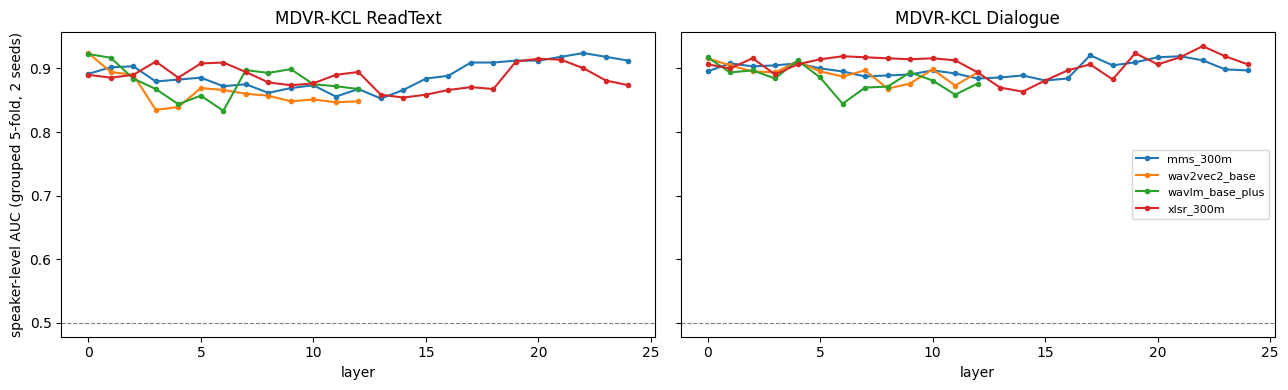

,model,task,layer,spk_auc,spk_auc_sd
144,mms_300m,Dialogue,17,0.921,0.006
124,mms_300m,ReadText,22,0.924,0.016
13,wav2vec2_base,Dialogue,0,0.916,0.021
0,wav2vec2_base,ReadText,0,0.924,0.019
39,wavlm_base_plus,Dialogue,0,0.917,0.019
26,wavlm_base_plus,ReadText,0,0.923,0.009
99,xlsr_300m,Dialogue,22,0.935,0.017
72,xlsr_300m,ReadText,20,0.915,0.025


In [ ]:
# B7b · layer-wise probe, speaker-grouped 5-fold, speaker-level AUC
probe = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=3000, class_weight="balanced"))
prev = pd.read_csv(RES/"kcl_layer_probe.csv") if (RES/"kcl_layer_probe.csv").exists() else pd.DataFrame(columns=["model"])
layer_rows = prev.to_dict("records")
for name in SSL_MODELS:
    p = FEAT/f"kcl_speech_{name}.npz"
    if not p.exists() or name in set(prev.model): continue      # cached
    print("probing", name, flush=True)
    d = np.load(p)
    for task in ("ReadText", "Dialogue"):
        m = d["task"] == task
        X, y, g = d["X"][m].astype(np.float32), d["label"][m], d["speaker"][m]
        for L in range(X.shape[1]):
            aucs = [cross_validate(probe(), X[:, L], y, g, "group_kfold", 5, seed=s)["spk"]["auc"] for s in range(2)]
            layer_rows.append(dict(model=name, task=task, layer=L, spk_auc=np.mean(aucs), spk_auc_sd=np.std(aucs)))
layers = pd.DataFrame(layer_rows); layers.to_csv(RES/"kcl_layer_probe.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, task in zip(axes, ("ReadText", "Dialogue")):
    for name, d in layers[layers.task == task].groupby("model"):
        ax.plot(d.layer, d.spk_auc, marker="o", ms=3, label=name)
    ax.axhline(0.5, color="grey", lw=0.8, ls="--"); ax.set_title(f"MDVR-KCL {task}"); ax.set_xlabel("layer")
axes[0].set_ylabel("speaker-level AUC (grouped 5-fold, 2 seeds)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(layers.loc[layers.groupby(["model", "task"]).spk_auc.idxmax()].round(3))

## B9 · Confound control on MDVR-KCL: can the model tell PD from HC using only the *silence*?

The September 2026 "Clever Hans" study warns that MDVR-KCL's non-speech audio may carry label information (setup noise, room, device). Here the same eGeMAPS + LOSO pipeline runs on **non-speech-only** audio (VAD inverted). Near-chance accuracy means the speech result is about the voice; accuracy close to the speech result means the recording setup leaks the label.

In [ ]:
# B9 · silence-only vs speech-only, eGeMAPS, leave-one-speaker-out
kcl_sil = extract_corpus(kcl, mode="silence", tag="kcl")
print(len(kcl_sil), "silence chunks;", kcl_sil.groupby("task").size().to_dict())
conf = []
for task in ("ReadText", "Dialogue"):
    for mode, df_ in (("speech", kcl_feat), ("silence", kcl_sil)):
        X, y, g = XY(df_, ("egemaps",), task)
        conf.append(audit(X, y, g, f"KCL_{task}_{mode}only", schemes=("loso",), models=("logreg", "svm", "xgb")))
conf = pd.concat(conf)
display(conf[["dataset", "model", "spk_bal_acc", "spk_ci_lo", "spk_ci_hi", "spk_auc"]])

  0/73 recordings
  10/73 recordings
  20/73 recordings
  30/73 recordings
  40/73 recordings
  50/73 recordings
  60/73 recordings
  70/73 recordings
2167 silence chunks; {'Dialogue': 1340, 'ReadText': 827}
  KCL_ReadText_speechonly loso            logreg  spk_bal_acc=0.796 spk_auc=0.804
  KCL_ReadText_speechonly loso            svm     spk_bal_acc=0.851 spk_auc=0.893
  KCL_ReadText_speechonly loso            xgb     spk_bal_acc=0.851 spk_auc=0.866
  KCL_ReadText_silenceonly loso            logreg  spk_bal_acc=0.638 spk_auc=0.565
  KCL_ReadText_silenceonly loso            svm     spk_bal_acc=0.561 spk_auc=0.533
  KCL_ReadText_silenceonly loso            xgb     spk_bal_acc=0.537 spk_auc=0.458
  KCL_Dialogue_speechonly loso            logreg  spk_bal_acc=0.771 spk_auc=0.838
  KCL_Dialogue_speechonly loso            svm     spk_bal_acc=0.748 spk_auc=0.810
  KCL_Dialogue_speechonly loso            xgb     spk_bal_acc=0.819 spk_auc=0.848
  KCL_Dialogue_silenceonly loso            logreg  

,dataset,model,spk_bal_acc,spk_ci_lo,spk_ci_hi,spk_auc
0,KCL_ReadText_speechonly,logreg,0.796,0.655,0.923,0.804
1,KCL_ReadText_speechonly,svm,0.851,0.728,0.960,0.893
2,KCL_ReadText_speechonly,xgb,0.851,0.728,0.960,0.866
0,KCL_ReadText_silenceonly,logreg,0.638,0.485,0.798,0.565
1,KCL_ReadText_silenceonly,svm,0.561,0.420,0.704,0.533
2,KCL_ReadText_silenceonly,xgb,0.537,0.396,0.686,0.458
0,KCL_Dialogue_speechonly,logreg,0.771,0.625,0.913,0.838
1,KCL_Dialogue_speechonly,svm,0.748,0.597,0.889,0.810
2,KCL_Dialogue_speechonly,xgb,0.819,0.676,0.942,0.848
0,KCL_Dialogue_silenceonly,logreg,0.624,0.452,0.784,0.559


**Reading B9 (21 Nov 2026).** Speaker-level, eGeMAPS, leave-one-speaker-out:

| Task | Speech-only BA (AUC) | Silence-only BA (AUC) |
|---|---|---|
| ReadText | 0.80–0.85 (0.80–0.89) | 0.54–0.64 (0.46–0.57) |
| Dialogue | 0.75–0.82 (0.81–0.85) | 0.62–0.71 (0.56–0.68) |

- **ReadText is clean:** non-speech audio is near chance, so the 0.85 result comes from the voice. ReadText is the primary English benchmark.
- **Dialogue leaks a little:** silence alone reaches up to 0.70 BA. In the phone-call dialogue the "silence" also holds the far-end speaker and line noise, so part of the Dialogue signal is the setup. Report Dialogue with this control next to it.
- This is the check that BenSParX cannot pass without audio (B6c), which is why its 0.98–1.00 is treated as suspect.

## B10 · Part A's ResNet50 under a subject-level split

Part A trained ResNet50 on TQWT heatmaps with a recording-level 80/20 split (BA 0.738). Here a compact re-implementation runs the same idea twice with identical settings: once recording-level (as in Part A and the paper), once with whole subjects held out (GroupShuffleSplit). Same 12 × 36 TQWT matrix, robust scaling fitted on the training split, clip to ±3, viridis colour map, resize to 224, ImageNet ResNet50 fully fine-tuned with Adam 1e-4 for 12 epochs, 3 seeds each. It is a simplified copy, not Part A verbatim; the *gap* between the two splits is what matters.

In [ ]:
# B10 · ResNet50 on TQWT heatmaps: recording-level vs subject-level split
import torch, torch.nn as nn, torchvision
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from matplotlib import cm
tq_cols = [c for c in uci.columns if c.startswith("tqwt")]
groups_order = list(dict.fromkeys(re.sub(r"_\d+$", "", c) for c in tq_cols))
M = np.stack([uci[[c for c in tq_cols if re.sub(r"_\d+$", "", c) == g]].values for g in groups_order], 1)  # [756,12,36]
print("TQWT tensor:", M.shape)

def to_images(Mtr, Mte):
    med = np.median(Mtr, 0); iqr = np.subtract(*np.percentile(Mtr, [75, 25], 0)) + 1e-8
    f = lambda A: (np.clip((A - med) / iqr, -3, 3) + 3) / 6
    def img(A):
        rgb = cm.viridis(f(A))[..., :3]                                   # [N,12,36,3]
        t = torch.tensor(rgb, dtype=torch.float32).permute(0, 3, 1, 2)
        t = nn.functional.interpolate(t, size=(224, 224), mode="nearest")
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        return (t - mean) / std
    return img(Mtr), img(Mte)

def train_resnet(Xtr, ytr, Xte, epochs=12, seed=0, bs=32):
    torch.manual_seed(seed); np.random.seed(seed)
    net = torchvision.models.resnet50(weights="IMAGENET1K_V2"); net.fc = nn.Linear(2048, 2); net = net.to(DEV)
    w = torch.tensor(len(ytr) / (2 * np.bincount(ytr)), dtype=torch.float32, device=DEV)
    opt = torch.optim.Adam(net.parameters(), lr=1e-4); lossf = nn.CrossEntropyLoss(weight=w)
    ytr_t = torch.tensor(ytr)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(ytr))
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            with torch.autocast("cuda", dtype=torch.float16):
                loss = lossf(net(Xtr[b].to(DEV)), ytr_t[b].to(DEV))
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval(); out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(Xte), 64): out.append(torch.softmax(net(Xte[i:i+64].to(DEV)).float(), 1)[:, 1].cpu())
    return torch.cat(out).numpy()

res10 = []
idx = np.arange(len(y_uci))
for seed in range(3):
    splits10 = {
        "recording-level (Part A)": train_test_split(idx, test_size=0.2, stratify=y_uci, random_state=seed),
        "subject-level": next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(idx, y_uci, g_uci)),
    }
    for name, (tr, te) in splits10.items():
        Xtr, Xte = to_images(M[tr], M[te])
        p = train_resnet(Xtr, y_uci[tr], Xte, seed=seed)
        spk = pd.DataFrame(dict(s=g_uci[te], y=y_uci[te], p=p)).groupby("s").agg(y=("y", "first"), p=("p", "mean"))
        rm, sm = metrics(y_uci[te], p), metrics(spk.y, spk.p)
        overlap = len(set(g_uci[tr]) & set(g_uci[te]))
        res10.append(dict(split=name, seed=seed, test_subjects_also_in_train=overlap,
                          rec_bal_acc=rm["bal_acc"], rec_auc=rm["auc"], subj_bal_acc=sm["bal_acc"], subj_auc=sm["auc"]))
        print(f"seed {seed} {name:26s} overlap={overlap:3d} rec_BA={rm['bal_acc']:.3f} subj_BA={sm['bal_acc']:.3f} subj_AUC={sm['auc']:.3f}", flush=True)
        torch.cuda.empty_cache()
res10 = pd.DataFrame(res10); res10.to_csv(RES/"uci_resnet_split_gap.csv", index=False)
display(res10.groupby("split")[["test_subjects_also_in_train", "rec_bal_acc", "rec_auc", "subj_bal_acc", "subj_auc"]].agg(["mean", "std"]).round(3))

TQWT tensor: (756, 12, 36)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


seed 0 recording-level (Part A)   overlap=124 rec_BA=0.652 subj_BA=0.658 subj_AUC=0.817
seed 0 subject-level              overlap=  0 rec_BA=0.683 subj_BA=0.761 subj_AUC=0.730
seed 1 recording-level (Part A)   overlap=120 rec_BA=0.708 subj_BA=0.717 subj_AUC=0.876
seed 1 subject-level              overlap=  0 rec_BA=0.597 subj_BA=0.589 subj_AUC=0.719
seed 2 recording-level (Part A)   overlap=126 rec_BA=0.721 subj_BA=0.715 subj_AUC=0.849
seed 2 subject-level              overlap=  0 rec_BA=0.554 subj_BA=0.571 subj_AUC=0.660


test_subjects_also_in_train        rec_bal_acc  \
                                                mean    std        mean   
split                                                                     
recording-level (Part A)                     123.333  3.055       0.694   
subject-level                                  0.000  0.000       0.612   

                                rec_auc        subj_bal_acc        subj_auc  \
                            std    mean    std         mean    std     mean   
split                                                                         
recording-level (Part A)  0.036   0.820  0.027        0.697  0.033    0.848   
subject-level             0.066   0.672  0.046        0.640  0.105    0.703   

                                 
                            std  
split                            
recording-level (Part A)  0.029  
subject-level             0.037

**Reading B10 (3 seeds, 21 Nov 2026).** With a recording-level split, about 123 of the ~150 test subjects also have recordings in training. Holding out whole subjects:

| Split | Test subjects also in train | Recording BA | Subject BA | Subject AUC |
|---|---|---|---|---|
| recording-level (Part A / paper) | ~123 | 0.694 | 0.697 | 0.847 |
| subject-level | 0 | 0.612 | 0.640 | 0.703 |

- ResNet50-on-heatmaps loses about 8 points of BA and 0.14 AUC once subjects can't be memorised; seed-to-seed spread is large (subject BA 0.57–0.76), so a single 80/20 split, as in the paper, is not reliable.
- Under the honest split, the image model (0.61–0.64 BA) is **below** plain XGBoost on the same TQWT numbers (0.734, B4). Converting features to images adds no information.
- For the thesis this is a clean, self-contained RQ1 result on your own Part A work. Part A stays as the reproduction chapter; B4 + B10 are its critical re-evaluation.

## B8 · Summary: how much does the split inflate the score?

One table and one figure across all three datasets: the best model under the leaky protocol vs the best under a speaker-safe protocol, speaker-level balanced accuracy with 95% bootstrap CI. This is the core exhibit for RQ1.

,dataset,leaky,protocol,model,ba,lo,hi,auc
1,BenSParX (Bengali) · 71 features,False,speaker 10-fold,rf,1.000,1.000,1.000,1.000
0,BenSParX (Bengali) · 71 features,True,as published (group=segment id),svm,1.000,1.000,1.000,1.000
6,MDVR-KCL Dialogue · eGeMAPS,False,loso,knn,0.819,0.676,0.942,0.787
3,MDVR-KCL Dialogue · eGeMAPS,True,random_segment,svm,0.967,0.889,1.000,1.000
5,MDVR-KCL ReadText · eGeMAPS,False,loso,svm,0.851,0.728,0.960,0.893
2,MDVR-KCL ReadText · eGeMAPS,True,random_segment,knn,1.000,1.000,1.000,1.000
11,UCI #470 · ResNet50 heatmaps (Part A),False,subject-level,resnet50,0.640,0.571,0.761,0.703
10,UCI #470 · ResNet50 heatmaps (Part A),True,recording-level (Part A),resnet50,0.697,0.658,0.717,0.848
9,UCI #470 · TQWT 432,False,group_kfold,xgb,0.734,0.668,0.798,0.836
7,UCI #470 · TQWT 432,True,random_segment,xgb,0.784,0.720,0.848,0.926


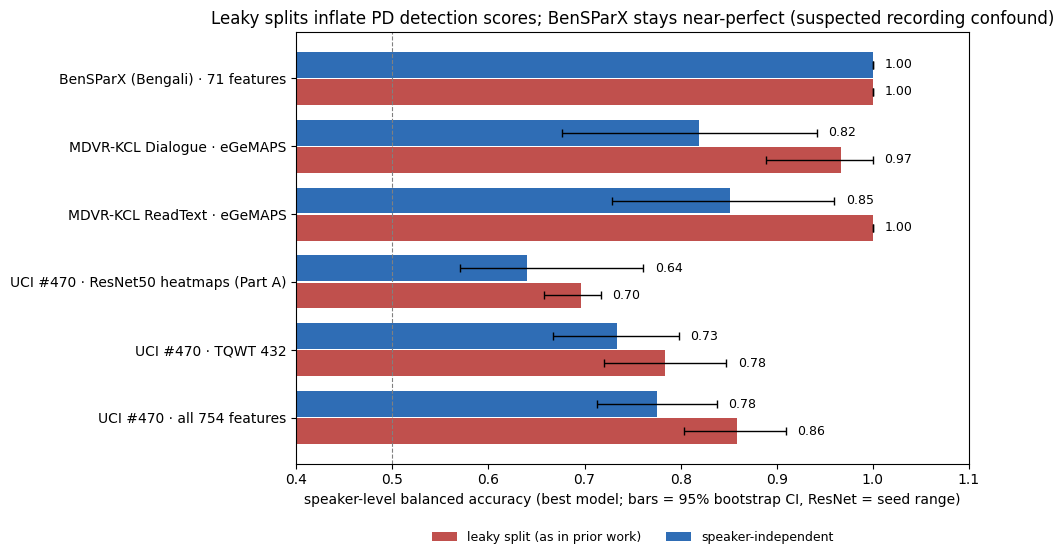

In [ ]:
# B8 · leaky vs speaker-safe, best model per dataset (speaker-level balanced accuracy)
R = pd.DataFrame(RESULTS)
if "protocol" not in R: R["protocol"] = np.nan
R["protocol"] = R["protocol"].fillna(R["scheme"])
NAMES = {"UCI470_all754": "UCI #470 · all 754 features", "UCI470_tqwt432": "UCI #470 · TQWT 432",
         "KCL_ReadText_egemaps": "MDVR-KCL ReadText · eGeMAPS", "KCL_Dialogue_egemaps": "MDVR-KCL Dialogue · eGeMAPS",
         "BenSParX": "BenSParX (Bengali) · 71 features"}
LEAKY = {"random_segment", "as published (group=segment id)"}
SAFE = {"loso", "group_kfold", "speaker 10-fold", "speaker LOSO"}
R = R[R.dataset.isin(NAMES) & R.protocol.isin(LEAKY | SAFE)].copy()
R["leaky"] = R.protocol.isin(LEAKY)
best = R.sort_values("spk_bal_acc", ascending=False).groupby(["dataset", "leaky"]).head(1)
rows = [dict(dataset=NAMES[r.dataset], leaky=r.leaky, protocol=r.protocol, model=r.model,
             ba=r.spk_bal_acc, lo=r.spk_ci_lo, hi=r.spk_ci_hi, auc=r.spk_auc) for r in best.itertuples()]
if "res10" in globals():                                   # ResNet50 heatmaps (B10): mean of 3 seeds, range as interval
    for split, leaky in (("recording-level (Part A)", True), ("subject-level", False)):
        d = res10[res10.split == split]
        rows.append(dict(dataset="UCI #470 · ResNet50 heatmaps (Part A)", leaky=leaky, protocol=split, model="resnet50",
                         ba=d.subj_bal_acc.mean(), lo=d.subj_bal_acc.min(), hi=d.subj_bal_acc.max(), auc=d.subj_auc.mean()))
S = pd.DataFrame(rows).sort_values(["dataset", "leaky"])
display(S.round(3)); S.to_csv(RES/"summary_leaky_vs_safe.csv", index=False)

order = list(dict.fromkeys(S.dataset))
fig, ax = plt.subplots(figsize=(10, 0.75*len(order) + 1.2))
for k, (flag, lab, col) in enumerate([(True, "leaky split (as in prior work)", "#c0504d"), (False, "speaker-independent", "#2f6db5")]):
    d = S[S.leaky == flag].set_index("dataset").reindex(order)
    yy = np.arange(len(order)) + (0.2 if flag else -0.2)
    ax.barh(yy, d.ba, height=0.38, color=col, label=lab)
    ax.errorbar(d.ba, yy, xerr=[d.ba - d.lo, d.hi - d.ba], fmt="none", ecolor="black", capsize=3, lw=1)
    for y_, v, h in zip(yy, d.ba, d.hi):
        if pd.notna(v): ax.text(max(v, h) + 0.012, y_, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlim(0.4, 1.1); ax.axvline(0.5, color="grey", lw=0.8, ls="--")
ax.set_xlabel("speaker-level balanced accuracy (best model; bars = 95% bootstrap CI, ResNet = seed range)")
ax.set_title("Leaky splits inflate PD detection scores; BenSParX stays near-perfect (suspected recording confound)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9, frameon=False); plt.tight_layout(); plt.savefig(RES/"leaky_vs_safe.png", dpi=200); plt.show()

# Part C — Improving on the honest baseline (MDVR-KCL, English)

Baseline to beat: **0.851 BA / AUC 0.893** (eGeMAPS chunks → SVM, leave-one-speaker-out, ReadText). Target: **≥ 0.90 BA, AUC ≥ 0.95**. Experiment IDs match the plan doc ("How we beat the baseline").

| Cell | Experiment |
|---|---|
| C1 | Helpers: speaker-level LOSO, in-fold model selection, paired statistics |
| C2 | E3 · Whisper-medium encoder embeddings (all layers) |
| C3 | E1 · speaker-level modelling of eGeMAPS |
| C4 | E2 + E3 · SSL models under LOSO, layer chosen inside each fold |
| C5 | E4–E6 · fusion, both tasks per speaker, ensembles + significance vs baseline |

Rules: every choice (layer, C, which layers to average) is made **inside the training fold**, by inner 5-fold CV on the 36 training speakers. Systems that combine models use fixed recipes (plain averages), so nothing is tuned on the test speaker. Significance: exact McNemar on speaker decisions and a paired bootstrap of the AUC difference against the baseline.

### Round 1 results (21 Nov 2026), MDVR-KCL ReadText, LOSO, speaker-level

| System | BA [95% CI] | AUC | Sens / Spec |
|---|---|---|---|
| Baseline: eGeMAPS chunks → SVM | 0.851 [0.73, 0.96] | 0.893 | 0.75 / 0.95 |
| E1: eGeMAPS, one vector per speaker | 0.765 | 0.818 | – |
| **E2: XLS-R-300m, in-fold layer (11–12)** | **0.875** [0.75, 0.97] | **0.938** | 0.75 / 1.00 |
| E2: WavLM-base+ | 0.875 | 0.923 | 0.75 / 1.00 |
| E3: HuBERT-large (layers 17–18) | 0.875 | 0.905 | 0.75 / 1.00 |
| E3: Whisper-medium / WavLM-large | 0.820 / 0.851 | 0.908 / 0.845 | – |
| E4–E6: fusion, ensembles, both tasks | 0.851–0.875 | 0.872–0.908 | 0.75 / 1.00 |
| E10: prosody + voice quality alone | 0.741 | 0.810 | – |
| **E10: 50/50 XLS-R + prosody** | **0.882** | 0.917 | catches KCL17 |

- All SSL systems miss the same 4 PD speakers (KCL16/17/30/34): H&Y 2, UPDRS speech 0–1, prosody inside the healthy range (C9, C10). The ceiling is clinical.
- No gain is significant yet (McNemar p = 1.0; ΔAUC CI for XLS-R −0.003 to +0.119).
- Figshare /a/ (C8): HuBERT-large 0.766 BA / AUC 0.793 vs eGeMAPS 0.568. Cross-corpus transfer is at chance.
- E7 fine-tuning (C6, same 5 folds): fine-tuned WavLM 0.847 BA / AUC 0.882 vs frozen 0.831 / 0.909, so no clear gain; gate G3 not passed.
- Next levers: more (early-stage) PD speakers via Italian PVS / NeuroVoz (E8), fine-tuning (C6), severity-stratified reporting.

In [ ]:
# C1 · helpers: speaker-level LOSO with in-fold selection + paired statistics
from sklearn.model_selection import StratifiedKFold
from scipy.stats import binomtest
def XY(df, feats=("egemaps",), task=None):
    d = df if task is None else df[df.task == task]
    X = np.hstack([np.stack(d[f].values) for f in feats])
    return X, d.label.values, d.speaker.values

PROBS = {}       # (system, task) -> pd.Series(prob, index=speaker)
PART_C = []      # result rows

def agg_speakers(X, g, y, stats=("mean",)):
    """Chunk-level X [n, ..., D] -> one row per speaker [S, ..., D*len(stats)] (sorted speaker ids)."""
    spk = np.unique(g); rows, ys = [], []
    for s in spk:
        m = g == s
        parts = [X[m].mean(0)] + ([X[m].std(0)] if "std" in stats else [])
        rows.append(np.concatenate(parts, -1)); ys.append(int(y[m][0]))
    return np.stack(rows), np.array(ys), spk

def lr(C=0.1):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

def _inner_auc(make, X, y, seed=0, k=5):
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        oof[te] = make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return _auc(y, oof)

def fp_tuned(Xtr, ytr, Xte, Cs=(0.01, 0.1, 1.0)):
    """Logistic regression, C chosen by inner 5-fold AUC on training speakers."""
    C = max(Cs, key=lambda c: _inner_auc(lambda: lr(c), Xtr, ytr))
    return lr(C).fit(Xtr, ytr).predict_proba(Xte)[:, 1], dict(C=C)

def fp_layers(Xtr, ytr, Xte, k=1, C=0.1):
    """Xtr [S, L, D]. Pick the k best layers by inner AUC on training speakers, average their probabilities."""
    scores = np.array([_inner_auc(lambda: lr(C), Xtr[:, L], ytr) for L in range(Xtr.shape[1])])
    best = np.argsort(-scores)[:k]
    p = np.mean([lr(C).fit(Xtr[:, L], ytr).predict_proba(Xte[:, L])[:, 1] for L in best], 0)
    return p, dict(layers=tuple(int(b) for b in best))

def loso_speakers(Xs, ys, fit_predict, **kw):
    probs, info = np.zeros(len(ys)), []
    for i in range(len(ys)):
        tr = np.arange(len(ys)) != i
        p, inf = fit_predict(Xs[tr], ys[tr], Xs[i:i+1], **kw)
        probs[i] = p[0]; info.append(inf)
    return probs, info

def paired_stats(y, p_new, p_base, n=2000, seed=0):
    """Exact McNemar on speaker decisions + bootstrap CI of the AUC difference."""
    a, b = (p_new >= 0.5) == y, (p_base >= 0.5) == y
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    p_mc = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i): d.append(_auc(y[i], p_new[i]) - _auc(y[i], p_base[i]))
    return n01, n10, p_mc, np.percentile(d, [2.5, 97.5])

def register(system, task, y, prob, spk, exp, note=""):
    s = pd.Series(prob, index=spk); PROBS[(system, task)] = s
    m, ci = metrics(y, prob), bootstrap_ci(y, prob)
    row = dict(exp=exp, system=system, task=task, n_spk=len(y), bal_acc=m["bal_acc"], ci_lo=ci[0], ci_hi=ci[1],
               auc=m["auc"], sens=m["sens"], spec=m["spec"], note=note)
    PART_C.append(row)
    print(f"[{exp}] {system:34s} {task:9s} BA={m['bal_acc']:.3f} [{ci[0]:.2f},{ci[1]:.2f}] AUC={m['auc']:.3f} {note}", flush=True)
    return row
print("Part C helpers ready")

Part C helpers ready


In [ ]:
# C2 · E3: Whisper-medium encoder, all layers, mean+std pooled per 4 s chunk (GPU)
from transformers import WhisperFeatureExtractor, WhisperModel
def whisper_extract(meta, name="whisper_medium", hf_id="openai/whisper-medium", tag="kcl", mode="speech", bs=8):
    out = FEAT/f"{tag}_{mode}_{name}.npz"
    if out.exists(): return out
    fe = WhisperFeatureExtractor.from_pretrained(hf_id)
    enc = WhisperModel.from_pretrained(hf_id).encoder.to(DEV).half().eval()
    n_frames = int(4.0 * 50)                                     # 50 encoder frames per second
    embs, spk, lab, task = [], [], [], []
    for r in meta.itertuples():
        chs = chunk(apply_mode(rms_normalize(load_audio(r.path)), mode))
        for i in range(0, len(chs), bs):
            feats = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt").input_features.to(DEV).half()
            with torch.no_grad():
                hs = enc(feats, output_hidden_states=True).hidden_states
            h = torch.stack(hs, 1)[:, :, :n_frames].float()            # [B, L+1, T, H]
            embs.append(torch.cat([h.mean(2), h.std(2)], -1).cpu().numpy().astype(np.float16))
        n = len(chs); spk += [r.speaker]*n; lab += [r.label]*n; task += [r.task]*n
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab), task=np.array(task))
    del enc; torch.cuda.empty_cache(); return out
t0 = time.time(); print(whisper_extract(kcl), round(time.time() - t0), "s")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.99k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

/content/thesis/features/kcl_speech_whisper_medium.npz 456 s


In [ ]:
# C3 · E1: speaker-level modelling of eGeMAPS (vs the chunk-level SVM baseline)
for task in ("ReadText", "Dialogue"):
    X, y, g = XY(kcl_feat, ("egemaps",), task)
    base = cross_validate(MODELS["svm"](), X, y, g, "loso")["spk_table"]          # baseline, recomputed
    register("egemaps · chunk SVM (baseline)", task, base.y.values, base.prob.values, base.index.values, "B5c")
    Xs, ys, spk = agg_speakers(X, g, y, stats=("mean", "std"))
    p, info = loso_speakers(Xs, ys, fp_tuned)
    register("egemaps · speaker vector LR", task, ys, p, spk, "E1",
             f"C picked: {pd.Series([i['C'] for i in info]).value_counts().to_dict()}")
    Xm, _, _ = agg_speakers(X, g, y, stats=("mean",))
    p, _ = loso_speakers(Xm, ys, fp_tuned)
    register("egemaps · speaker mean LR", task, ys, p, spk, "E1")

[B5c] egemaps · chunk SVM (baseline)     ReadText  BA=0.851 [0.73,0.96] AUC=0.893 
[E1] egemaps · speaker vector LR        ReadText  BA=0.765 [0.61,0.90] AUC=0.818 C picked: {0.01: 34, 0.1: 2, 1.0: 1}
[E1] egemaps · speaker mean LR          ReadText  BA=0.835 [0.70,0.95] AUC=0.833 
[B5c] egemaps · chunk SVM (baseline)     Dialogue  BA=0.748 [0.60,0.89] AUC=0.810 
[E1] egemaps · speaker vector LR        Dialogue  BA=0.714 [0.54,0.86] AUC=0.727 C picked: {0.1: 14, 0.01: 12, 1.0: 10}
[E1] egemaps · speaker mean LR          Dialogue  BA=0.748 [0.59,0.89] AUC=0.813 


In [ ]:
# C4 · E2 + E3: every SSL model under LOSO.
# Layers are chosen inside each training fold (inner 5-fold on the 36 training speakers, cheap speaker-level scoring).
# Two classifiers per model: (a) speaker-mean vectors, top-3 layers averaged; (b) chunk-level LR on the chosen layer,
# chunk probabilities averaged per speaker (E1 showed chunk-level training beats speaker vectors).
ssl_files = sorted(FEAT.glob("kcl_speech_*.npz"))
print([p.stem.replace("kcl_speech_", "") for p in ssl_files])
LAYER_PICKS = {}
def inner_layer_scores(Xs_tr, ys_tr, C=0.1):
    return np.array([_inner_auc(lambda: lr(C), Xs_tr[:, L], ys_tr) for L in range(Xs_tr.shape[1])])

def chunk_lr(Xtr, ytr, Xte, C=0.01):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
    return clf.fit(Xtr.astype(np.float32), ytr).predict_proba(Xte.astype(np.float32))[:, 1]

for p in ssl_files:
    name = p.stem.replace("kcl_speech_", ""); d = np.load(p)
    for task in ("ReadText", "Dialogue"):
        m = d["task"] == task
        Xc, gc, yc = d["X"][m], d["speaker"][m], d["label"][m].astype(int)      # float16 [n, L, D]
        Xs, ys, spk = agg_speakers(Xc.astype(np.float32), gc, yc)
        t0 = time.time(); p_spk3, p_chunk, picks = np.zeros(len(ys)), np.zeros(len(ys)), []
        for i in range(len(ys)):
            tr = np.arange(len(ys)) != i
            top = np.argsort(-inner_layer_scores(Xs[tr], ys[tr]))[:3]; picks.append(int(top[0]))
            p_spk3[i] = np.mean([lr(0.1).fit(Xs[tr][:, L], ys[tr]).predict_proba(Xs[i:i+1, L])[0, 1] for L in top])
            ctr, cte = gc != spk[i], gc == spk[i]
            p_chunk[i] = chunk_lr(Xc[ctr, top[0]], yc[ctr], Xc[cte, top[0]]).mean()
        LAYER_PICKS[(name, task)] = pd.Series(picks).value_counts().head(3).to_dict()
        register(f"{name} · speaker top-3 layers", task, ys, p_spk3, spk, "E2")
        register(f"{name} · chunk LR, in-fold layer", task, ys, p_chunk, spk, "E2",
                 f"layers {LAYER_PICKS[(name, task)]} · {round(time.time()-t0)} s")
    del d

['hubert_large', 'mms_300m', 'wav2vec2_base', 'wavlm_base_plus', 'wavlm_large', 'whisper_medium', 'xlsr_300m']
[E2] hubert_large · speaker top-3 layers ReadText  BA=0.827 [0.70,0.94] AUC=0.902 
[E2] hubert_large · chunk LR, in-fold layer ReadText  BA=0.875 [0.75,0.97] AUC=0.905 layers {18: 16, 17: 15, 19: 3} · 128 s
[E2] hubert_large · speaker top-3 layers Dialogue  BA=0.843 [0.71,0.95] AUC=0.911 
[E2] hubert_large · chunk LR, in-fold layer Dialogue  BA=0.867 [0.75,0.97] AUC=0.883 layers {15: 14, 13: 10, 14: 8} · 108 s
[E2] mms_300m · speaker top-3 layers    ReadText  BA=0.851 [0.72,0.95] AUC=0.896 
[E2] mms_300m · chunk LR, in-fold layer ReadText  BA=0.844 [0.72,0.95] AUC=0.899 layers {17: 28, 18: 2, 4: 2} · 112 s
[E2] mms_300m · speaker top-3 layers    Dialogue  BA=0.795 [0.65,0.92] AUC=0.883 
[E2] mms_300m · chunk LR, in-fold layer Dialogue  BA=0.843 [0.71,0.96] AUC=0.898 layers {17: 34, 20: 1, 19: 1} · 105 s
[E2] wav2vec2_base · speaker top-3 layers ReadText  BA=0.875 [0.75,0.97] A

In [ ]:
# C5 · E4-E6: fusion, both tasks, ensembles; paired tests vs the baseline (ReadText)
def combine(systems, task_list, name, exp):
    """Plain average of probabilities over systems and tasks (fixed recipe, nothing tuned)."""
    parts = [PROBS[(s, t)] for s in systems for t in task_list if (s, t) in PROBS]
    df_ = pd.concat(parts, axis=1)
    prob = df_.mean(1, skipna=True)                                   # speakers missing a task use what exists
    y_ = kcl.drop_duplicates("speaker").set_index("speaker").label.reindex(prob.index).values
    return register(name, "+".join(t[:4] for t in task_list), y_, prob.values, prob.index.values, exp)

ssl_names = sorted({s for (s, t) in PROBS if "chunk LR" in s})
all_ssl = ssl_names
combine(all_ssl, ["ReadText"], "E6 · ensemble of all SSL models", "E6")
combine(all_ssl + ["egemaps · chunk SVM (baseline)"], ["ReadText"], "E4 · SSL ensemble + eGeMAPS", "E4")
# equal-weight fusion: half SSL ensemble, half eGeMAPS
PROBS[("SSL ensemble", "ReadText")] = pd.concat([PROBS[(s, "ReadText")] for s in all_ssl], axis=1).mean(1)
PROBS[("SSL ensemble", "Dialogue")] = pd.concat([PROBS[(s, "Dialogue")] for s in all_ssl], axis=1).mean(1)
combine(["SSL ensemble", "egemaps · chunk SVM (baseline)"], ["ReadText"], "E4 · 50/50 SSL ensemble + eGeMAPS", "E4")
combine(["SSL ensemble", "egemaps · chunk SVM (baseline)"], ["ReadText", "Dialogue"], "E4+E5 · 50/50 fusion, both tasks", "E4")
combine(["egemaps · chunk SVM (baseline)"], ["ReadText", "Dialogue"], "E5 · eGeMAPS, both tasks", "E5")
combine(all_ssl, ["ReadText", "Dialogue"], "E5+E6 · SSL ensemble, both tasks", "E5")
combine(all_ssl + ["egemaps · chunk SVM (baseline)"], ["ReadText", "Dialogue"], "E4+E5+E6 · everything, both tasks", "E4")

# paired statistics against the baseline on the speakers both systems scored
base = PROBS[("egemaps · chunk SVM (baseline)", "ReadText")]
C = pd.DataFrame(PART_C).drop_duplicates(["system", "task"], keep="last")
stats_rows = []
for r in C.itertuples():
    key = (r.system, r.task)
    if key not in PROBS: continue
    s = PROBS[key]; common = s.index.intersection(base.index)
    yv = kcl.drop_duplicates("speaker").set_index("speaker").label.reindex(common).values
    n01, n10, p_mc, d_ci = paired_stats(yv, s.reindex(common).values, base.reindex(common).values)
    stats_rows.append(dict(system=r.system, task=r.task, fixed_vs_base=n01, broken_vs_base=n10,
                           mcnemar_p=p_mc, dAUC_lo=d_ci[0], dAUC_hi=d_ci[1]))
C = C.merge(pd.DataFrame(stats_rows), on=["system", "task"], how="left")
C.to_csv(RES/"partC_results.csv", index=False)
show = ["exp", "system", "task", "bal_acc", "ci_lo", "ci_hi", "auc", "sens", "spec", "fixed_vs_base", "broken_vs_base", "mcnemar_p", "dAUC_lo", "dAUC_hi"]
display(C.sort_values(["task", "auc"], ascending=[True, False])[show].round(3))

[E6] E6 · ensemble of all SSL models    Read      BA=0.875 [0.75,0.97] AUC=0.908 
[E4] E4 · SSL ensemble + eGeMAPS        Read      BA=0.875 [0.75,0.97] AUC=0.908 
[E4] E4 · 50/50 SSL ensemble + eGeMAPS  Read      BA=0.875 [0.75,0.97] AUC=0.899 
[E4] E4+E5 · 50/50 fusion, both tasks   Read+Dial BA=0.851 [0.73,0.96] AUC=0.872 
[E5] E5 · eGeMAPS, both tasks           Read+Dial BA=0.851 [0.73,0.96] AUC=0.851 
[E5] E5+E6 · SSL ensemble, both tasks   Read+Dial BA=0.875 [0.75,0.97] AUC=0.878 
[E4] E4+E5+E6 · everything, both tasks  Read+Dial BA=0.875 [0.75,0.97] AUC=0.872 


,exp,system,task,bal_acc,ci_lo,ci_hi,auc,sens,spec,fixed_vs_base,broken_vs_base,mcnemar_p,dAUC_lo,dAUC_hi
24,E2,wavlm_large · speaker top-3 layers,Dialogue,0.886,0.771,0.981,0.924,0.867,0.905,3,2,1.000,-0.057,0.142
8,E2,hubert_large · speaker top-3 layers,Dialogue,0.843,0.708,0.955,0.911,0.733,0.952,2,2,1.000,-0.084,0.147
25,E2,"wavlm_large · chunk LR, in-fold layer",Dialogue,0.843,0.707,0.950,0.905,0.733,0.952,1,1,1.000,-0.097,0.133
13,E2,"mms_300m · chunk LR, in-fold layer",Dialogue,0.843,0.708,0.958,0.898,0.733,0.952,1,1,1.000,-0.106,0.132
16,E2,wav2vec2_base · speaker top-3 layers,Dialogue,0.876,0.752,0.971,0.898,0.800,0.952,2,1,1.000,-0.080,0.097
20,E2,wavlm_base_plus · speaker top-3 layers,Dialogue,0.805,0.672,0.919,0.886,0.800,0.810,1,3,0.625,-0.101,0.094
9,E2,"hubert_large · chunk LR, in-fold layer",Dialogue,0.867,0.750,0.969,0.883,0.733,1.000,1,0,1.000,-0.114,0.097
12,E2,mms_300m · speaker top-3 layers,Dialogue,0.795,0.647,0.919,0.883,0.733,0.857,0,2,0.500,-0.104,0.088
32,E2,xlsr_300m · speaker top-3 layers,Dialogue,0.795,0.647,0.919,0.876,0.733,0.857,0,2,0.500,-0.109,0.083
29,E2,"whisper_medium · chunk LR, in-fold layer",Dialogue,0.748,0.596,0.875,0.873,0.733,0.762,0,4,0.125,-0.108,0.065


## C6 · E7: fine-tuning WavLM-base-plus with the GCON recipe

Fine-tuning 95 M parameters on 37 speakers is the riskiest experiment, so it gets its own fair comparison. Fine-tuning 37 LOSO models is too slow on a T4, so this uses speaker-grouped 5-fold × 2 seeds. The frozen probe and the eGeMAPS model are re-scored **on exactly the same folds**.

Recipe: CNN front-end frozen; learned weighted sum of all transformer layers → attentive statistics pooling → MLP head. Training runs in 3 stages, following the GCON paper's progressive layer-wise fine-tuning:
1. head + layer weights only (lr 1e-3, 2 epochs),
2. + top 4 transformer layers (lr 1e-4, 2 epochs),
3. everything, with layer-wise LR decay 0.8 (top lr 5e-5, 3 epochs).

Augmentation: random gain ±6 dB, speed 0.9–1.1, Gaussian noise at 20–40 dB SNR. Class-weighted loss, fp16, batch 16. Epoch counts are fixed in advance (no early stopping on test speakers).

In [ ]:
# C6 · E7: fine-tune WavLM-base-plus (3-stage progressive unfreezing + LLRD), 5-fold x 2 seeds, ReadText
import torch.nn as nn, torch.nn.functional as F
FT_ID, TASK_FT = "microsoft/wavlm-base-plus", "ReadText"
meta_ft = kcl[kcl.task == TASK_FT].reset_index(drop=True)
WAV, WSPK, WLAB = [], [], []
for r in meta_ft.itertuples():
    for ch in chunk(apply_mode(rms_normalize(load_audio(r.path)), "speech")):
        WAV.append(ch); WSPK.append(r.speaker); WLAB.append(r.label)
WAV = torch.tensor(np.stack(WAV)); WSPK, WLAB = np.array(WSPK), np.array(WLAB)
print("chunks:", WAV.shape, "speakers:", len(set(WSPK)))

class AttnStatsPool(nn.Module):
    def __init__(s, H): super().__init__(); s.att = nn.Sequential(nn.Linear(H, 128), nn.Tanh(), nn.Linear(128, 1))
    def forward(s, h):
        w = torch.softmax(s.att(h), 1); mu = (w * h).sum(1)
        sd = ((w * (h - mu.unsqueeze(1))**2).sum(1)).clamp_min(1e-6).sqrt()
        return torch.cat([mu, sd], -1)

class PDNet(nn.Module):
    def __init__(s):
        super().__init__()
        s.bb = AutoModel.from_pretrained(FT_ID, layerdrop=0.0); s.bb.feature_extractor._freeze_parameters()
        s.bb.config.layerdrop = 0.0                               # LayerDrop would change the number of hidden states
        with torch.no_grad():                                    # count hidden states once (robust to config quirks)
            L = len(s.bb(torch.zeros(1, 16000), output_hidden_states=True).hidden_states)
        H = s.bb.config.hidden_size
        s.lw = nn.Parameter(torch.zeros(L)); s.pool = AttnStatsPool(H)
        s.head = nn.Sequential(nn.Linear(2 * H, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, x):
        x = (x - x.mean(1, keepdim=True)) / (x.std(1, keepdim=True) + 1e-6)
        hs = torch.stack(s.bb(x, output_hidden_states=True).hidden_states, 0)        # [L, B, T, H]
        h = (torch.softmax(s.lw, 0).view(-1, 1, 1, 1) * hs).sum(0)
        return s.head(s.pool(h)).squeeze(-1)

def augment(x):
    B, N = x.shape; out = []
    for i in range(B):
        xi = x[i] * (10 ** (np.random.uniform(-6, 6) / 20))
        sp = np.random.uniform(0.9, 1.1)
        xi = F.interpolate(xi.view(1, 1, -1), size=int(N / sp), mode="linear", align_corners=False).view(-1)
        xi = xi[:N] if len(xi) >= N else F.pad(xi, (0, N - len(xi)))
        snr = np.random.uniform(20, 40); xi = xi + torch.randn_like(xi) * xi.std() / (10 ** (snr / 20))
        out.append(xi)
    return torch.stack(out)

def set_stage(net, stage):
    for p in net.bb.parameters(): p.requires_grad = False
    layers = net.bb.encoder.layers; nL = len(layers)
    groups = [dict(params=list(net.head.parameters()) + list(net.pool.parameters()) + [net.lw], lr=1e-3 if stage < 3 else 2e-4)]
    if stage == 2:
        for l in layers[-4:]:
            for p in l.parameters(): p.requires_grad = True
        groups.append(dict(params=[p for l in layers[-4:] for p in l.parameters()], lr=1e-4))
    if stage == 3:
        for i, l in enumerate(layers):
            for p in l.parameters(): p.requires_grad = True
            groups.append(dict(params=list(l.parameters()), lr=5e-5 * 0.8 ** (nL - 1 - i)))
        rest = [p for n_, p in net.bb.named_parameters() if not n_.startswith("encoder.layers") and not n_.startswith("feature_extractor")]
        for p in rest: p.requires_grad = True
        groups.append(dict(params=rest, lr=5e-5 * 0.8 ** nL))
    return torch.optim.AdamW(groups, weight_decay=0.01)

def train_eval_fold(tr, te, seed, bs=16):
    torch.manual_seed(seed); np.random.seed(seed)
    net = PDNet().to(DEV); scaler = torch.cuda.amp.GradScaler()
    ytr = torch.tensor(WLAB[tr], dtype=torch.float32)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1), device=DEV)
    for stage, epochs in ((1, 2), (2, 2), (3, 3)):
        opt = set_stage(net, stage); net.train()
        for ep in range(epochs):
            perm = np.random.permutation(tr)
            for i in range(0, len(perm), bs):
                b = perm[i:i+bs]; x = augment(WAV[b]).to(DEV); yb = torch.tensor(WLAB[b], dtype=torch.float32, device=DEV)
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = F.binary_cross_entropy_with_logits(net(x), yb, pos_weight=pos_w)
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(net.parameters(), 1.0); scaler.step(opt); scaler.update()
    net.eval(); out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(te), 32): out.append(torch.sigmoid(net(WAV[te[i:i+32]].to(DEV)).float()).cpu())
    del net; torch.cuda.empty_cache()
    return torch.cat(out).numpy()

# same speaker folds for all three systems
d_ssl = np.load(FEAT/"kcl_speech_wavlm_base_plus.npz"); msk = d_ssl["task"] == TASK_FT
Xc_ssl, gc_ssl, yc_ssl = d_ssl["X"][msk], d_ssl["speaker"][msk], d_ssl["label"][msk].astype(int)
Xs_ssl, ys_ft, spk_ft = agg_speakers(Xc_ssl.astype(np.float32), gc_ssl, yc_ssl)
Xe, ye, ge = XY(kcl_feat, ("egemaps",), TASK_FT)
spk_mean = lambda prob, groups, who: pd.Series(prob, index=groups).groupby(level=0).mean().reindex(who).values
ft_rows = []
for seed in (0, 1):
    sk = StratifiedKFold(5, shuffle=True, random_state=seed)
    p_ft, p_fr, p_eg = pd.Series(0.0, index=spk_ft), np.zeros(len(ys_ft)), np.zeros(len(ys_ft))
    for k, (s_tr, s_te) in enumerate(sk.split(Xs_ssl, ys_ft)):
        tr = np.where(np.isin(WSPK, spk_ft[s_tr]))[0]; te = np.where(np.isin(WSPK, spk_ft[s_te]))[0]
        t0 = time.time(); pc = train_eval_fold(tr, te, seed)
        p_ft.loc[spk_ft[s_te]] = pd.Series(pc, index=WSPK[te]).groupby(level=0).mean().reindex(spk_ft[s_te]).values
        L = int(np.argmax(inner_layer_scores(Xs_ssl[s_tr], ys_ft[s_tr])))
        ctr, cte = np.isin(gc_ssl, spk_ft[s_tr]), np.isin(gc_ssl, spk_ft[s_te])
        p_fr[s_te] = spk_mean(chunk_lr(Xc_ssl[ctr, L], yc_ssl[ctr], Xc_ssl[cte, L]), gc_ssl[cte], spk_ft[s_te])
        etr, ete = np.isin(ge, spk_ft[s_tr]), np.isin(ge, spk_ft[s_te])
        p_eg[s_te] = spk_mean(MODELS["svm"]().fit(Xe[etr], ye[etr]).predict_proba(Xe[ete])[:, 1], ge[ete], spk_ft[s_te])
        print(f"seed {seed} fold {k}: {round(time.time()-t0)} s", flush=True)
    for name, p in (("WavLM-base+ fine-tuned (GCON recipe)", p_ft.values), ("WavLM-base+ frozen, chunk LR in-fold layer", p_fr), ("eGeMAPS chunk SVM", p_eg)):
        m = metrics(ys_ft, p); ft_rows.append(dict(seed=seed, system=name, bal_acc=m["bal_acc"], auc=m["auc"], sens=m["sens"], spec=m["spec"]))
        PROBS[(name + f" [5-fold s{seed}]", TASK_FT)] = pd.Series(p, index=spk_ft)
ft = pd.DataFrame(ft_rows); ft.to_csv(RES/"partC_finetune.csv", index=False)
display(ft.groupby("system")[["bal_acc", "auc", "sens", "spec"]].agg(["mean", "std"]).round(3))

chunks: torch.Size([1649, 64000]) speakers: 37


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

seed 0 fold 0: 154 s


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

seed 0 fold 1: 160 s


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

... (12 outputs left out)

seed 1 fold 3: 162 s


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

seed 1 fold 4: 156 s


bal_acc           auc         \
                                              mean    std   mean    std   
system                                                                    
WavLM-base+ fine-tuned (GCON recipe)         0.847  0.005  0.882  0.027   
WavLM-base+ frozen, chunk LR in-fold layer   0.831  0.005  0.909  0.015   
eGeMAPS chunk SVM                            0.808  0.027  0.893  0.013   

                                             sens          spec         
                                             mean    std   mean    std  
system                                                                  
WavLM-base+ fine-tuned (GCON recipe)        0.719  0.044  0.976  0.034  
WavLM-base+ frozen, chunk LR in-fold layer  0.781  0.044  0.881  0.034  
eGeMAPS chunk SVM                           0.688  0.088  0.929  0.034

**Reading C6 (E7, 21 Nov 2026).** Same speaker folds for all three systems (5-fold × 2 seeds, ReadText; mean ± SD over seeds):

| System | BA | AUC | Sens | Spec |
|---|---|---|---|---|
| WavLM-base+ fine-tuned (GCON 3-stage + LLRD, augmentation) | 0.847 ± 0.005 | 0.882 ± 0.027 | 0.72 | 0.98 |
| WavLM-base+ frozen, chunk LR, in-fold layer | 0.831 ± 0.005 | 0.909 ± 0.015 | 0.78 | 0.88 |
| eGeMAPS chunk SVM | 0.808 ± 0.027 | 0.893 ± 0.013 | 0.69 | 0.93 |

- Fine-tuning gains ~1.5 BA points but loses ~0.03 AUC, and its sensitivity is lower: it becomes more conservative, not more discriminative. **Gate G3 is not passed.** With 37 speakers (~30 per training fold), the frozen representation plus a linear head is the better bias–variance trade-off.
- 5-fold numbers sit below LOSO (fewer training speakers per fold), so compare only within this table.
- Fine-tuning becomes worth revisiting once E8 adds training speakers; the code here is ready for that.

## C7–C8 · Second open English corpus: Figshare sustained /a/ (Iyer et al., Sci Rep 2023)

81 US-English speakers (40 PD, 41 HC). Each person recorded one sustained /a/ on their own phone. Licence CC BY 4.0, 4 MB, downloaded directly. Two uses:
1. **Within-corpus**, leave-one-speaker-out: does the pipeline that works on read speech also work on a vowel?
2. **Cross-corpus (RQ4):** train on MDVR-KCL ReadText → test on Figshare, and the reverse. Different task, device and speakers make this a hard generalisation test.

In [ ]:
# C7 · download + metadata
FIG = DATA/"figshare_ah"; FIG.mkdir(exist_ok=True)
for name, url in (("Demographics_age_sex.xlsx", "https://ndownloader.figshare.com/files/41836707"),
                  ("PD_AH.zip", "https://ndownloader.figshare.com/files/41836710"),
                  ("HC_AH.zip", "https://ndownloader.figshare.com/files/41836713")):
    out = FIG/name
    if not out.exists(): out.write_bytes(requests.get(url, timeout=120).content)
    if name.endswith(".zip"): zipfile.ZipFile(out).extractall(FIG/name[:-4])
wavs = sorted(w for w in FIG.rglob("*.wav") if "__MACOSX" not in w.parts)
fig = pd.DataFrame(dict(path=[str(w) for w in wavs]))
fig["label"] = fig.path.str.contains("PD_AH").astype(int)
fig["speaker"] = "FIG_" + fig.path.map(lambda p: Path(p).stem)
fig["task"], fig["corpus"] = "vowel_a", "Figshare-AH"
fig["dur_s"] = fig.path.map(lambda p: sf.info(p).duration)
fig["sr"] = fig.path.map(lambda p: sf.info(p).samplerate)
display(fig.groupby("label").agg(recs=("path", "size"), speakers=("speaker", "nunique"), mean_dur_s=("dur_s", "mean"),
                                 min_dur_s=("dur_s", "min"), sample_rates=("sr", lambda s: sorted(set(s)))).round(2))
demo = pd.read_excel(FIG/"Demographics_age_sex.xlsx"); print(demo.shape); display(demo.head())

,recs,speakers,mean_dur_s,min_dur_s,sample_rates
label,,,,,
0,41,41,3.07,1.63,[8000]
1,40,40,3.59,1.52,[8000]


(81, 4)


,Sample ID,Label,Age,Sex
0,AH_064F_7AB034C9-72E4-438B-A9B3-AD7FDA1596C5,HC,69.0,M
1,AH_114S_A89F3548-0B61-4770-B800-2E26AB3908B6,HC,43.0,M
2,AH_121A_BD5BA248-E807-4CB9-8B53-47E7FFE5F8E2,HC,18.0,F
3,AH_123G_559F0706-2238-447C-BA39-DB5933BA619D,HC,28.0,M
4,AH_195B_39DA6A45-F4CC-492A-80D4-FB79049ACC22,HC,68.0,M


In [ ]:
# C8 · within-corpus LOSO + cross-corpus tests (eGeMAPS and HuBERT-large)
fig_feat = extract_corpus(fig, mode="speech", win_s=2.0, hop_s=1.0, tag="fig")      # 2 s chunks: vowels are short
print(len(fig_feat), "chunks;", fig_feat.groupby("label").size().to_dict())
Xf, yf, gf = XY(fig_feat, ("egemaps",))
r = cross_validate(MODELS["svm"](), Xf, yf, gf, "loso")["spk_table"]
register("egemaps · chunk SVM", "Fig-vowel", r.y.values, r.prob.values, r.index.values, "C8")

hub = ssl_extract(fig, "hubert_large", SSL_MODELS["hubert_large"], tag="fig")
dh = np.load(hub); Xc, gc, yc = dh["X"], dh["speaker"], dh["label"].astype(int)
Xs, ys, spk = agg_speakers(Xc.astype(np.float32), gc, yc)
p = np.zeros(len(ys)); picks = []
for i in range(len(ys)):
    tr = np.arange(len(ys)) != i
    L = int(np.argmax(inner_layer_scores(Xs[tr], ys[tr]))); picks.append(L)
    p[i] = chunk_lr(Xc[gc != spk[i], L], yc[gc != spk[i]], Xc[gc == spk[i], L]).mean()
register("hubert_large · chunk LR, in-fold layer", "Fig-vowel", ys, p, spk, "C8", f"layers {pd.Series(picks).value_counts().head(3).to_dict()}")

# cross-corpus: fixed recipes, no tuning on the target corpus
def cross(Xa, ya, Xb, yb, gb, make):
    prob = make().fit(Xa, ya).predict_proba(Xb)[:, 1]
    s = pd.DataFrame(dict(g=gb, y=yb, p=prob)).groupby("g").agg(y=("y", "first"), p=("p", "mean"))
    return metrics(s.y, s.p)
Xk, yk, gk = XY(kcl_feat, ("egemaps",), "ReadText")
dk = np.load(FEAT/"kcl_speech_hubert_large.npz"); mk = dk["task"] == "ReadText"
L_kcl = 18                                                   # HuBERT-large layer picked most often on MDVR-KCL (C4)
rows = [dict(direction="KCL ReadText -> Figshare /a/", features="eGeMAPS", **cross(Xk, yk, Xf, yf, gf, MODELS["svm"])),
        dict(direction="Figshare /a/ -> KCL ReadText", features="eGeMAPS", **cross(Xf, yf, Xk, yk, gk, MODELS["svm"])),
        dict(direction="KCL ReadText -> Figshare /a/", features="HuBERT-L layer 18",
             **cross(dk["X"][mk, L_kcl].astype(np.float32), dk["label"][mk].astype(int), Xc[:, L_kcl].astype(np.float32), yc, gc, lambda: lr(0.01))),
        dict(direction="Figshare /a/ -> KCL ReadText", features="HuBERT-L layer 18",
             **cross(Xc[:, L_kcl].astype(np.float32), yc, dk["X"][mk, L_kcl].astype(np.float32), dk["label"][mk].astype(int), dk["speaker"][mk], lambda: lr(0.01)))]
xc = pd.DataFrame(rows); xc.to_csv(RES/"cross_corpus.csv", index=False); display(xc.round(3))

  0/81 recordings
  10/81 recordings
  20/81 recordings
  30/81 recordings
  40/81 recordings
  50/81 recordings
  60/81 recordings
  70/81 recordings
  80/81 recordings
159 chunks; {0: 71, 1: 88}
[C8] egemaps · chunk SVM                Fig-vowel BA=0.568 [0.45,0.68] AUC=0.626 


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[C8] hubert_large · chunk LR, in-fold layer Fig-vowel BA=0.766 [0.66,0.85] AUC=0.793 layers {2: 31, 4: 26, 0: 11}


,direction,features,bal_acc,auc,sens,spec,f1,mcc
0,KCL ReadText -> Figshare /a/,eGeMAPS,0.500,0.624,1.000,0.0,0.661,0.000
1,Figshare /a/ -> KCL ReadText,eGeMAPS,0.500,0.589,0.000,1.0,0.000,0.000
2,KCL ReadText -> Figshare /a/,HuBERT-L layer 18,0.488,0.463,0.975,0.0,0.650,-0.113
3,Figshare /a/ -> KCL ReadText,HuBERT-L layer 18,0.500,0.452,1.000,0.0,0.604,0.000


## C9 · Error analysis: which speakers does every model get wrong?

All SSL systems and ensembles land at exactly 0.875 BA on ReadText: specificity 1.00, sensitivity 0.75. The same 4 of 16 PD speakers are missed. This cell lists every PD speaker's score across systems with their clinical scores (H&Y, UPDRS II-5, UPDRS III-18). If the missed ones are the mildest cases, the ceiling is clinical, not a modelling bug. The fix then is more data on early PD (E8), or a detection threshold tuned to the operating point, not another backbone.

In [ ]:
# C9 · per-speaker error analysis (ReadText)
key_sys = [s for (s, t) in PROBS if t == "ReadText" and ("chunk LR" in s or "baseline" in s)]
P = pd.concat({s.split(" · ")[0]: PROBS[(s, "ReadText")] for s in key_sys}, axis=1)
info = kcl[kcl.task == "ReadText"].set_index("speaker")[["label", "hy", "updrs_ii5", "updrs_iii18"]]
E = info.join(P)
E["mean_prob"] = P.mean(1); E["n_systems_wrong"] = ((P >= 0.5).astype(int).ne(E.label, axis=0)).sum(1)
cols = ["label", "hy", "updrs_ii5", "updrs_iii18", "mean_prob", "n_systems_wrong"] + list(P.columns)
display(E.sort_values(["label", "mean_prob"])[cols].round(2))
pdm = E[E.label == 1]
print("PD speakers missed by most systems:", list(pdm[pdm.n_systems_wrong >= len(P.columns) / 2].index))
print("Spearman(mean_prob, UPDRS III) among PD:", round(pdm[["mean_prob", "updrs_iii18"]].corr("spearman").iloc[0, 1], 3),
      "| (mean_prob, H&Y):", round(pdm[["mean_prob", "hy"]].corr("spearman").iloc[0, 1], 3))

,label,hy,updrs_ii5,updrs_iii18,mean_prob,n_systems_wrong,egemaps,hubert_large,mms_300m,wav2vec2_base,wavlm_base_plus,wavlm_large,whisper_medium,xlsr_300m
speaker,,,,,,,,,,,,,,
KCL22,0,0,0,0,0.02,0,0.06,0.03,0.00,0.01,0.01,0.02,0.02,0.02
KCL12,0,0,0,0,0.02,0,0.02,0.03,0.01,0.02,0.02,0.03,0.01,0.03
KCL25,0,0,0,0,0.05,0,0.03,0.07,0.03,0.08,0.05,0.03,0.01,0.08
KCL08,0,0,0,0,0.08,0,0.14,0.10,0.04,0.03,0.09,0.10,0.01,0.10
KCL15,0,0,0,0,0.08,0,0.09,0.08,0.06,0.10,0.07,0.08,0.10,0.10
KCL00,0,0,0,0,0.08,0,0.09,0.12,0.12,0.08,0.06,0.11,0.04,0.05
KCL11,0,0,0,0,0.09,0,0.09,0.09,0.04,0.07,0.21,0.08,0.08,0.08
KCL05,0,0,0,0,0.10,0,0.00,0.16,0.10,0.04,0.01,0.25,0.01,0.19
KCL09,0,0,0,0,0.11,0,0.03,0.30,0.01,0.02,0.04,0.40,0.06,0.07


PD speakers missed by most systems: ['KCL16', 'KCL17', 'KCL30', 'KCL34']
Spearman(mean_prob, UPDRS III) among PD: 0.43 | (mean_prob, H&Y): 0.444


## C10 · N1 / E10: prosody, pauses and voice quality, aimed at mild PD

All ReadText speakers read the same passage ("The North Wind and the Sun"), so timing measures compare directly across people. Mild hypokinetic dysarthria shows up first as reduced pitch and loudness variation (monotony), altered pauses and speaking rate, and small voice-quality changes. That is where H&Y 2 speakers with UPDRS speech = 0 may still differ.

Features, one set per recording: total duration, phonation ratio, pause count / rate / mean / SD, syllable-rate proxy (intensity peaks), F0 SD and 5–95% range in semitones (sex-independent), intensity SD, voiced fraction, jitter, shimmer, HNR. Absolute F0 is left out because MDVR-KCL has no sex metadata. Model: speaker-level logistic regression with C tuned in-fold. A fixed 50/50 fusion with the best SSL system follows.

In [ ]:
# C10 · recording-level prosody / pause / voice-quality features (ReadText), LOSO
import parselmouth
from parselmouth.praat import call
def prosody_feats(path):
    y = rms_normalize(load_audio(path)); dur = len(y) / SR
    iv = speech_intervals(y); sp = max(sum(e - s for s, e in iv) / SR, 1e-3)
    pauses = [(iv[k+1][0] - iv[k][1]) / SR for k in range(len(iv) - 1)]
    snd = parselmouth.Sound(y.astype(np.float64), SR)
    pitch = snd.to_pitch(0.01, 75, 500); f0all = pitch.selected_array["frequency"]; f0 = f0all[f0all > 0]
    st = 12 * np.log2(f0 / np.median(f0)) if len(f0) > 10 else np.zeros(2)
    inten = snd.to_intensity(75).values.ravel(); spk_int = inten[inten > inten.max() - 40]
    pk = (inten[1:-1] > inten[:-2]) & (inten[1:-1] > inten[2:]) & (inten[1:-1] > np.median(inten) + 2)
    pp = call(snd, "To PointProcess (periodic, cc)", 75, 500)
    return dict(total_dur=dur, phonation_ratio=sp / dur, n_pauses=len(pauses), pause_rate=len(pauses) / sp * 60,
                mean_pause=np.mean(pauses) if pauses else 0.0, pause_sd=np.std(pauses) if pauses else 0.0,
                syl_rate=pk.sum() / sp, f0_sd_st=np.std(st), f0_range_st=np.percentile(st, 95) - np.percentile(st, 5),
                int_sd=np.std(spk_int), voiced_frac=(f0all > 0).mean(),
                jitter=call(pp, "Get jitter (local)", 0, 0, 1e-4, 0.02, 1.3),
                shimmer=call([snd, pp], "Get shimmer (local)", 0, 0, 1e-4, 0.02, 1.3, 1.6),
                hnr=call(snd.to_harmonicity_cc(0.01, 75, 0.1, 1.0), "Get mean", 0, 0))

rt = kcl[kcl.task == "ReadText"].sort_values("speaker").reset_index(drop=True)
PR = pd.DataFrame([prosody_feats(p) for p in rt.path]); PR.index = rt.speaker.values
yp, spk_p = rt.label.values, rt.speaker.values
p_pros, info = loso_speakers(np.nan_to_num(PR.values), yp, fp_tuned)
register("prosody+voice quality · speaker LR", "ReadText", yp, p_pros, spk_p, "E10")

best_ssl = PROBS[("xlsr_300m · chunk LR, in-fold layer", "ReadText")].reindex(spk_p).values
register("E10 fusion · 50/50 XLS-R + prosody", "ReadText", yp, (best_ssl + p_pros) / 2, spk_p, "E10")
eg = PROBS[("egemaps · chunk SVM (baseline)", "ReadText")].reindex(spk_p).values
register("E10 fusion · XLS-R + prosody + eGeMAPS (1/3 each)", "ReadText", yp, (best_ssl + p_pros + eg) / 3, spk_p, "E10")

# where do the four hard PD speakers sit on each feature? (z-scored against HC)
hard = ["KCL16", "KCL17", "KCL30", "KCL34"]
hc = PR[yp == 0]; Z = (PR - hc.mean()) / (hc.std() + 1e-9)
view = Z.loc[hard].T.assign(other_PD_mean=Z[(yp == 1) & ~np.isin(spk_p, hard)].mean())
display(view.round(2))
print("prosody-only probabilities for the hard four:", dict(zip(hard, np.round(pd.Series(p_pros, index=spk_p)[hard].values, 2))))

[E10] prosody+voice quality · speaker LR ReadText  BA=0.741 [0.58,0.88] AUC=0.810 
[E10] E10 fusion · 50/50 XLS-R + prosody ReadText  BA=0.882 [0.77,0.98] AUC=0.917 
[E10] E10 fusion · XLS-R + prosody + eGeMAPS (1/3 each) ReadText  BA=0.875 [0.75,0.97] AUC=0.908 


,KCL16,KCL17,KCL30,KCL34,other_PD_mean
total_dur,0.67,-1.55,-0.67,-0.84,-0.95
phonation_ratio,-0.68,-0.99,0.67,1.69,-1.64
n_pauses,0.73,-0.13,-0.92,-0.63,-0.24
pause_rate,0.55,1.38,-0.84,-0.63,1.18
mean_pause,0.09,-0.46,0.16,-1.14,1.24
pause_sd,-0.31,-0.67,-0.70,-0.83,0.03
syl_rate,0.03,0.55,0.10,-0.37,2.15
f0_sd_st,-1.16,-0.15,0.38,1.89,-0.61
f0_range_st,-0.46,-0.24,0.24,2.07,-0.58
int_sd,0.15,0.64,0.58,-0.57,0.04


prosody-only probabilities for the hard four: {'KCL16': np.float64(0.38), 'KCL17': np.float64(0.9), 'KCL30': np.float64(0.34), 'KCL34': np.float64(0.03)}


## C11 · E8: pooled training with Italian PVS (ready to run once the zip is in Drive)

**Before running:** download *Italian Parkinson's Voice and Speech* from IEEE DataPort (free login, ~565 MB) and put the zip at MyDrive/thesis_pd/italian_pvs.zip. This cell mounts Drive, so it asks for authorisation once.

Design choices:
- **Only the 22 elderly controls** are used, not the 15 young ones. Otherwise the model can learn age instead of PD.
- Italian speakers are **only ever added to the training side**. Testing stays leave-one-MDVR-KCL-speaker-out, so the result compares directly with round 1.
- Same features and classifier as the best round-1 system: XLS-R-300m, chunk-level logistic regression. The layer is chosen inside each fold on MDVR-KCL training speakers only.

In [ ]:
# C11 · E8: MDVR-KCL LOSO, training folds enlarged with Italian PVS (elderly HC + PD)
from google.colab import drive
drive.mount("/content/drive")
PVS_ZIP = Path("/content/drive/MyDrive/thesis_pd/italian_pvs.zip")
PVS = DATA/"italian_pvs"
if not PVS.exists():
    with zipfile.ZipFile(PVS_ZIP) as z: z.extractall(PVS)
rows = []
for w in PVS.rglob("*.wav"):
    top = next((p for p in w.relative_to(PVS).parts if re.search(r"(Young|Elderly|Parkinson)", p, re.I)), "")
    if re.search("young", top, re.I): continue                          # drop young controls (age confound)
    label = int(bool(re.search("parkinson", top, re.I)))
    spk_dir = w.parent.name                                              # one folder per speaker
    rows.append(dict(path=str(w), speaker="PVS_" + re.sub(r"\W+", "_", spk_dir), label=label, task="PVS", corpus="Italian-PVS"))
pvs = pd.DataFrame(rows)
display(pvs.groupby("label").agg(recs=("path", "size"), speakers=("speaker", "nunique")))

pvs_npz = ssl_extract(pvs, "xlsr_300m", SSL_MODELS["xlsr_300m"], tag="pvs")
dp = np.load(pvs_npz); Xp, yp_ = dp["X"], dp["label"].astype(int)
d = np.load(FEAT/"kcl_speech_xlsr_300m.npz"); m = d["task"] == "ReadText"
Xc, gc, yc = d["X"][m], d["speaker"][m], d["label"][m].astype(int)
Xs, ys, spk = agg_speakers(Xc.astype(np.float32), gc, yc)
p_pool = np.zeros(len(ys)); picks = []
for i in range(len(ys)):
    tr = np.arange(len(ys)) != i
    L = int(np.argmax(inner_layer_scores(Xs[tr], ys[tr]))); picks.append(L)
    ctr = gc != spk[i]
    Xtr = np.concatenate([Xc[ctr, L], Xp[:, L]]); ytr = np.concatenate([yc[ctr], yp_])
    p_pool[i] = chunk_lr(Xtr, ytr, Xc[gc == spk[i], L]).mean()
register("E8 · XLS-R chunk LR, KCL + Italian PVS training", "ReadText", ys, p_pool, spk, "E8",
         f"layers {pd.Series(picks).value_counts().head(3).to_dict()}")
base = PROBS[("xlsr_300m · chunk LR, in-fold layer", "ReadText")].reindex(spk).values
print("paired vs round-1 XLS-R:", paired_stats(ys, p_pool, base))
print("hard four:", pd.Series(p_pool, index=spk)[["KCL16", "KCL17", "KCL30", "KCL34"]].round(2).to_dict())

# Part D — NORM-PD: the proposed model

**NORM-PD** = **N**ormative, channel-**N**ormalised, layer-attentive **PD** detector. It is a small trainable head on top of *frozen* speech foundation models, so it trains in seconds per fold and suits 37 speakers. Four blocks, each aimed at a failure found in Parts B–C:

| Block | Mechanism | Failure it targets |
|---|---|---|
| 1. Cross-model layer attention | Learned softmax weights over all layers of each backbone (XLS-R-300m, WavLM-base+, optionally HuBERT-large), projected and concatenated | The best layer differs per model and per fold; hard in-fold layer selection is noisy with 37 speakers |
| 2. Silence-referenced channel normalisation | The same layer mix is applied to embeddings of the recording's own **non-speech** audio; a learned fraction α of that channel estimate is subtracted *before* the projection: h = P(e_speech − α·e_silence) | Recording-condition confounds (BenSParX channel features, Dialogue silence leakage) |
| 3. Healthy-norm deviation branch | Inside each fold, per backbone and layer: PCA of **healthy training speakers' chunks only**, then the whitened distance of every chunk from that healthy norm | Mild PD speakers sit near the healthy mean on single features; spread-out deviations across many layers may still add up |
| 4. Gated prosody branch | Recording-level pause / rate / F0 / intensity / voice-quality features, combined with the other branches through learned gates | Prosody caught KCL17, which every SSL model missed |

**Protocol:** MDVR-KCL ReadText, leave-one-speaker-out. Every statistic (standardisation, PCA norms, prosody scaling) is fitted on the 36 training speakers only, epochs are fixed in advance, and 3 seeds are averaged. **Ablations** add one block at a time. The reference is round 1's best system re-run on the same non-overlapping chunks.

*Compute note (21 Nov):* Colab GPU quota was exhausted, so this runs on CPU with non-overlapping 4 s chunks and 2 backbones; HuBERT-large is added if time allows.

In [ ]:
# D0b · put the embedding cache on Google Drive (persists across runtime resets / accounts)
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/thesis_pd")
for sub in ("features", "results"): (DRIVE_ROOT / sub).mkdir(parents=True, exist_ok=True)
for src, dst in ((FEAT, DRIVE_ROOT / "features"), (RES, DRIVE_ROOT / "results")):
    for p in src.glob("*"):
        if p.is_file() and not (dst / p.name).exists(): shutil.copy(p, dst / p.name)
FEAT, RES = DRIVE_ROOT / "features", DRIVE_ROOT / "results"       # every later cell now reads/writes the Drive cache
print("cache folder:", FEAT); print(sorted(p.name for p in FEAT.glob("*")))

Mounted at /content/drive
cache folder: /content/drive/MyDrive/thesis_pd/features
[]


In [ ]:
# D1 · embedding cache for NORM-PD: 3 backbones x {ReadText, Dialogue, Figshare} x {speech, silence}
# Non-overlapping 4 s chunks, mean-pooled hidden states of EVERY layer (float16). Files: FEAT/{tag}_{mode}_{model}.npz
import torch
from transformers import AutoFeatureExtractor, AutoModel
torch.set_num_threads(os.cpu_count())
DEV = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", DEV)
NP_BACKBONES = {"xlsr_300m": "facebook/wav2vec2-xls-r-300m", "wavlm_base_plus": "microsoft/wavlm-base-plus",
                "hubert_large": "facebook/hubert-large-ll60k"}
RT = kcl[kcl.task == "ReadText"].sort_values("speaker").reset_index(drop=True)
DG = kcl[kcl.task == "Dialogue"].sort_values("speaker").reset_index(drop=True)
SETS = {"rt": RT, "dg": DG}
if "fig" in globals(): SETS["fig"] = fig.sort_values("speaker").reset_index(drop=True)

def extract_emb(meta, tag, name, mode, bs=16):
    out = FEAT/f"{tag}_{mode}_{name}.npz"
    if out.exists(): return out
    hf_id = NP_BACKBONES[name]
    fe = AutoFeatureExtractor.from_pretrained(hf_id); model = AutoModel.from_pretrained(hf_id).eval().to(DEV)
    if DEV == "cuda": model = model.half()
    embs, spk, lab = [], [], []
    for r in meta.itertuples():
        chs = chunk(apply_mode(rms_normalize(load_audio(r.path)), mode), win_s=4.0, hop_s=4.0)
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(DEV)
            if DEV == "cuda": x = x.half()
            with torch.no_grad():
                h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()   # [B, L, T, H]
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))                          # mean over time
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out

t_all = time.time()
for name in ("xlsr_300m", "wavlm_base_plus", "hubert_large"):
    for tag, meta in SETS.items():
        for mode in ("speech", "silence"):
            t0 = time.time(); p = extract_emb(meta, tag, name, mode)
            print(f"{tag}/{mode}/{name}: {np.load(p)['X'].shape} in {round(time.time()-t0)} s", flush=True)
print("all embeddings cached in", round(time.time() - t_all), "s")

device: cuda


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


rt/speech/xlsr_300m: (832, 25, 1024) in 42 s


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (45 outputs left out)

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

fig/speech/hubert_large: (81, 25, 1024) in 3 s


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

fig/silence/hubert_large: (81, 25, 1024) in 3 s
all embeddings cached in 235 s


In [ ]:
# D1b · save the embedding cache: one zip, downloaded to your computer (re-upload to /content/thesis/features to reuse)
import shutil
from google.colab import files
cache_dir = Path("/content/norm_pd_cache"); cache_dir.mkdir(exist_ok=True)
for p in list(FEAT.glob("rt_*.npz")) + list(FEAT.glob("dg_*.npz")) + list(FEAT.glob("fig_*.npz")) + list(FEAT.glob("*.pkl")):
    shutil.copy(p, cache_dir / p.name)
for p in RES.glob("*.csv"): shutil.copy(p, cache_dir / p.name)
zip_path = shutil.make_archive("/content/norm_pd_embeddings_cache", "zip", cache_dir)
print(zip_path, round(Path(zip_path).stat().st_size / 1e6, 1), "MB;", len(list(cache_dir.iterdir())), "files")
files.download(zip_path)

In [ ]:
# D2 · recording-level prosody / pause / voice-quality features (block 4)
import parselmouth
from parselmouth.praat import call
def prosody_feats(path):
    y = rms_normalize(load_audio(path)); dur = len(y) / SR
    iv = speech_intervals(y); sp = max(sum(e - s for s, e in iv) / SR, 1e-3)
    pauses = [(iv[k+1][0] - iv[k][1]) / SR for k in range(len(iv) - 1)]
    snd = parselmouth.Sound(y.astype(np.float64), SR)
    pitch = snd.to_pitch(0.01, 75, 500); f0all = pitch.selected_array["frequency"]; f0 = f0all[f0all > 0]
    st = 12 * np.log2(f0 / np.median(f0)) if len(f0) > 10 else np.zeros(2)
    inten = snd.to_intensity(75).values.ravel(); spk_int = inten[inten > inten.max() - 40]
    pk = (inten[1:-1] > inten[:-2]) & (inten[1:-1] > inten[2:]) & (inten[1:-1] > np.median(inten) + 2)
    pp = call(snd, "To PointProcess (periodic, cc)", 75, 500)
    return dict(total_dur=dur, phonation_ratio=sp / dur, n_pauses=len(pauses), pause_rate=len(pauses) / sp * 60,
                mean_pause=np.mean(pauses) if pauses else 0.0, pause_sd=np.std(pauses) if pauses else 0.0,
                syl_rate=pk.sum() / sp, f0_sd_st=np.std(st), f0_range_st=np.percentile(st, 95) - np.percentile(st, 5),
                int_sd=np.std(spk_int), voiced_frac=(f0all > 0).mean(),
                jitter=call(pp, "Get jitter (local)", 0, 0, 1e-4, 0.02, 1.3),
                shimmer=call([snd, pp], "Get shimmer (local)", 0, 0, 1e-4, 0.02, 1.3, 1.6),
                hnr=call(snd.to_harmonicity_cc(0.01, 75, 0.1, 1.0), "Get mean", 0, 0))
PR = pd.DataFrame([prosody_feats(p) for p in RT.path], index=RT.speaker.values).replace([np.inf, -np.inf], np.nan).fillna(0)
PR.to_csv(RES/"prosody_readtext.csv"); print(PR.shape); display(PR.groupby(RT.set_index("speaker").label).mean().T.round(3))

(37, 14)


label,0,1
total_dur,149.771,127.254
phonation_ratio,0.685,0.616
n_pauses,42.762,39.438
pause_rate,25.252,32.205
mean_pause,1.053,1.254
pause_sd,1.488,1.397
syl_rate,7.307,8.259
f0_sd_st,3.958,3.676
f0_range_st,11.828,10.722
int_sd,10.035,10.134


In [ ]:
# D3 · NORM-PD: model, in-fold preprocessing, LOSO training with ablations (MDVR-KCL ReadText)
import torch.nn as nn, torch.nn.functional as F
NP_MODELS = [m for m in ("xlsr_300m", "wavlm_base_plus", "hubert_large")
             if (FEAT/f"rt_speech_{m}.npz").exists() and (FEAT/f"rt_silence_{m}.npz").exists()]
print("backbones:", NP_MODELS)

def load_task(tag):
    spk0, xs, sil = None, [], []
    for m in NP_MODELS:
        d = np.load(FEAT/f"{tag}_speech_{m}.npz")
        if spk0 is None: spk0, y0 = d["speaker"], d["label"].astype(int)
        assert (d["speaker"] == spk0).all(), "chunk order differs across backbones"
        xs.append(torch.tensor(d["X"].astype(np.float32)))                                  # [n, L, H]
        s = np.load(FEAT/f"{tag}_silence_{m}.npz"); Xs_ = s["X"].astype(np.float32)
        sil.append(torch.tensor(np.stack([Xs_[s["speaker"] == k].mean(0) for k in np.unique(spk0)])))   # [S, L, H]
    return spk0, y0, xs, sil

SPK, Y, SPX, SILX = load_task("rt")
SPEAKERS = np.unique(SPK); SIDX = torch.tensor(np.searchsorted(SPEAKERS, SPK)); YT = torch.tensor(Y, dtype=torch.float32)
YS = pd.Series(Y, index=SPK).groupby(level=0).first().reindex(SPEAKERS).values
PRT = torch.tensor(PR.reindex(SPEAKERS).values, dtype=torch.float32)
print([tuple(x.shape) for x in SPX], "chunks per class:", np.bincount(Y))

def fold_inputs(k, n_pc=16):
    """Everything fitted on training speakers only (test speaker index k)."""
    tr = SIDX != k; hc_tr = tr & (YT == 0); tr_spk = torch.arange(len(SPEAKERS)) != k
    xs, ss, devs = [], [], []
    for X, S in zip(SPX, SILX):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-5
        Z = (X - mu) / sd; xs.append(Z); ss.append((S - mu) / sd)
        for L in range(Z.shape[1]):                                  # block 3: healthy-norm deviation per layer
            A = Z[hc_tr, L]; c = A.mean(0)
            _, S_, V = torch.pca_lowrank(A - c, q=n_pc, center=False)
            var = S_ ** 2 / (A.shape[0] - 1) + 1e-6
            devs.append(torch.log1p((((Z[:, L] - c) @ V) ** 2 / var).mean(1)))
    dev = torch.stack(devs, 1); dev = (dev - dev[tr].mean(0)) / (dev[tr].std(0) + 1e-5)
    pros = (PRT - PRT[tr_spk].mean(0)) / (PRT[tr_spk].std(0) + 1e-5)
    return xs, ss, dev, pros

class NormPD(nn.Module):
    def __init__(s, cfg, dims, Ls, n_dev, n_pros, d=64):
        super().__init__(); s.cfg = cfg
        s.ms = list(range(len(dims))) if cfg["cross"] else [0]
        s.lw = nn.ParameterList([nn.Parameter(torch.zeros(L)) for L in Ls])          # block 1: layer attention
        s.alpha = nn.Parameter(torch.zeros(len(dims)))                                # block 2: silence fraction
        s.P = nn.ModuleList([nn.Linear(H, d) for H in dims])
        width = d * len(s.ms); s.ln = nn.LayerNorm(width)
        s.dev = nn.Linear(n_dev, 16) if cfg["dev"] else None                          # block 3
        s.pros = nn.Linear(n_pros, 16) if cfg["pros"] else None                       # block 4
        s.gate = nn.Parameter(torch.zeros(3))
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(width + 16 * cfg["dev"] + 16 * cfg["pros"], 32),
                               nn.GELU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, xs, ss, dev, pros):
        hs = []
        for m in s.ms:
            w = torch.softmax(s.lw[m], 0).view(1, -1, 1)
            e = (w * xs[m]).sum(1)
            if s.cfg["sil"]: e = e - torch.sigmoid(s.alpha[m]) * (w * ss[m]).sum(1)  # h = P(e_speech - a * e_silence)
            hs.append(s.P[m](e))
        g = torch.sigmoid(s.gate); parts = [g[0] * s.ln(torch.cat(hs, -1))]
        if s.dev is not None: parts.append(g[1] * F.gelu(s.dev(dev)))
        if s.pros is not None: parts.append(g[2] * F.gelu(s.pros(pros)))
        return s.head(torch.cat(parts, -1)).squeeze(-1)

def train_predict(cfg, inputs, k, seed, epochs=25, bs=64, lr=2e-3):
    xs, ss, dev, pros = [t.to(DEV) if torch.is_tensor(t) else [u.to(DEV) for u in t] for t in inputs]
    sidx, yt = SIDX.to(DEV), YT.to(DEV)
    if cfg.get("sil_only"): xs = [S[sidx] for S in ss]                # control: the head only sees silence
    torch.manual_seed(seed)
    tr = torch.where(sidx != k)[0]; te = torch.where(sidx == k)[0]
    net = NormPD(cfg, [x.shape[-1] for x in xs], [x.shape[1] for x in xs], dev.shape[1], pros.shape[1]).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-2)
    pw = (yt[tr] == 0).sum() / (yt[tr] == 1).sum()
    for ep in range(epochs):
        net.train(); perm = tr[torch.randperm(len(tr), device=DEV)]
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]; sb = sidx[b]
            loss = F.binary_cross_entropy_with_logits(net([x[b] for x in xs], [S[sb] for S in ss], dev[b], pros[sb]), yt[b], pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        p = torch.sigmoid(net([x[te] for x in xs], [S[sidx[te]] for S in ss], dev[te], pros[sidx[te]])).mean().item()
    return p, net

CFGS = {
    "A0 · layer attention, XLS-R only":    dict(cross=False, sil=False, dev=False, pros=False),
    "A1 · + cross-model":                  dict(cross=True,  sil=False, dev=False, pros=False),
    "A2 · + silence channel norm":         dict(cross=True,  sil=True,  dev=False, pros=False),
    "A3 · + healthy-norm deviation":       dict(cross=True,  sil=True,  dev=True,  pros=False),
    "A4 · NORM-PD (full)":                 dict(cross=True,  sil=True,  dev=True,  pros=True),
    "A5 · full without silence norm":      dict(cross=True,  sil=False, dev=True,  pros=True),
    "X0 · control: silence only":          dict(cross=True,  sil=False, dev=False, pros=False, sil_only=True),
}
SEEDS = (0, 1, 2)
NP_PROBS = {c: np.zeros((len(SEEDS), len(SPEAKERS))) for c in CFGS}
LAYERW, GATES, ALPHAS = [], [], []
t0 = time.time()
for k in range(len(SPEAKERS)):
    inputs = fold_inputs(k)
    for c, cfg in CFGS.items():
        for si, seed in enumerate(SEEDS):
            p, net = train_predict(cfg, inputs, k, seed)
            NP_PROBS[c][si, k] = p
            if c.startswith("A4"):
                LAYERW.append([torch.softmax(w, 0).detach().cpu().numpy() for w in net.lw])
                GATES.append(torch.sigmoid(net.gate).detach().cpu().numpy()); ALPHAS.append(torch.sigmoid(net.alpha).detach().cpu().numpy())
    if k % 5 == 0 or k == len(SPEAKERS) - 1: print(f"fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)
np.savez(RES/"norm_pd_probs.npz", speakers=SPEAKERS, y=YS, **{c.split(" · ")[0]: v for c, v in NP_PROBS.items()})
for c, P_ in NP_PROBS.items():
    per_seed = [metrics(YS, P_[s])["bal_acc"] for s in range(len(SEEDS))]
    register(c, "ReadText", YS, P_.mean(0), SPEAKERS, "NORM-PD", f"per-seed BA {np.mean(per_seed):.3f} ± {np.std(per_seed):.3f}")

backbones: ['xlsr_300m', 'wavlm_base_plus', 'hubert_large']
[(832, 25, 1024), (832, 13, 768), (832, 25, 1024)] chunks per class: [525 307]
fold 1/37 · 31 s
fold 6/37 · 189 s
fold 11/37 · 345 s
fold 16/37 · 501 s
fold 21/37 · 658 s
fold 26/37 · 815 s
fold 31/37 · 970 s
fold 36/37 · 1127 s
fold 37/37 · 1158 s
[NORM-PD] A0 · layer attention, XLS-R only   ReadText  BA=0.890 [0.78,0.98] AUC=0.938 per-seed BA 0.861 ± 0.041
[NORM-PD] A1 · + cross-model                 ReadText  BA=0.827 [0.70,0.94] AUC=0.938 per-seed BA 0.835 ± 0.011
[NORM-PD] A2 · + silence channel norm        ReadText  BA=0.851 [0.73,0.96] AUC=0.914 per-seed BA 0.833 ± 0.026
[NORM-PD] A3 · + healthy-norm deviation      ReadText  BA=0.851 [0.73,0.96] AUC=0.911 per-seed BA 0.851 ± 0.000
[NORM-PD] A4 · NORM-PD (full)                ReadText  BA=0.820 [0.69,0.93] AUC=0.902 per-seed BA 0.833 ± 0.050
[NORM-PD] A5 · full without silence norm     ReadText  BA=0.851 [0.74,0.96] AUC=0.932 per-seed BA 0.838 ± 0.019
[NORM-PD] X0 · cont

[NORM-PD-ref] R1 · XLS-R chunk LR, in-fold layer (same chunks) ReadText  BA=0.875 [0.75,0.97] AUC=0.926 


,system,bal_acc,ci,auc,sens,spec,note,vs_R1_fixed,vs_R1_broken,vs_R1_mcnemar_p,vs_R1_dAUC
0,"A0 · layer attention, XLS-R only",0.890,"[0.78, 0.98]",0.938,0.875,0.905,per-seed BA 0.861 ± 0.041,2,2,1.000,"[-0.051, +0.080]"
1,A1 · + cross-model,0.827,"[0.70, 0.94]",0.938,0.750,0.905,per-seed BA 0.835 ± 0.011,1,3,0.625,"[-0.042, +0.073]"
2,A2 · + silence channel norm,0.851,"[0.73, 0.96]",0.914,0.750,0.952,per-seed BA 0.833 ± 0.026,0,1,1.000,"[-0.087, +0.051]"
3,A3 · + healthy-norm deviation,0.851,"[0.73, 0.96]",0.911,0.750,0.952,per-seed BA 0.851 ± 0.000,0,1,1.000,"[-0.077, +0.039]"
4,A4 · NORM-PD (full),0.820,"[0.69, 0.93]",0.902,0.688,0.952,per-seed BA 0.833 ± 0.050,0,2,0.500,"[-0.080, +0.027]"
5,A5 · full without silence norm,0.851,"[0.74, 0.96]",0.932,0.750,0.952,per-seed BA 0.838 ± 0.019,1,2,1.000,"[-0.032, +0.050]"
6,X0 · control: silence only,0.560,"[0.41, 0.73]",0.673,0.500,0.619,per-seed BA 0.567 ± 0.011,1,13,0.002,"[-0.430, -0.084]"
7,"R1 · XLS-R chunk LR, in-fold layer (same chunks)",0.875,"[0.75, 0.97]",0.926,0.750,1.000,,0,0,1.000,"[+0.000, +0.000]"


probabilities for the four hard PD speakers:


,A0,A1,A2,A3,A4,A5,X0,R1
KCL16,0.30,0.35,0.13,0.22,0.18,0.43,0.00,0.43
KCL17,0.55,0.34,0.21,0.19,0.30,0.35,0.58,0.24
KCL30,0.56,0.75,0.28,0.38,0.43,0.72,0.00,0.44
KCL34,0.04,0.03,0.00,0.00,0.00,0.01,0.00,0.10


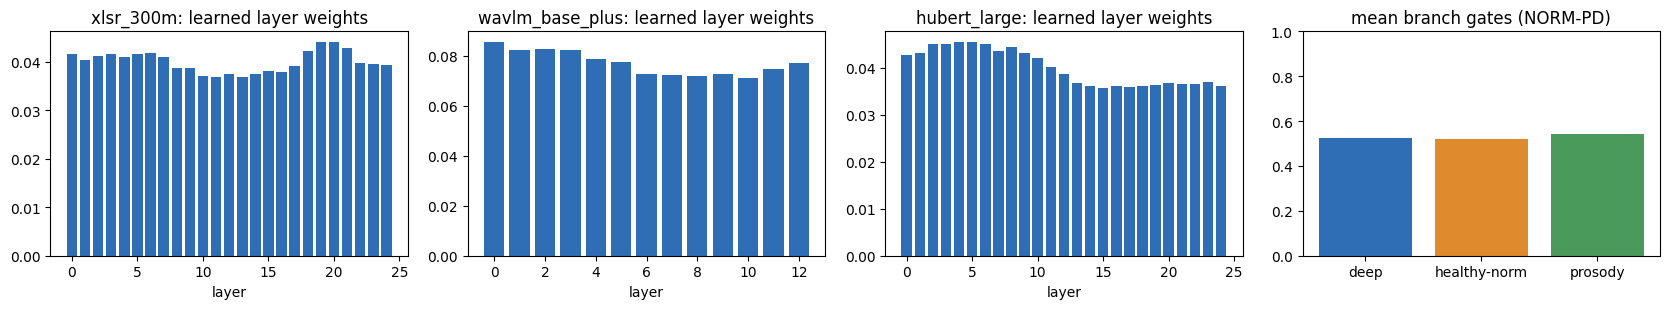

mean silence fraction alpha per backbone: {'xlsr_300m': np.float32(0.485), 'wavlm_base_plus': np.float32(0.487), 'hubert_large': np.float32(0.481)}


In [ ]:
# D4 · results: reference systems on the same chunks, paired tests, interpretability
def inner_layer_scores(Xs_tr, ys_tr, C=0.1):
    return np.array([_inner_auc(lambda: lr(C), Xs_tr[:, L], ys_tr) for L in range(Xs_tr.shape[1])])
def chunk_lr(Xtr, ytr, Xte, C=0.01):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
    return clf.fit(Xtr.astype(np.float32), ytr).predict_proba(Xte.astype(np.float32))[:, 1]

# R1: round-1 best recipe (in-fold layer pick + chunk LR) on exactly these chunks, XLS-R
Xc = SPX[0].numpy(); Xs_, ys_, spk_ = agg_speakers(Xc, SPK, Y); p_ref = np.zeros(len(ys_))
for i in range(len(ys_)):
    tr = np.arange(len(ys_)) != i; L = int(np.argmax(inner_layer_scores(Xs_[tr], ys_[tr])))
    p_ref[i] = chunk_lr(Xc[SPK != spk_[i], L], Y[SPK != spk_[i]], Xc[SPK == spk_[i], L]).mean()
register("R1 · XLS-R chunk LR, in-fold layer (same chunks)", "ReadText", ys_, p_ref, spk_, "NORM-PD-ref")

rows = []
ref = PROBS[("R1 · XLS-R chunk LR, in-fold layer (same chunks)", "ReadText")].reindex(SPEAKERS).values
base = PROBS.get(("egemaps · chunk SVM (baseline)", "ReadText"))
for r in [x for x in PART_C if x["exp"].startswith("NORM-PD")]:
    p = PROBS[(r["system"], "ReadText")].reindex(SPEAKERS).values
    n01, n10, pm, dci = paired_stats(YS, p, ref)
    row = dict(system=r["system"], bal_acc=r["bal_acc"], ci=f"[{r['ci_lo']:.2f}, {r['ci_hi']:.2f}]", auc=r["auc"],
               sens=r["sens"], spec=r["spec"], note=r["note"], vs_R1_fixed=n01, vs_R1_broken=n10, vs_R1_mcnemar_p=pm,
               vs_R1_dAUC=f"[{dci[0]:+.3f}, {dci[1]:+.3f}]")
    rows.append(row)
D = pd.DataFrame(rows); D.to_csv(RES/"norm_pd_results.csv", index=False); display(D.round(3))

hard = ["KCL16", "KCL17", "KCL30", "KCL34"]
H = pd.DataFrame({c.split(" · ")[0]: pd.Series(P_.mean(0), index=SPEAKERS)[hard] for c, P_ in NP_PROBS.items()})
H["R1"] = pd.Series(ref, index=SPEAKERS)[hard]; print("probabilities for the four hard PD speakers:"); display(H.round(2))

LW = [np.mean([lw[i] for lw in LAYERW], 0) for i in range(len(NP_MODELS))]
fig_, axes = plt.subplots(1, len(NP_MODELS) + 1, figsize=(4.2 * (len(NP_MODELS) + 1), 3.2))
for ax, m, w in zip(axes, NP_MODELS, LW):
    ax.bar(range(len(w)), w, color="#2f6db5"); ax.set_title(f"{m}: learned layer weights"); ax.set_xlabel("layer")
G = np.array(GATES).mean(0); A_ = np.array(ALPHAS).mean(0)
axes[-1].bar(["deep", "healthy-norm", "prosody"], G, color=["#2f6db5", "#e08a2e", "#4a9a5b"]); axes[-1].set_ylim(0, 1)
axes[-1].set_title("mean branch gates (NORM-PD)")
plt.tight_layout(); plt.savefig(RES/"norm_pd_interpretability.png", dpi=200); plt.show()
print("mean silence fraction alpha per backbone:", dict(zip(NP_MODELS, np.round(A_, 3))))

## D5 · Robustness of block 2 (silence-referenced channel normalisation)

Accuracy on ReadText cannot show what block 2 is for, because ReadText's silence carries almost no label information (B9). Two settings where recording conditions *do* matter:
1. **MDVR-KCL Dialogue, LOSO.** The phone-call silence leaks label information here (silence-only up to 0.70 BA in B9). Does subtracting the silence estimate (A2 vs A1) keep accuracy while removing the shortcut? X0 (silence only) measures how much shortcut is available to the same head.
2. **Cross-corpus transfer**, MDVR-KCL ReadText ↔ Figshare /a/ (different phones, sample rates and tasks). Train on all of one corpus, test on the other. Standardisation and healthy norms come from the source corpus only. If block 2 removes channel, transfer should improve.

In [ ]:
# D5 · robustness: Dialogue LOSO and cross-corpus transfer, with vs without silence channel normalisation
RT_STATE = (SPK, Y, SPX, SILX, SPEAKERS, SIDX, YT, YS, PRT)
ROB_CFGS = {k: v for k, v in CFGS.items() if k[:2] in ("A1", "A2", "A3", "X0")}
ROB_CFGS = {k: dict(v, pros=False) for k, v in ROB_CFGS.items()}

# (1) Dialogue LOSO with the same head (prosody branch off: prosody was computed on ReadText)
SPK, Y, SPX, SILX = load_task("dg")
SPEAKERS = np.unique(SPK); SIDX = torch.tensor(np.searchsorted(SPEAKERS, SPK)); YT = torch.tensor(Y, dtype=torch.float32)
YS = pd.Series(Y, index=SPK).groupby(level=0).first().reindex(SPEAKERS).values; PRT = torch.zeros(len(SPEAKERS), 1)
DG_PROBS = {c: np.zeros((3, len(SPEAKERS))) for c in ROB_CFGS}; t0 = time.time()
for k in range(len(SPEAKERS)):
    inputs = fold_inputs(k)
    for c, cfg in ROB_CFGS.items():
        for si, seed in enumerate((0, 1, 2)): DG_PROBS[c][si, k] = train_predict(cfg, inputs, k, seed)[0]
    if k % 6 == 0: print(f"Dialogue fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)
for c, P_ in DG_PROBS.items(): register(c, "Dialogue", YS, P_.mean(0), SPEAKERS, "NORM-PD-robust")
SPK, Y, SPX, SILX, SPEAKERS, SIDX, YT, YS, PRT = RT_STATE                  # restore ReadText state

# (2) cross-corpus transfer, statistics from the source corpus only
def load_set(tag):
    spk, y, xs, sil = load_task(tag); spks = np.unique(spk)
    return dict(spk=spk, y=y, xs=xs, sil=sil, spks=spks, sidx=torch.tensor(np.searchsorted(spks, spk)))

def transfer(cfg, src, tgt, seeds=(0, 1, 2), epochs=25, bs=64, lr=2e-3, n_pc=16):
    yS = torch.tensor(src["y"], dtype=torch.float32); hc = yS == 0
    XS, SS, XT, ST, dS, dT = [], [], [], [], [], []
    for X, S, Xt, St in zip(src["xs"], src["sil"], tgt["xs"], tgt["sil"]):
        mu, sd = X.mean(0), X.std(0) + 1e-5
        Z, Zt = (X - mu) / sd, (Xt - mu) / sd
        XS.append(Z); XT.append(Zt); SS.append(((S - mu) / sd)[src["sidx"]]); ST.append(((St - mu) / sd)[tgt["sidx"]])
        for L in range(Z.shape[1]):
            A = Z[hc, L]; c = A.mean(0); _, S_, V = torch.pca_lowrank(A - c, q=n_pc, center=False)
            var = S_ ** 2 / (A.shape[0] - 1) + 1e-6
            dS.append(torch.log1p((((Z[:, L] - c) @ V) ** 2 / var).mean(1))); dT.append(torch.log1p((((Zt[:, L] - c) @ V) ** 2 / var).mean(1)))
    dS, dT = torch.stack(dS, 1), torch.stack(dT, 1); m_, s_ = dS.mean(0), dS.std(0) + 1e-5; dS, dT = (dS - m_) / s_, (dT - m_) / s_
    XS, SS, XT, ST = [[t.to(DEV) for t in L_] for L_ in (XS, SS, XT, ST)]; dS, dT, yS = dS.to(DEV), dT.to(DEV), yS.to(DEV)
    if cfg.get("sil_only"): XS, XT = SS, ST
    pS, pT = torch.zeros(len(yS), 1, device=DEV), torch.zeros(XT[0].shape[0], 1, device=DEV)
    pw = (yS == 0).sum() / (yS == 1).sum(); probs = []
    for seed in seeds:
        torch.manual_seed(seed)
        net = NormPD(cfg, [x.shape[-1] for x in XS], [x.shape[1] for x in XS], dS.shape[1], 1).to(DEV)
        opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-2)
        for ep in range(epochs):
            net.train(); perm = torch.randperm(len(yS), device=DEV)
            for i in range(0, len(perm), bs):
                b = perm[i:i+bs]
                loss = F.binary_cross_entropy_with_logits(net([x[b] for x in XS], [s[b] for s in SS], dS[b], pS[b]), yS[b], pos_weight=pw)
                opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): p = torch.sigmoid(net(XT, ST, dT, pT)).cpu().numpy()
        probs.append(pd.Series(p, index=tgt["spk"]).groupby(level=0).mean().reindex(tgt["spks"]).values)
    yT = pd.Series(tgt["y"], index=tgt["spk"]).groupby(level=0).first().reindex(tgt["spks"]).values
    return metrics(yT, np.mean(probs, 0))

KCL_RT, FIGS = load_set("rt"), load_set("fig")
xrows = []
for c, cfg in ROB_CFGS.items():
    for name, s_, t_ in (("KCL ReadText -> Figshare /a/", KCL_RT, FIGS), ("Figshare /a/ -> KCL ReadText", FIGS, KCL_RT)):
        m = transfer(cfg, s_, t_); xrows.append(dict(direction=name, config=c, **m))
XR = pd.DataFrame(xrows); XR.to_csv(RES/"norm_pd_cross_corpus.csv", index=False)
R_ = pd.DataFrame([r for r in PART_C if r["exp"] == "NORM-PD-robust"])[["system", "bal_acc", "ci_lo", "ci_hi", "auc", "sens", "spec"]]
print("Dialogue (LOSO, 36 speakers):"); display(R_.round(3))
print("Cross-corpus transfer:"); display(XR.pivot_table(index="config", columns="direction", values=["bal_acc", "auc"]).round(3))

Dialogue fold 1/36 · 13 s
Dialogue fold 7/36 · 88 s
Dialogue fold 13/36 · 165 s
Dialogue fold 19/36 · 247 s
Dialogue fold 25/36 · 328 s
Dialogue fold 31/36 · 411 s
[NORM-PD-robust] A1 · + cross-model                 Dialogue  BA=0.829 [0.69,0.96] AUC=0.879 
[NORM-PD-robust] A2 · + silence channel norm        Dialogue  BA=0.819 [0.67,0.94] AUC=0.879 
[NORM-PD-robust] A3 · + healthy-norm deviation      Dialogue  BA=0.819 [0.67,0.94] AUC=0.870 
[NORM-PD-robust] X0 · control: silence only         Dialogue  BA=0.648 [0.49,0.81] AUC=0.797 
Dialogue (LOSO, 36 speakers):


,system,bal_acc,ci_lo,ci_hi,auc,sens,spec
0,A1 · + cross-model,0.829,0.694,0.957,0.879,0.800,0.857
1,A2 · + silence channel norm,0.819,0.667,0.941,0.879,0.733,0.905
2,A3 · + healthy-norm deviation,0.819,0.667,0.941,0.870,0.733,0.905
3,X0 · control: silence only,0.648,0.492,0.810,0.797,0.533,0.762


Cross-corpus transfer:


auc  \
direction                     Figshare /a/ -> KCL ReadText   
config                                                       
A1 · + cross-model                                   0.524   
A2 · + silence channel norm                          0.482   
A3 · + healthy-norm deviation                        0.461   
X0 · control: silence only                           0.512   

                                                            \
direction                     KCL ReadText -> Figshare /a/   
config                                                       
A1 · + cross-model                                   0.613   
A2 · + silence channel norm                          0.496   
A3 · + healthy-norm deviation                        0.493   
X0 · control: silence only                           0.538   

                                                   bal_acc  \
direction                     Figshare /a/ -> KCL ReadText   
config                                                       
A1 · + cross-model                                     0.5   
A2 · + silence channel norm                            0.5   
A3 · + healthy-norm deviation                          0.5   
X0 · control: silence only                             0.5   

                                                            
direction                     KCL ReadText -> Figshare /a/  
config                                                      
A1 · + cross-model                                   0.500  
A2 · + silence channel norm                          0.500  
A3 · + healthy-norm deviation                        0.488  
X0 · control: silence only                           0.500

## D6 · Regularised NORM-PD (pre-registered after the D3 ablation)

D3 showed the head overfits: each added block lowered ReadText accuracy (A0 0.890 → A4 0.820), with ~200k trainable parameters for 37 speakers. D6 changes **only capacity**, with settings fixed in advance and not tuned on test speakers: projection width 64 → 16, dropout 0.3 → 0.5, weight decay 0.01 → 0.05, epochs 25 → 15, and 5 seeds instead of 3. Every variant is reported, so the ablation stays honest. **B3** tests block 3 alone, a pure "distance from healthy speech" detector with no deep branch.

In [ ]:
# D6 · regularised NORM-PD variants, 5 seeds, LOSO ReadText
class NormPD(nn.Module):                                   # same blocks as D3; capacity now set by cfg
    def __init__(s, cfg, dims, Ls, n_dev, n_pros):
        super().__init__(); s.cfg = cfg; d, pdrop = cfg.get("d", 64), cfg.get("drop", 0.3)
        s.deep = cfg.get("deep", True)
        s.ms = list(range(len(dims))) if cfg["cross"] else [0]
        s.lw = nn.ParameterList([nn.Parameter(torch.zeros(L)) for L in Ls])
        s.alpha = nn.Parameter(torch.zeros(len(dims)))
        s.P = nn.ModuleList([nn.Linear(H, d) for H in dims])
        width = d * len(s.ms) if s.deep else 0; s.ln = nn.LayerNorm(max(width, 1))
        s.dev = nn.Linear(n_dev, 16) if cfg["dev"] else None
        s.pros = nn.Linear(n_pros, 16) if cfg["pros"] else None
        s.gate = nn.Parameter(torch.zeros(3))
        s.head = nn.Sequential(nn.Dropout(pdrop), nn.Linear(width + 16 * cfg["dev"] + 16 * cfg["pros"], 32),
                               nn.GELU(), nn.Dropout(pdrop), nn.Linear(32, 1))
    def forward(s, xs, ss, dev, pros):
        g = torch.sigmoid(s.gate); parts = []
        if s.deep:
            hs = []
            for m in s.ms:
                w = torch.softmax(s.lw[m], 0).view(1, -1, 1); e = (w * xs[m]).sum(1)
                if s.cfg["sil"]: e = e - torch.sigmoid(s.alpha[m]) * (w * ss[m]).sum(1)
                hs.append(s.P[m](e))
            parts.append(g[0] * s.ln(torch.cat(hs, -1)))
        if s.dev is not None: parts.append(g[1] * F.gelu(s.dev(dev)))
        if s.pros is not None: parts.append(g[2] * F.gelu(s.pros(pros)))
        return s.head(torch.cat(parts, -1)).squeeze(-1)

def train_predict(cfg, inputs, k, seed, bs=64, lr=2e-3):
    epochs, wd = cfg.get("epochs", 25), cfg.get("wd", 1e-2)
    xs, ss, dev, pros = [t.to(DEV) if torch.is_tensor(t) else [u.to(DEV) for u in t] for t in inputs]
    sidx, yt = SIDX.to(DEV), YT.to(DEV)
    if cfg.get("sil_only"): xs = [S[sidx] for S in ss]
    torch.manual_seed(seed)
    tr = torch.where(sidx != k)[0]; te = torch.where(sidx == k)[0]
    net = NormPD(cfg, [x.shape[-1] for x in xs], [x.shape[1] for x in xs], dev.shape[1], pros.shape[1]).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd); pw = (yt[tr] == 0).sum() / (yt[tr] == 1).sum()
    for ep in range(epochs):
        net.train(); perm = tr[torch.randperm(len(tr), device=DEV)]
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]; sb = sidx[b]
            loss = F.binary_cross_entropy_with_logits(net([x[b] for x in xs], [S[sb] for S in ss], dev[b], pros[sb]), yt[b], pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        p = torch.sigmoid(net([x[te] for x in xs], [S[sidx[te]] for S in ss], dev[te], pros[sidx[te]])).mean().item()
    return p, net

REG = dict(d=16, drop=0.5, wd=0.05, epochs=15)
CFGS6 = {
    "B0 · A0 (XLS-R layer attention), 5 seeds": dict(cross=False, sil=False, dev=False, pros=False),
    "B1 · regularised + cross-model + silence norm": dict(cross=True, sil=True, dev=False, pros=False, **REG),
    "B2 · regularised NORM-PD (all blocks)": dict(cross=True, sil=True, dev=True, pros=True, **REG),
    "B3 · healthy-norm deviation only": dict(cross=True, sil=False, dev=True, pros=False, deep=False, **REG),
    "B4 · regularised XLS-R + silence norm": dict(cross=False, sil=True, dev=False, pros=False, **REG),
}
SEEDS6 = (0, 1, 2, 3, 4)
P6 = {c: np.zeros((len(SEEDS6), len(SPEAKERS))) for c in CFGS6}; t0 = time.time()
for k in range(len(SPEAKERS)):
    inputs = fold_inputs(k)
    for c, cfg in CFGS6.items():
        for si, seed in enumerate(SEEDS6): P6[c][si, k] = train_predict(cfg, inputs, k, seed)[0]
    if k % 6 == 0 or k == len(SPEAKERS) - 1: print(f"fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)
np.savez(RES/"norm_pd_d6_probs.npz", speakers=SPEAKERS, y=YS, **{c.split(" · ")[0]: v for c, v in P6.items()})
ref = PROBS[("R1 · XLS-R chunk LR, in-fold layer (same chunks)", "ReadText")].reindex(SPEAKERS).values
rows6 = []
for c, P_ in P6.items():
    seed_ba = [metrics(YS, P_[s])["bal_acc"] for s in range(len(SEEDS6))]
    r = register(c, "ReadText", YS, P_.mean(0), SPEAKERS, "NORM-PD-D6", f"per-seed BA {np.mean(seed_ba):.3f} ± {np.std(seed_ba):.3f}")
    n01, n10, pm, dci = paired_stats(YS, P_.mean(0), ref)
    rows6.append(dict(system=c, bal_acc=r["bal_acc"], auc=r["auc"], sens=r["sens"], spec=r["spec"], seed_BA=f"{np.mean(seed_ba):.3f} ± {np.std(seed_ba):.3f}",
                      vs_R1=f"+{n01}/-{n10}, p={pm:.2f}", dAUC_vs_R1=f"[{dci[0]:+.3f}, {dci[1]:+.3f}]",
                      hard_four=" ".join(f"{v:.2f}" for v in pd.Series(P_.mean(0), index=SPEAKERS)[["KCL16", "KCL17", "KCL30", "KCL34"]])))
D6 = pd.DataFrame(rows6); D6.to_csv(RES/"norm_pd_d6.csv", index=False); display(D6.round(3))

fold 1/37 · 22 s
fold 7/37 · 156 s
fold 13/37 · 290 s
fold 19/37 · 425 s
fold 25/37 · 558 s
fold 31/37 · 692 s
fold 37/37 · 827 s
[NORM-PD-D6] B0 · A0 (XLS-R layer attention), 5 seeds ReadText  BA=0.859 [0.73,0.97] AUC=0.935 per-seed BA 0.860 ± 0.037
[NORM-PD-D6] B1 · regularised + cross-model + silence norm ReadText  BA=0.844 [0.73,0.95] AUC=0.920 per-seed BA 0.837 ± 0.016
[NORM-PD-D6] B2 · regularised NORM-PD (all blocks) ReadText  BA=0.882 [0.77,0.98] AUC=0.914 per-seed BA 0.845 ± 0.029
[NORM-PD-D6] B3 · healthy-norm deviation only   ReadText  BA=0.619 [0.53,0.71] AUC=0.738 per-seed BA 0.629 ± 0.012
[NORM-PD-D6] B4 · regularised XLS-R + silence norm ReadText  BA=0.851 [0.73,0.96] AUC=0.917 per-seed BA 0.813 ± 0.023


,system,bal_acc,auc,sens,spec,seed_BA,vs_R1,dAUC_vs_R1,hard_four
0,"B0 · A0 (XLS-R layer attention), 5 seeds",0.859,0.935,0.812,0.905,0.860 ± 0.037,"+1/-2, p=1.00","[-0.052, +0.073]",0.33 0.53 0.50 0.04
1,B1 · regularised + cross-model + silence norm,0.844,0.920,0.688,1.000,0.837 ± 0.016,"+0/-1, p=1.00","[-0.065, +0.044]",0.16 0.22 0.39 0.01
2,B2 · regularised NORM-PD (all blocks),0.882,0.914,0.812,0.952,0.845 ± 0.029,"+1/-1, p=1.00","[-0.067, +0.047]",0.15 0.36 0.68 0.00
3,B3 · healthy-norm deviation only,0.619,0.738,1.000,0.238,0.629 ± 0.012,"+4/-16, p=0.01","[-0.361, -0.029]",0.80 0.83 0.98 0.80
4,B4 · regularised XLS-R + silence norm,0.851,0.917,0.750,0.952,0.813 ± 0.023,"+0/-1, p=1.00","[-0.094, +0.067]",0.35 0.30 0.08 0.04


## D7 · Channel-shift stress test: what block 2 is actually for

ReadText accuracy can't show a channel-robustness benefit, because MDVR-KCL ReadText has little channel leakage (B9, X0). So here the channel is changed on purpose, only at test time. Every held-out speaker's whole recording (speech **and** silence) goes through a simulated device change:
- a telephone-like band-pass (≈300–3400 Hz),
- stationary noise at 15–25 dB SNR,
- a ±6 dB gain change.

Models train on clean recordings of the other 36 speakers, as before. If silence-referenced normalisation removes channel information, the drop from clean to shifted should be **smaller with block 2 than without**. Settings are the D3 defaults (no tuning). The perturbation for each speaker is seeded from their ID, so the test is reproducible.

In [ ]:
# D7 · channel-shift robustness: train clean, test on simulated device change (LOSO, ReadText)
from scipy.signal import butter, sosfilt
def shift_channel(y, seed):
    rng = np.random.default_rng(seed)
    sos = butter(4, [rng.uniform(250, 400), rng.uniform(3000, 3600)], btype="band", fs=SR, output="sos")
    y = sosfilt(sos, y)
    y = y + rng.normal(0, 1, len(y)) * np.std(y) / 10 ** (rng.uniform(15, 25) / 20)
    return np.clip(y * 10 ** (rng.uniform(-6, 6) / 20), -1, 1).astype(np.float32)

def extract_shift(name, mode, bs=16):
    out = FEAT/f"rtp_{mode}_{name}.npz"
    if out.exists(): return out
    hf_id = NP_BACKBONES[name]
    fe = AutoFeatureExtractor.from_pretrained(hf_id); model = AutoModel.from_pretrained(hf_id).eval().to(DEV)
    if DEV == "cuda": model = model.half()
    embs, spk, lab = [], [], []
    for r in RT.itertuples():
        y = shift_channel(rms_normalize(load_audio(r.path)), seed=int(r.speaker[3:]))
        chs = chunk(apply_mode(y, mode), win_s=4.0, hop_s=4.0)
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(DEV)
            if DEV == "cuda": x = x.half()
            with torch.no_grad(): h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out

for name in NP_MODELS:
    for mode in ("speech", "silence"): extract_shift(name, mode)
SPKp, Yp, SPXp, SILXp = load_task("rtp"); SIDXp = torch.tensor(np.searchsorted(SPEAKERS, SPKp))

def shift_eval(cfg, k, seed, epochs=25, bs=64, lr=2e-3):
    tr = torch.where(SIDX != k)[0]; tep = torch.where(SIDXp == k)[0]
    Xtr, Str, Xte, Ste = [], [], [], []
    for X, S, Xp, Sp in zip(SPX, SILX, SPXp, SILXp):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-5
        Xtr.append(((X[tr] - mu) / sd).to(DEV)); Str.append(((S - mu) / sd)[SIDX[tr]].to(DEV))
        Xte.append(((Xp[tep] - mu) / sd).to(DEV)); Ste.append(((Sp[k:k+1] - mu) / sd).expand(len(tep), -1, -1).to(DEV))
    ytr = YT[tr].to(DEV); z = lambda n: torch.zeros(n, 1, device=DEV)
    torch.manual_seed(seed)
    net = NormPD(cfg, [x.shape[-1] for x in Xtr], [x.shape[1] for x in Xtr], 1, 1).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=cfg.get("wd", 1e-2)); pw = (ytr == 0).sum() / (ytr == 1).sum()
    for ep in range(cfg.get("epochs", epochs)):
        net.train(); perm = torch.randperm(len(ytr), device=DEV)
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            loss = F.binary_cross_entropy_with_logits(net([x[b] for x in Xtr], [s[b] for s in Str], z(len(b)), z(len(b))), ytr[b], pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad(): return torch.sigmoid(net(Xte, Ste, z(len(tep)), z(len(tep)))).mean().item()

SHIFT_CFGS = {
    "XLS-R, no channel norm":        dict(cross=False, sil=False, dev=False, pros=False),
    "XLS-R + silence channel norm":  dict(cross=False, sil=True,  dev=False, pros=False),
    "3 backbones, no channel norm":  dict(cross=True,  sil=False, dev=False, pros=False),
    "3 backbones + silence channel norm": dict(cross=True, sil=True, dev=False, pros=False),
}
PS = {c: np.zeros((3, len(SPEAKERS))) for c in SHIFT_CFGS}; t0 = time.time()
for k in range(len(SPEAKERS)):
    for c, cfg in SHIFT_CFGS.items():
        for si, seed in enumerate((0, 1, 2)): PS[c][si, k] = shift_eval(cfg, k, seed)
    if k % 6 == 0 or k == len(SPEAKERS) - 1: print(f"shift fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)
clean_ref = {"XLS-R, no channel norm": "A0 · layer attention, XLS-R only", "3 backbones, no channel norm": "A1 · + cross-model",
             "3 backbones + silence channel norm": "A2 · + silence channel norm"}
rows7 = []
for c, P_ in PS.items():
    m = metrics(YS, P_.mean(0)); reg = register(c + " [shifted test]", "ReadText", YS, P_.mean(0), SPEAKERS, "NORM-PD-shift")
    cl = PROBS.get((clean_ref.get(c, ""), "ReadText"))
    mc = metrics(YS, cl.reindex(SPEAKERS).values) if cl is not None else None
    rows7.append(dict(config=c, shifted_BA=m["bal_acc"], shifted_AUC=m["auc"],
                      clean_BA=mc["bal_acc"] if mc else np.nan, clean_AUC=mc["auc"] if mc else np.nan,
                      AUC_drop=(mc["auc"] - m["auc"]) if mc else np.nan))
D7 = pd.DataFrame(rows7); D7.to_csv(RES/"norm_pd_channel_shift.csv", index=False); display(D7.round(3))

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

shift fold 1/37 · 28 s
shift fold 7/37 · 193 s
shift fold 13/37 · 357 s
shift fold 19/37 · 522 s
shift fold 25/37 · 686 s
shift fold 31/37 · 850 s
shift fold 37/37 · 1014 s
[NORM-PD-shift] XLS-R, no channel norm [shifted test] ReadText  BA=0.781 [0.65,0.91] AUC=0.943 
[NORM-PD-shift] XLS-R + silence channel norm [shifted test] ReadText  BA=0.531 [0.50,0.60] AUC=0.872 
[NORM-PD-shift] 3 backbones, no channel norm [shifted test] ReadText  BA=0.719 [0.60,0.85] AUC=0.887 
[NORM-PD-shift] 3 backbones + silence channel norm [shifted test] ReadText  BA=0.531 [0.50,0.60] AUC=0.836 


,config,shifted_BA,shifted_AUC,clean_BA,clean_AUC,AUC_drop
0,"XLS-R, no channel norm",0.781,0.943,0.890,0.938,-0.006
1,XLS-R + silence channel norm,0.531,0.872,NaN,NaN,NaN
2,"3 backbones, no channel norm",0.719,0.887,0.827,0.938,0.051
3,3 backbones + silence channel norm,0.531,0.836,0.851,0.914,0.077


## D8 · Block 3 fixed with cross-fitting

D6 exposed a train/test mismatch in block 3. Training speakers' deviation scores were computed against a healthy norm that *their own chunks helped fit* (in-sample, so the scores came out small). The held-out speaker is always out-of-sample (large score). Every test speaker therefore looked "far from healthy": B3 reached sensitivity 1.00 but specificity 0.24.

**Fix (cross-fitting):** healthy training speakers are split into 5 groups, and each group's deviation is measured against a norm fitted on the other 4. PD training speakers and the test speaker are measured against the norm of all healthy training speakers. Now every deviation score the head sees, in training and at test time, is out-of-sample. This is a correctness fix, not tuning; the settings are the D6 regularised ones.

In [ ]:
# D8 · cross-fitted healthy-norm deviation (block 3) + re-run of the configs that use it
def fold_inputs_cf(k, n_pc=16, K=5):
    tr = SIDX != k; tr_spk = torch.arange(len(SPEAKERS)) != k
    hc_spk = [i for i in range(len(SPEAKERS)) if i != k and YS[i] == 0]
    groups = np.array_split(np.random.default_rng(0).permutation(hc_spk), K)
    hc_t = torch.tensor(hc_spk); in_hc = torch.isin(SIDX, hc_t)
    xs, ss, devs = [], [], []
    for X, S in zip(SPX, SILX):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-5; Z = (X - mu) / sd
        xs.append(Z); ss.append((S - mu) / sd)
        for L in range(Z.shape[1]):
            def norm_fn(spk_list):
                A = Z[torch.isin(SIDX, torch.tensor(list(spk_list))), L]; c = A.mean(0)
                _, S_, V = torch.pca_lowrank(A - c, q=n_pc, center=False); var = S_ ** 2 / (A.shape[0] - 1) + 1e-6
                return lambda B: torch.log1p((((B - c) @ V) ** 2 / var).mean(1))
            out = torch.zeros(Z.shape[0])
            out[~in_hc] = norm_fn(hc_spk)(Z[~in_hc, L])                    # PD training speakers + the test speaker
            for g in groups:                                                  # healthy training speakers: out-of-fold norm
                gm = torch.isin(SIDX, torch.tensor(g)); out[gm] = norm_fn(set(hc_spk) - set(g.tolist()))(Z[gm, L])
            devs.append(out)
    dev = torch.stack(devs, 1); dev = (dev - dev[tr].mean(0)) / (dev[tr].std(0) + 1e-5)
    pros = (PRT - PRT[tr_spk].mean(0)) / (PRT[tr_spk].std(0) + 1e-5)
    return xs, ss, dev, pros

CFGS8 = {
    "B3cf · healthy-norm deviation only (cross-fitted)": dict(cross=True, sil=False, dev=True, pros=False, deep=False, **REG),
    "B5cf · XLS-R layer attention + healthy norm (cross-fitted)": dict(cross=False, sil=False, dev=True, pros=False, **REG),
    "B2cf · regularised NORM-PD, all blocks (cross-fitted)": dict(cross=True, sil=True, dev=True, pros=True, **REG),
}
P8 = {c: np.zeros((len(SEEDS6), len(SPEAKERS))) for c in CFGS8}; t0 = time.time()
for k in range(len(SPEAKERS)):
    inputs = fold_inputs_cf(k)
    for c, cfg in CFGS8.items():
        for si, seed in enumerate(SEEDS6): P8[c][si, k] = train_predict(cfg, inputs, k, seed)[0]
    if k % 6 == 0 or k == len(SPEAKERS) - 1: print(f"fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)
np.savez(RES/"norm_pd_d8_probs.npz", speakers=SPEAKERS, y=YS, **{c.split(" · ")[0]: v for c, v in P8.items()})
rows8 = []
for c, P_ in P8.items():
    seed_ba = [metrics(YS, P_[s])["bal_acc"] for s in range(len(SEEDS6))]
    r = register(c, "ReadText", YS, P_.mean(0), SPEAKERS, "NORM-PD-D8", f"per-seed BA {np.mean(seed_ba):.3f} ± {np.std(seed_ba):.3f}")
    n01, n10, pm, dci = paired_stats(YS, P_.mean(0), ref)
    rows8.append(dict(system=c, bal_acc=r["bal_acc"], auc=r["auc"], sens=r["sens"], spec=r["spec"], seed_BA=f"{np.mean(seed_ba):.3f} ± {np.std(seed_ba):.3f}",
                      vs_R1=f"+{n01}/-{n10}, p={pm:.2f}", dAUC_vs_R1=f"[{dci[0]:+.3f}, {dci[1]:+.3f}]",
                      hard_four=" ".join(f"{v:.2f}" for v in pd.Series(P_.mean(0), index=SPEAKERS)[["KCL16", "KCL17", "KCL30", "KCL34"]])))
D8 = pd.DataFrame(rows8); D8.to_csv(RES/"norm_pd_d8.csv", index=False); display(D8.round(3))

fold 1/37 · 16 s
fold 7/37 · 102 s
fold 13/37 · 186 s
fold 19/37 · 275 s
fold 25/37 · 361 s
fold 31/37 · 450 s
fold 37/37 · 536 s
[NORM-PD-D8] B3cf · healthy-norm deviation only (cross-fitted) ReadText  BA=0.740 [0.60,0.89] AUC=0.851 per-seed BA 0.754 ± 0.012
[NORM-PD-D8] B5cf · XLS-R layer attention + healthy norm (cross-fitted) ReadText  BA=0.796 [0.66,0.92] AUC=0.935 per-seed BA 0.819 ± 0.034
[NORM-PD-D8] B2cf · regularised NORM-PD, all blocks (cross-fitted) ReadText  BA=0.844 [0.72,0.95] AUC=0.920 per-seed BA 0.834 ± 0.012


,system,bal_acc,auc,sens,spec,seed_BA,vs_R1,dAUC_vs_R1,hard_four
0,B3cf · healthy-norm deviation only (cross-fitted),0.740,0.851,0.812,0.667,0.754 ± 0.012,"+1/-7, p=0.07","[-0.199, +0.026]",0.44 0.39 0.54 0.39
1,B5cf · XLS-R layer attention + healthy norm (c...,0.796,0.935,0.688,0.905,0.819 ± 0.034,"+0/-3, p=0.25","[-0.047, +0.065]",0.45 0.46 0.42 0.03
2,"B2cf · regularised NORM-PD, all blocks (cross-...",0.844,0.920,0.688,1.000,0.834 ± 0.012,"+0/-1, p=1.00","[-0.077, +0.059]",0.14 0.28 0.25 0.01


## D9 · Temporal "sequence effect" block (clinically motivated)

People with PD show a **sequence effect**: motor output, including speech loudness and articulation, deteriorates *progressively* during a continuous task. Every MDVR-KCL ReadText speaker reads the same ~2-minute passage, so the trajectory of PD-likeness across the recording carries information that a plain average over chunks throws away. This also targets the hard four, who look normal *on average* (C9, C10).

Method, all inside each LOSO fold:
1. XLS-R layer chosen by inner CV on training speakers (as in R1).
2. **Cross-fitted chunk scores.** Training speakers are split into 5 groups; each group's chunks are scored by a chunk-level LR fitted on the other 4 groups, so every training score is out-of-sample. The test speaker is scored by the LR fitted on all training speakers.
3. **Per-speaker trajectory features:** mean logit, slope of logit vs. position in the recording, last-third minus first-third, and SD.
4. A speaker-level logistic regression on the mean alone vs. mean + trajectory (fixed C = 1).

In [ ]:
# D9 · sequence-effect features from cross-fitted chunk scores (XLS-R), LOSO ReadText
from scipy.special import logit as _logit
Xc = SPX[0].numpy()                                         # XLS-R mean-pooled, all layers, chunks in time order per speaker
Xs_x, ys_x, spk_x = agg_speakers(Xc, SPK, Y)
pos = np.zeros(len(SPK))
for s_ in np.unique(SPK):
    m = np.where(SPK == s_)[0]; pos[m] = np.linspace(0, 1, len(m)) if len(m) > 1 else 0.5
def traj(scores, p):
    if len(scores) < 3: return [scores.mean(), 0.0, 0.0, scores.std()]
    slope = np.polyfit(p, scores, 1)[0]; n3 = max(1, len(scores) // 3)
    return [scores.mean(), slope, scores[-n3:].mean() - scores[:n3].mean(), scores.std()]

feats_all = {}
p_mean, p_traj = np.zeros(len(SPEAKERS)), np.zeros(len(SPEAKERS)); t0 = time.time()
for k, sk in enumerate(SPEAKERS):
    i_sp = list(spk_x).index(sk); tr_s = np.array([s_ for s_ in spk_x if s_ != sk])
    tr_mask = np.arange(len(spk_x)) != i_sp
    L = int(np.argmax(inner_layer_scores(Xs_x[tr_mask], ys_x[tr_mask])))
    groups = np.array_split(np.random.default_rng(0).permutation(tr_s), 5)
    sc = np.zeros(len(SPK))
    for g in groups:                                          # out-of-fold chunk scores for training speakers
        fit_m = np.isin(SPK, tr_s) & ~np.isin(SPK, g); app = np.isin(SPK, g)
        sc[app] = _logit(np.clip(chunk_lr(Xc[fit_m, L], Y[fit_m], Xc[app, L]), 1e-4, 1 - 1e-4))
    te = SPK == sk; fit_all = np.isin(SPK, tr_s)
    sc[te] = _logit(np.clip(chunk_lr(Xc[fit_all, L], Y[fit_all], Xc[te, L]), 1e-4, 1 - 1e-4))
    F_ = np.array([traj(sc[SPK == s_], pos[SPK == s_]) for s_ in SPEAKERS])
    feats_all[sk] = F_[k]
    trk = np.arange(len(SPEAKERS)) != k
    m1 = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)).fit(F_[trk][:, :1], YS[trk])
    m2 = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)).fit(F_[trk], YS[trk])
    p_mean[k] = m1.predict_proba(F_[k:k+1, :1])[0, 1]; p_traj[k] = m2.predict_proba(F_[k:k+1])[0, 1]
    if k % 6 == 0: print(f"fold {k+1}/{len(SPEAKERS)} · {round(time.time()-t0)} s", flush=True)

for name, p in (("D9 · cross-fitted chunk score, mean only", p_mean), ("D9 · + sequence-effect trajectory features", p_traj)):
    register(name, "ReadText", YS, p, SPEAKERS, "NORM-PD-D9")
    n01, n10, pm, dci = paired_stats(YS, p, ref)
    print(f"   vs R1: +{n01}/-{n10}, McNemar p={pm:.2f}, dAUC CI [{dci[0]:+.3f}, {dci[1]:+.3f}]; hard four:",
          np.round(pd.Series(p, index=SPEAKERS)[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2))
TF = pd.DataFrame(feats_all, index=["mean_logit", "slope", "late_minus_early", "sd"]).T
TF["label"] = YS; display(TF.groupby("label").mean().round(3))
print("hard four trajectory features:"); display(TF.loc[["KCL16", "KCL17", "KCL30", "KCL34"]].round(3))

fold 1/37 · 4 s
fold 7/37 · 24 s
fold 13/37 · 43 s
fold 19/37 · 62 s
fold 25/37 · 84 s
fold 31/37 · 103 s
fold 37/37 · 121 s
[NORM-PD-D9] D9 · cross-fitted chunk score, mean only ReadText  BA=0.938 [0.84,1.00] AUC=0.911 
   vs R1: +2/-0, McNemar p=0.50, dAUC CI [-0.047, +0.000]; hard four: [0.54 0.27 0.5  0.1 ]
[NORM-PD-D9] D9 · + sequence-effect trajectory features ReadText  BA=0.969 [0.89,1.00] AUC=0.938 
   vs R1: +3/-0, McNemar p=0.25, dAUC CI [-0.029, +0.074]; hard four: [0.53 0.64 0.52 0.09]


,mean_logit,slope,late_minus_early,sd
label,,,,
0,-2.082,-0.638,-0.413,1.197
1,2.005,0.435,0.358,1.484


hard four trajectory features:


,mean_logit,slope,late_minus_early,sd,label
KCL16,-0.332,-0.433,-0.499,0.845,1
KCL17,-2.553,-6.586,-4.344,2.797,1
KCL30,-0.291,-1.310,-0.723,1.013,1
KCL34,-3.539,-3.498,-2.169,1.726,1


In [ ]:
from sklearn.metrics import balanced_accuracy_score as bal_acc
# D9b · robustness of D9: 5 cross-fitting seeds + a shuffled-time control (are the gains really from the time order?)
def run_d9(seed, shuffle_time=False):
    rng = np.random.default_rng(seed); pos_ = pos.copy()
    if shuffle_time:
        for s_ in np.unique(SPK):
            m = np.where(SPK == s_)[0]; pos_[m] = rng.permutation(pos_[m])
    pm_, pt_ = np.zeros(len(SPEAKERS)), np.zeros(len(SPEAKERS))
    for k, sk in enumerate(SPEAKERS):
        i_sp = list(spk_x).index(sk); tr_s = np.array([s_ for s_ in spk_x if s_ != sk])
        tr_mask = np.arange(len(spk_x)) != i_sp
        L = LCACHE.setdefault(sk, int(np.argmax(inner_layer_scores(Xs_x[tr_mask], ys_x[tr_mask]))))
        sc = np.zeros(len(SPK))
        for g in np.array_split(rng.permutation(tr_s), 5):
            fit_m = np.isin(SPK, tr_s) & ~np.isin(SPK, g); app = np.isin(SPK, g)
            sc[app] = _logit(np.clip(chunk_lr(Xc[fit_m, L], Y[fit_m], Xc[app, L]), 1e-4, 1 - 1e-4))
        te = SPK == sk; fit_all = np.isin(SPK, tr_s)
        sc[te] = _logit(np.clip(chunk_lr(Xc[fit_all, L], Y[fit_all], Xc[te, L]), 1e-4, 1 - 1e-4))
        F_ = np.array([traj(sc[SPK == s_], pos_[SPK == s_]) for s_ in SPEAKERS]); trk = np.arange(len(SPEAKERS)) != k
        for cols, out in (([0], pm_), ([0, 1, 2, 3], pt_)):
            mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)).fit(F_[trk][:, cols], YS[trk])
            out[k] = mdl.predict_proba(F_[k:k+1, cols])[0, 1]
    return pm_, pt_
LCACHE = {}; rows = []; t0 = time.time()
for seed in range(5):
    for shuf in (False, True):
        pm_, pt_ = run_d9(seed, shuf)
        for nm, p in (("mean only", pm_), ("mean + trajectory", pt_)):
            rows.append(dict(seed=seed, time_order="shuffled" if shuf else "real", model=nm,
                             BA=bal_acc(YS, (p >= .5).astype(int)), AUC=_auc(YS, p)))
    print(f"seed {seed} done · {round(time.time()-t0)} s", flush=True)
R9 = pd.DataFrame(rows); R9.to_csv(RES / "norm_pd_d9_robust.csv", index=False)
display(R9.groupby(["time_order", "model"])[["BA", "AUC"]].agg(["mean", "std"]).round(3))

seed 0 done · 237 s
seed 1 done · 479 s
seed 2 done · 718 s
seed 3 done · 956 s
seed 4 done · 1195 s


BA           AUC       
                               mean    std   mean    std
time_order model                                        
real       mean + trajectory  0.921  0.029  0.926  0.015
           mean only          0.925  0.017  0.915  0.008
shuffled   mean + trajectory  0.928  0.025  0.920  0.026
           mean only          0.904  0.023  0.917  0.009

## D10 · STRIDE-PD: Sequence-effect TRajectory pooling with Interpretable DEcomposition

**Architectural contribution.** Speech-PD models pool chunk embeddings by *mean* or *attention*, both of which are order-invariant: they discard *when* in the recording a chunk occurred. STRIDE-PD replaces the pooling layer with a **differentiable trajectory pooling (DTP)** operator that encodes the clinical sequence effect directly in the network:

1. **Layer-attention encoder** (block 1 of NORM-PD, the part that survived ablation): softmax weights over the 25 frozen XLS-R layers → chunk embedding → small MLP → chunk PD-logit $z_i$.
2. **DTP layer:** for each speaker, a closed-form least-squares fit of $z_i$ against normalised time $\tau_i$ gives **level** $a$ (mean), **drift** $b$ (slope), and **instability** $r$ (residual SD). This is exact and fully differentiable, so gradients from the speaker decision flow back into the chunk encoder and the layer weights.
3. **Interpretable decision head:** speaker logit $= w_a a + w_b b + w_r r + c$, so every prediction decomposes into "how PD-like", "how much it worsens over the task", and "how unstable".
4. **Training:** speaker-level BCE + auxiliary chunk BCE (λ = 0.5), random chunk subsampling per epoch, dropout 0.5, weight decay; all inside each LOSO fold, 3 seeds.

Controls: **mean pooling** (same network, DTP replaced by mean) and **DTP with shuffled time** (same network, chunk order scrambled). If DTP > shuffled-DTP, the gain is from temporal order, not from extra parameters.

In [ ]:
from sklearn.metrics import balanced_accuracy_score
# D10 · STRIDE-PD (differentiable trajectory pooling) vs mean pooling vs shuffled-time DTP · LOSO ReadText
import torch, torch.nn as nn, torch.nn.functional as Fnn
dev = "cuda" if torch.cuda.is_available() else "cpu"
XT = torch.tensor(np.asarray(Xc, dtype=np.float32), device=dev)          # [chunks, layers, dim], time-ordered per speaker
NL, DIM = XT.shape[1], XT.shape[2]
SP_IDX = {s_: np.where(SPK == s_)[0] for s_ in SPEAKERS}
SP_Y = dict(zip(SPEAKERS, YS))

class STRIDE(nn.Module):
    def __init__(s, pool="dtp", d=32, drop=0.5):
        super().__init__(); s.pool = pool
        s.lw = nn.Parameter(torch.zeros(NL))
        s.enc = nn.Sequential(nn.Dropout(0.2), nn.Linear(DIM, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, 1))
        s.head = nn.Linear(3 if pool == "dtp" else 1, 1)
    def chunk_logits(s, x):                                              # x [n, layers, dim] (already standardised)
        w = torch.softmax(s.lw, 0).view(1, -1, 1)
        return s.enc((w * x).sum(1)).squeeze(-1)
    def forward(s, x, tau):
        z = s.chunk_logits(x)
        if s.pool == "mean": return s.head(z.mean().view(1, 1)).squeeze(), z
        tc = tau - tau.mean(); a = z.mean()
        b = (tc * (z - a)).sum() / (tc.pow(2).sum() + 1e-6)              # closed-form LS slope (differentiable)
        r = (z - a - b * tc).pow(2).mean().add(1e-6).sqrt()                # residual SD
        return s.head(torch.stack([a, b, r]).view(1, 3)).squeeze(), z

def run_stride(pool, seed, shuffle_time=False, epochs=40, lam=0.5, sub=0.6):
    rng = np.random.default_rng(seed); probs = np.zeros(len(SPEAKERS)); lwts = []
    tau_all = {}
    for s_ in SPEAKERS:
        n = len(SP_IDX[s_]); t_ = np.linspace(0, 1, n) if n > 1 else np.array([0.5])
        tau_all[s_] = torch.tensor(rng.permutation(t_) if shuffle_time else t_, dtype=torch.float32, device=dev)
    for k, sk in enumerate(SPEAKERS):
        torch.manual_seed(seed * 100 + k)
        tr = [s_ for s_ in SPEAKERS if s_ != sk]
        tri = np.concatenate([SP_IDX[s_] for s_ in tr])
        mu = XT[tri].mean(0, keepdim=True); sd = XT[tri].std(0, keepdim=True) + 1e-4
        npd = sum(SP_Y[s_] for s_ in tr); pw = torch.tensor((len(tr) - npd) / max(npd, 1), device=dev)
        m = STRIDE(pool).to(dev); opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
        for ep in range(epochs):
            m.train(); opt.zero_grad(); loss = 0.0
            for s_ in rng.permutation(tr):
                idx = SP_IDX[s_]; keep = np.sort(rng.choice(len(idx), max(3, int(sub * len(idx))), replace=False)) if len(idx) > 3 else np.arange(len(idx))
                x = (XT[idx[keep]] - mu) / sd; t_ = tau_all[s_][keep]
                yl, z = m(x, t_); yt = torch.tensor(float(SP_Y[s_]), device=dev)
                loss = loss + Fnn.binary_cross_entropy_with_logits(yl, yt, pos_weight=pw) \
                            + lam * Fnn.binary_cross_entropy_with_logits(z, yt.expand_as(z), pos_weight=pw)
            (loss / len(tr)).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            idx = SP_IDX[sk]; yl, _ = m((XT[idx] - mu) / sd, tau_all[sk])
            probs[k] = torch.sigmoid(yl).item(); lwts.append(torch.softmax(m.lw, 0).cpu().numpy())
            if pool == "dtp" and k == 0: HEADW.append(m.head.weight.detach().cpu().numpy().ravel())
    return probs, np.mean(lwts, 0)

HEADW = []; rows = []; PSTR = {}; t0 = time.time()
for name, pool, shuf in (("STRIDE-PD (DTP, real time order)", "dtp", False),
                         ("Mean pooling (same encoder)", "mean", False),
                         ("DTP, shuffled time (control)", "dtp", True)):
    ps = []
    for seed in range(3):
        p, lw = run_stride(pool, seed, shuf); ps.append(p)
        rows.append(dict(model=name, seed=seed, BA=balanced_accuracy_score(YS, (p >= .5).astype(int)), AUC=_auc(YS, p)))
        print(f"{name} · seed {seed}: BA {rows[-1]['BA']:.3f} AUC {rows[-1]['AUC']:.3f} · {round(time.time()-t0)} s", flush=True)
    PSTR[name] = np.mean(ps, 0)
    register("D10 · " + name, "ReadText", YS, PSTR[name], SPEAKERS, "STRIDE-PD")
    n01, n10, pm, dci = paired_stats(YS, PSTR[name], ref)
    print(f"   seed-avg vs R1: +{n01}/-{n10}, McNemar p={pm:.2f}, dAUC CI [{dci[0]:+.3f}, {dci[1]:+.3f}]; hard four:",
          np.round(pd.Series(PSTR[name], index=SPEAKERS)[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2))
R10 = pd.DataFrame(rows); R10.to_csv(RES / "stride_pd_d10.csv", index=False)
np.savez(RES / "stride_pd_probs.npz", **{k.split(" ")[0] + str(i): v for i, (k, v) in enumerate(PSTR.items())})
display(R10.groupby("model")[["BA", "AUC"]].agg(["mean", "std"]).round(3))
print("DTP head weights [level, drift, instability] (fold 1, per seed):", np.round(HEADW, 2))

STRIDE-PD (DTP, real time order) · seed 0: BA 0.662 AUC 0.747 · 149 s
STRIDE-PD (DTP, real time order) · seed 1: BA 0.686 AUC 0.753 · 297 s
STRIDE-PD (DTP, real time order) · seed 2: BA 0.693 AUC 0.717 · 442 s
[STRIDE-PD] D10 · STRIDE-PD (DTP, real time order) ReadText  BA=0.765 [0.63,0.89] AUC=0.812 
   seed-avg vs R1: +1/-5, McNemar p=0.22, dAUC CI [-0.248, +0.000]; hard four: [0.4  0.64 0.45 0.16]
Mean pooling (same encoder) · seed 0: BA 0.646 AUC 0.676 · 547 s
Mean pooling (same encoder) · seed 1: BA 0.679 AUC 0.801 · 651 s
Mean pooling (same encoder) · seed 2: BA 0.567 AUC 0.679 · 755 s
[STRIDE-PD] D10 · Mean pooling (same encoder)  ReadText  BA=0.772 [0.63,0.90] AUC=0.833 
   seed-avg vs R1: +1/-5, McNemar p=0.22, dAUC CI [-0.212, +0.000]; hard four: [0.5  0.49 0.56 0.16]
DTP, shuffled time (control) · seed 0: BA 0.600 AUC 0.661 · 907 s
DTP, shuffled time (control) · seed 1: BA 0.655 AUC 0.756 · 1058 s
DTP, shuffled time (control) · seed 2: BA 0.574 AUC 0.690 · 1205 s
[STRIDE-PD]

BA           AUC       
                                   mean    std   mean    std
model                                                       
DTP, shuffled time (control)      0.610  0.041  0.702  0.049
Mean pooling (same encoder)       0.630  0.057  0.718  0.071
STRIDE-PD (DTP, real time order)  0.681  0.016  0.739  0.019

DTP head weights [level, drift, instability] (fold 1, per seed): [[ 0.48  0.22 -0.35]
 [ 0.54  0.34 -0.15]
 [-0.07 -0.29 -0.57]
 [ 0.48  0.21 -0.35]
 [ 0.54  0.28 -0.13]
 [-0.07 -0.3  -0.57]]


In [ ]:
# D10b · fair re-test of STRIDE-PD: D10 took only 40 optimiser steps per fold (one per epoch) → under-trained.
# Here: one step per training speaker (≈1,400 steps per fold), same compute. Real vs shuffled time order, 3 seeds.
def run_stride2(pool, seed, shuffle_time=False, epochs=40, lam=0.5, sub=0.6):
    rng = np.random.default_rng(seed); probs = np.zeros(len(SPEAKERS)); tau_all = {}
    for s_ in SPEAKERS:
        n = len(SP_IDX[s_]); t_ = np.linspace(0, 1, n) if n > 1 else np.array([0.5])
        tau_all[s_] = torch.tensor(rng.permutation(t_) if shuffle_time else t_, dtype=torch.float32, device=dev)
    for k, sk in enumerate(SPEAKERS):
        torch.manual_seed(seed * 100 + k); tr = [s_ for s_ in SPEAKERS if s_ != sk]
        tri = np.concatenate([SP_IDX[s_] for s_ in tr])
        mu = XT[tri].mean(0, keepdim=True); sd = XT[tri].std(0, keepdim=True) + 1e-4
        npd = sum(SP_Y[s_] for s_ in tr); pw = torch.tensor((len(tr) - npd) / max(npd, 1), device=dev)
        m = STRIDE(pool).to(dev); opt = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=0.05)
        for ep in range(epochs):
            m.train()
            for s_ in rng.permutation(tr):
                idx = SP_IDX[s_]; keep = np.sort(rng.choice(len(idx), max(3, int(sub * len(idx))), replace=False)) if len(idx) > 3 else np.arange(len(idx))
                yl, z = m((XT[idx[keep]] - mu) / sd, tau_all[s_][keep]); yt = torch.tensor(float(SP_Y[s_]), device=dev)
                loss = Fnn.binary_cross_entropy_with_logits(yl, yt, pos_weight=pw) + lam * Fnn.binary_cross_entropy_with_logits(z, yt.expand_as(z), pos_weight=pw)
                opt.zero_grad(); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad(): probs[k] = torch.sigmoid(m((XT[SP_IDX[sk]] - mu) / sd, tau_all[sk])[0]).item()
    return probs
rows = []; t0 = time.time(); P10b = {}
for name, pool, shuf in (("STRIDE-PD v2 (real time)", "dtp", False), ("STRIDE-PD v2 (shuffled time)", "dtp", True), ("Mean pooling v2", "mean", False)):
    ps = []
    for seed in range(3):
        p = run_stride2(pool, seed, shuf); ps.append(p)
        rows.append(dict(model=name, seed=seed, BA=balanced_accuracy_score(YS, (p >= .5).astype(int)), AUC=_auc(YS, p)))
        print(f"{name} · seed {seed}: BA {rows[-1]['BA']:.3f} AUC {rows[-1]['AUC']:.3f} · {round(time.time()-t0)} s", flush=True)
    P10b[name] = np.mean(ps, 0); register("D10b · " + name, "ReadText", YS, P10b[name], SPEAKERS, "STRIDE-PD")
R10b = pd.DataFrame(rows); R10b.to_csv(RES / "stride_pd_d10b.csv", index=False)
display(R10b.groupby("model")[["BA", "AUC"]].agg(["mean", "std"]).round(3))

STRIDE-PD v2 (real time) · seed 0: BA 0.772 AUC 0.818 · 205 s
STRIDE-PD v2 (real time) · seed 1: BA 0.765 AUC 0.845 · 404 s
STRIDE-PD v2 (real time) · seed 2: BA 0.796 AUC 0.836 · 606 s
[STRIDE-PD] D10b · STRIDE-PD v2 (real time)    ReadText  BA=0.851 [0.73,0.96] AUC=0.875 
STRIDE-PD v2 (shuffled time) · seed 0: BA 0.804 AUC 0.798 · 807 s
STRIDE-PD v2 (shuffled time) · seed 1: BA 0.835 AUC 0.878 · 1010 s
STRIDE-PD v2 (shuffled time) · seed 2: BA 0.734 AUC 0.812 · 1212 s
[STRIDE-PD] D10b · STRIDE-PD v2 (shuffled time) ReadText  BA=0.827 [0.69,0.94] AUC=0.893 
Mean pooling v2 · seed 0: BA 0.804 AUC 0.845 · 1373 s
Mean pooling v2 · seed 1: BA 0.851 AUC 0.911 · 1533 s
Mean pooling v2 · seed 2: BA 0.914 AUC 0.911 · 1693 s
[STRIDE-PD] D10b · Mean pooling v2             ReadText  BA=0.882 [0.76,0.98] AUC=0.896 


BA           AUC       
                               mean    std   mean    std
model                                                   
Mean pooling v2               0.856  0.055  0.889  0.038
STRIDE-PD v2 (real time)      0.778  0.016  0.833  0.014
STRIDE-PD v2 (shuffled time)  0.791  0.052  0.829  0.043

## Part E · Final experiments (25 Nov, last experiment day)

E0 restores the session from the Drive cache. E1–E4 evaluate the **final proposed model** chosen on 21 Nov: frozen XLS-R → learned layer attention → chunk classifier → **cross-fitted speaker-level decision**. No new design choices are made after seeing test results; every number below uses LOSO with all tuning inside the training speakers.

In [ ]:
# E0 · FAST RESTORE after a runtime reset (25 Nov): re-runs only the definitions needed for the final experiments,
# using the embedding cache on Google Drive. No training, no audio download.

# B1 · Setup
!pip -q install opensmile praat-parselmouth ucimlrepo xgboost 2>&1 | tail -1
import os, re, json, glob, zipfile, warnings, subprocess, time
from pathlib import Path
import numpy as np, pandas as pd, librosa, soundfile as sf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

USE_DRIVE = False          # set True to cache features in Google Drive (asks for authorisation)
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    TROOT = Path("/content/drive/MyDrive/thesis_pd")
else:
    TROOT = Path("/content/thesis")
DATA, FEAT, RES = TROOT/"data", TROOT/"features", TROOT/"results"
for p in (DATA, FEAT, RES): p.mkdir(parents=True, exist_ok=True)
SR = 16_000
SEED = 42
np.random.seed(SEED)
print("root:", TROOT)

# B3 · Toolkit: preprocessing, features, speaker-independent evaluation, classifiers
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, recall_score,
                             f1_score, matthews_corrcoef)
from xgboost import XGBClassifier

# ---------- audio
def load_audio(path, sr=SR):
    y, _ = librosa.load(path, sr=sr, mono=True)
    return y.astype(np.float32)

def rms_normalize(y, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(y**2)) + 1e-9
    return np.clip(y * (10**(target_dbfs/20) / rms), -1, 1)

def speech_intervals(y, sr=SR, top_db=30, merge_gap_s=0.25, min_len_s=0.3):
    iv = librosa.effects.split(y, top_db=top_db, frame_length=1024, hop_length=256)
    merged = []
    for s, e in iv:
        if merged and s - merged[-1][1] < merge_gap_s*sr: merged[-1][1] = e
        else: merged.append([s, e])
    return [m for m in merged if m[1]-m[0] >= min_len_s*sr]

def apply_mode(y, mode="speech"):
    """speech = VAD speech only | full | silence = non-speech only (confound control)"""
    if mode == "full": return y
    iv = speech_intervals(y)
    if mode == "speech": return np.concatenate([y[s:e] for s, e in iv]) if iv else y
    mask = np.ones(len(y), bool)
    for s, e in iv: mask[s:e] = False
    return y[mask]

def chunk(y, sr=SR, win_s=4.0, hop_s=2.0):
    win, hop = int(win_s*sr), int(hop_s*sr)
    if len(y) <= win: return [np.pad(y, (0, win-len(y)))]
    return [y[i:i+win] for i in range(0, len(y)-win+1, hop)]

# ---------- handcrafted features
def mfcc_stats(y, sr=SR):
    m = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=400, hop_length=160)
    d1, d2 = librosa.feature.delta(m), librosa.feature.delta(m, order=2)
    extra = [librosa.feature.zero_crossing_rate(y).mean(), librosa.feature.rms(y=y).std(),
             librosa.feature.spectral_centroid(y=y, sr=sr).mean(),
             librosa.feature.spectral_bandwidth(y=y, sr=sr).mean(),
             librosa.feature.spectral_rolloff(y=y, sr=sr).mean(),
             librosa.feature.spectral_flatness(y=y).mean()]
    return np.concatenate([m.mean(1), m.std(1), d1.mean(1), d1.std(1), d2.mean(1), d2.std(1), extra]).astype(np.float32)

import opensmile
_smile = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,
                         feature_level=opensmile.FeatureLevel.Functionals)
def egemaps(y, sr=SR):
    return _smile.process_signal(y, sr).values.ravel().astype(np.float32)

EXTRACTORS = {"mfcc": mfcc_stats, "egemaps": egemaps}

# ---------- evaluation
def splits(y, groups, scheme="loso", n_splits=5, seed=0):
    if scheme == "loso": return list(LeaveOneGroupOut().split(y, y, groups))
    if scheme == "group_kfold": return list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(y, y, groups))
    if scheme == "random_segment": return list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(y, y))
    raise ValueError(scheme)

def _auc(y, p):
    """Mann-Whitney AUC (ties averaged), fast numpy."""
    r = pd.Series(p).rank().values; n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1*(n1+1)/2) / (n1*n0) if n1 and n0 else np.nan

def metrics(y, p, thr=0.5):
    y, p = np.asarray(y).astype(int), np.asarray(p, float); yh = (p >= thr).astype(int)
    tp = int(((yh == 1) & (y == 1)).sum()); tn = int(((yh == 0) & (y == 0)).sum())
    fp = int(((yh == 1) & (y == 0)).sum()); fn = int(((yh == 0) & (y == 1)).sum())
    sens = tp/(tp+fn) if tp+fn else 0.0; spec = tn/(tn+fp) if tn+fp else 0.0
    f1 = 2*tp/(2*tp+fp+fn) if tp else 0.0
    den = np.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)))
    return dict(bal_acc=(sens+spec)/2, auc=_auc(y, p), sens=sens, spec=spec, f1=f1,
                mcc=(tp*tn-fp*fn)/den if den else 0.0)

def bootstrap_ci(y, p, n=1000, seed=0, thr=0.5):
    """95% CI of speaker-level balanced accuracy, resampling speakers (vectorised)."""
    rng = np.random.default_rng(seed); y = np.asarray(y).astype(int); yh = (np.asarray(p) >= thr).astype(int)
    idx = rng.integers(0, len(y), (n, len(y))); Y, YH = y[idx], yh[idx]
    pos, neg = Y.sum(1), (1-Y).sum(1); ok = (pos > 0) & (neg > 0)
    sens = ((YH == 1) & (Y == 1)).sum(1)[ok] / pos[ok]; spec = ((YH == 0) & (Y == 0)).sum(1)[ok] / neg[ok]
    return np.percentile((sens+spec)/2, [2.5, 97.5])

def cross_validate(pipe, X, y, groups, scheme="loso", n_splits=5, seed=0):
    X, y, groups = np.asarray(X), np.asarray(y), np.asarray(groups)
    oof = np.full(len(y), np.nan)
    for tr, te in splits(y, groups, scheme, n_splits, seed):
        if scheme != "random_segment":
            assert not set(groups[tr]) & set(groups[te]), "speaker leakage!"
        oof[te] = clone(pipe).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    seg = pd.DataFrame(dict(speaker=groups, y=y, prob=oof))
    spk = seg.groupby("speaker").agg(y=("y", "first"), prob=("prob", "mean"))
    return dict(seg=metrics(seg.y, seg.prob), spk=metrics(spk.y, spk.prob),
                spk_ci=bootstrap_ci(spk.y, spk.prob), spk_table=spk)

import torch
XGB_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
def _pre(): return [SimpleImputer(strategy="median"), StandardScaler()]
MODELS = {
    "logreg": lambda: make_pipeline(*_pre(), LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced")),
    "svm":    lambda: make_pipeline(*_pre(), SVC(C=1.0, probability=True, class_weight="balanced", random_state=0)),
    "rf":     lambda: make_pipeline(*_pre(), RandomForestClassifier(500, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=0)),
    "knn":    lambda: make_pipeline(*_pre(), KNeighborsClassifier(5)),
    "xgb":    lambda: make_pipeline(*_pre(), XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                         colsample_bytree=0.5, eval_metric="logloss", tree_method="hist", device=XGB_DEVICE, random_state=0)),
}

RESULTS = []
def audit(X, y, groups, name, schemes=("random_segment", "group_kfold", "loso"), models=MODELS, n_splits=5):
    """Runs every model under every split scheme and logs speaker-level numbers."""
    rows = []
    for scheme in schemes:
        for m in models:
            r = cross_validate(MODELS[m](), X, y, groups, scheme, n_splits)
            row = dict(dataset=name, scheme=scheme, model=m,
                       seg_bal_acc=r["seg"]["bal_acc"], spk_bal_acc=r["spk"]["bal_acc"],
                       spk_ci_lo=r["spk_ci"][0], spk_ci_hi=r["spk_ci"][1], spk_auc=r["spk"]["auc"],
                       spk_sens=r["spk"]["sens"], spk_spec=r["spk"]["spec"])
            rows.append(row); RESULTS.append(row)
            print(f"  {name:22s} {scheme:15s} {m:7s} spk_bal_acc={row['spk_bal_acc']:.3f} spk_auc={row['spk_auc']:.3f}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(RES/f"audit_{name}.csv", index=False)
    return df.round(3)

print("toolkit ready")

# C1 · helpers: speaker-level LOSO with in-fold selection + paired statistics
from sklearn.model_selection import StratifiedKFold
from scipy.stats import binomtest
def XY(df, feats=("egemaps",), task=None):
    d = df if task is None else df[df.task == task]
    X = np.hstack([np.stack(d[f].values) for f in feats])
    return X, d.label.values, d.speaker.values

PROBS = {}       # (system, task) -> pd.Series(prob, index=speaker)
PART_C = []      # result rows

def agg_speakers(X, g, y, stats=("mean",)):
    """Chunk-level X [n, ..., D] -> one row per speaker [S, ..., D*len(stats)] (sorted speaker ids)."""
    spk = np.unique(g); rows, ys = [], []
    for s in spk:
        m = g == s
        parts = [X[m].mean(0)] + ([X[m].std(0)] if "std" in stats else [])
        rows.append(np.concatenate(parts, -1)); ys.append(int(y[m][0]))
    return np.stack(rows), np.array(ys), spk

def lr(C=0.1):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

def _inner_auc(make, X, y, seed=0, k=5):
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        oof[te] = make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    return _auc(y, oof)

def fp_tuned(Xtr, ytr, Xte, Cs=(0.01, 0.1, 1.0)):
    """Logistic regression, C chosen by inner 5-fold AUC on training speakers."""
    C = max(Cs, key=lambda c: _inner_auc(lambda: lr(c), Xtr, ytr))
    return lr(C).fit(Xtr, ytr).predict_proba(Xte)[:, 1], dict(C=C)

def fp_layers(Xtr, ytr, Xte, k=1, C=0.1):
    """Xtr [S, L, D]. Pick the k best layers by inner AUC on training speakers, average their probabilities."""
    scores = np.array([_inner_auc(lambda: lr(C), Xtr[:, L], ytr) for L in range(Xtr.shape[1])])
    best = np.argsort(-scores)[:k]
    p = np.mean([lr(C).fit(Xtr[:, L], ytr).predict_proba(Xte[:, L])[:, 1] for L in best], 0)
    return p, dict(layers=tuple(int(b) for b in best))

def loso_speakers(Xs, ys, fit_predict, **kw):
    probs, info = np.zeros(len(ys)), []
    for i in range(len(ys)):
        tr = np.arange(len(ys)) != i
        p, inf = fit_predict(Xs[tr], ys[tr], Xs[i:i+1], **kw)
        probs[i] = p[0]; info.append(inf)
    return probs, info

def paired_stats(y, p_new, p_base, n=2000, seed=0):
    """Exact McNemar on speaker decisions + bootstrap CI of the AUC difference."""
    a, b = (p_new >= 0.5) == y, (p_base >= 0.5) == y
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    p_mc = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i): d.append(_auc(y[i], p_new[i]) - _auc(y[i], p_base[i]))
    return n01, n10, p_mc, np.percentile(d, [2.5, 97.5])

def register(system, task, y, prob, spk, exp, note=""):
    s = pd.Series(prob, index=spk); PROBS[(system, task)] = s
    m, ci = metrics(y, prob), bootstrap_ci(y, prob)
    row = dict(exp=exp, system=system, task=task, n_spk=len(y), bal_acc=m["bal_acc"], ci_lo=ci[0], ci_hi=ci[1],
               auc=m["auc"], sens=m["sens"], spec=m["spec"], note=note)
    PART_C.append(row)
    print(f"[{exp}] {system:34s} {task:9s} BA={m['bal_acc']:.3f} [{ci[0]:.2f},{ci[1]:.2f}] AUC={m['auc']:.3f} {note}", flush=True)
    return row
print("Part C helpers ready")

# D0b · put the embedding cache on Google Drive (persists across runtime resets / accounts)
from google.colab import drive
import shutil
drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/thesis_pd")
for sub in ("features", "results"): (DRIVE_ROOT / sub).mkdir(parents=True, exist_ok=True)
for src, dst in ((FEAT, DRIVE_ROOT / "features"), (RES, DRIVE_ROOT / "results")):
    for p in src.glob("*"):
        if p.is_file() and not (dst / p.name).exists(): shutil.copy(p, dst / p.name)
FEAT, RES = DRIVE_ROOT / "features", DRIVE_ROOT / "results"       # every later cell now reads/writes the Drive cache
print("cache folder:", FEAT); print(sorted(p.name for p in FEAT.glob("*")))

# D3 · NORM-PD: model, in-fold preprocessing, LOSO training with ablations (MDVR-KCL ReadText)
import torch.nn as nn, torch.nn.functional as F
NP_MODELS = [m for m in ("xlsr_300m", "wavlm_base_plus", "hubert_large")
             if (FEAT/f"rt_speech_{m}.npz").exists() and (FEAT/f"rt_silence_{m}.npz").exists()]
print("backbones:", NP_MODELS)

def load_task(tag):
    spk0, xs, sil = None, [], []
    for m in NP_MODELS:
        d = np.load(FEAT/f"{tag}_speech_{m}.npz")
        if spk0 is None: spk0, y0 = d["speaker"], d["label"].astype(int)
        assert (d["speaker"] == spk0).all(), "chunk order differs across backbones"
        xs.append(torch.tensor(d["X"].astype(np.float32)))                                  # [n, L, H]
        s = np.load(FEAT/f"{tag}_silence_{m}.npz"); Xs_ = s["X"].astype(np.float32)
        sil.append(torch.tensor(np.stack([Xs_[s["speaker"] == k].mean(0) for k in np.unique(spk0)])))   # [S, L, H]
    return spk0, y0, xs, sil

SPK, Y, SPX, SILX = load_task("rt")
SPEAKERS = np.unique(SPK); SIDX = torch.tensor(np.searchsorted(SPEAKERS, SPK)); YT = torch.tensor(Y, dtype=torch.float32)
YS = pd.Series(Y, index=SPK).groupby(level=0).first().reindex(SPEAKERS).values

PRT = None   # prosody features not needed for the final experiments

print([tuple(x.shape) for x in SPX], "chunks per class:", np.bincount(Y))

def fold_inputs(k, n_pc=16):
    """Everything fitted on training speakers only (test speaker index k)."""
    tr = SIDX != k; hc_tr = tr & (YT == 0); tr_spk = torch.arange(len(SPEAKERS)) != k
    xs, ss, devs = [], [], []
    for X, S in zip(SPX, SILX):
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-5
        Z = (X - mu) / sd; xs.append(Z); ss.append((S - mu) / sd)
        for L in range(Z.shape[1]):                                  # block 3: healthy-norm deviation per layer
            A = Z[hc_tr, L]; c = A.mean(0)
            _, S_, V = torch.pca_lowrank(A - c, q=n_pc, center=False)
            var = S_ ** 2 / (A.shape[0] - 1) + 1e-6
            devs.append(torch.log1p((((Z[:, L] - c) @ V) ** 2 / var).mean(1)))
    dev = torch.stack(devs, 1); dev = (dev - dev[tr].mean(0)) / (dev[tr].std(0) + 1e-5)
    pros = (PRT - PRT[tr_spk].mean(0)) / (PRT[tr_spk].std(0) + 1e-5)
    return xs, ss, dev, pros

class NormPD(nn.Module):
    def __init__(s, cfg, dims, Ls, n_dev, n_pros, d=64):
        super().__init__(); s.cfg = cfg
        s.ms = list(range(len(dims))) if cfg["cross"] else [0]
        s.lw = nn.ParameterList([nn.Parameter(torch.zeros(L)) for L in Ls])          # block 1: layer attention
        s.alpha = nn.Parameter(torch.zeros(len(dims)))                                # block 2: silence fraction
        s.P = nn.ModuleList([nn.Linear(H, d) for H in dims])
        width = d * len(s.ms); s.ln = nn.LayerNorm(width)
        s.dev = nn.Linear(n_dev, 16) if cfg["dev"] else None                          # block 3
        s.pros = nn.Linear(n_pros, 16) if cfg["pros"] else None                       # block 4
        s.gate = nn.Parameter(torch.zeros(3))
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(width + 16 * cfg["dev"] + 16 * cfg["pros"], 32),
                               nn.GELU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, xs, ss, dev, pros):
        hs = []
        for m in s.ms:
            w = torch.softmax(s.lw[m], 0).view(1, -1, 1)
            e = (w * xs[m]).sum(1)
            if s.cfg["sil"]: e = e - torch.sigmoid(s.alpha[m]) * (w * ss[m]).sum(1)  # h = P(e_speech - a * e_silence)
            hs.append(s.P[m](e))
        g = torch.sigmoid(s.gate); parts = [g[0] * s.ln(torch.cat(hs, -1))]
        if s.dev is not None: parts.append(g[1] * F.gelu(s.dev(dev)))
        if s.pros is not None: parts.append(g[2] * F.gelu(s.pros(pros)))
        return s.head(torch.cat(parts, -1)).squeeze(-1)

def train_predict(cfg, inputs, k, seed, epochs=25, bs=64, lr=2e-3):
    xs, ss, dev, pros = [t.to(DEV) if torch.is_tensor(t) else [u.to(DEV) for u in t] for t in inputs]
    sidx, yt = SIDX.to(DEV), YT.to(DEV)
    if cfg.get("sil_only"): xs = [S[sidx] for S in ss]                # control: the head only sees silence
    torch.manual_seed(seed)
    tr = torch.where(sidx != k)[0]; te = torch.where(sidx == k)[0]
    net = NormPD(cfg, [x.shape[-1] for x in xs], [x.shape[1] for x in xs], dev.shape[1], pros.shape[1]).to(DEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-2)
    pw = (yt[tr] == 0).sum() / (yt[tr] == 1).sum()
    for ep in range(epochs):
        net.train(); perm = tr[torch.randperm(len(tr), device=DEV)]
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]; sb = sidx[b]
            loss = F.binary_cross_entropy_with_logits(net([x[b] for x in xs], [S[sb] for S in ss], dev[b], pros[sb]), yt[b], pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        p = torch.sigmoid(net([x[te] for x in xs], [S[sidx[te]] for S in ss], dev[te], pros[sidx[te]])).mean().item()
    return p, net


# D4 · results: reference systems on the same chunks, paired tests, interpretability
def inner_layer_scores(Xs_tr, ys_tr, C=0.1):
    return np.array([_inner_auc(lambda: lr(C), Xs_tr[:, L], ys_tr) for L in range(Xs_tr.shape[1])])
def chunk_lr(Xtr, ytr, Xte, C=0.01):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
    return clf.fit(Xtr.astype(np.float32), ytr).predict_proba(Xte.astype(np.float32))[:, 1]

# R1: round-1 best recipe (in-fold layer pick + chunk LR) on exactly these chunks, XLS-R
Xc = SPX[0].numpy(); Xs_, ys_, spk_ = agg_speakers(Xc, SPK, Y); p_ref = np.zeros(len(ys_))
for i in range(len(ys_)):
    tr = np.arange(len(ys_)) != i; L = int(np.argmax(inner_layer_scores(Xs_[tr], ys_[tr])))
    p_ref[i] = chunk_lr(Xc[SPK != spk_[i], L], Y[SPK != spk_[i]], Xc[SPK == spk_[i], L]).mean()
register("R1 · XLS-R chunk LR, in-fold layer (same chunks)", "ReadText", ys_, p_ref, spk_, "NORM-PD-ref")

rows = []
ref = PROBS[("R1 · XLS-R chunk LR, in-fold layer (same chunks)", "ReadText")].reindex(SPEAKERS).values

print("restore done:", len(SPEAKERS), "speakers,", [tuple(x.shape) for x in SPX])

root: /content/thesis
toolkit ready
Part C helpers ready
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache folder: /content/drive/MyDrive/thesis_pd/features
['dg_silence_hubert_large.npz', 'dg_silence_wavlm_base_plus.npz', 'dg_silence_xlsr_300m.npz', 'dg_speech_hubert_large.npz', 'dg_speech_wavlm_base_plus.npz', 'dg_speech_xlsr_300m.npz', 'fig_silence_hubert_large.npz', 'fig_silence_wavlm_base_plus.npz', 'fig_silence_xlsr_300m.npz', 'fig_speech_hubert_large.npz', 'fig_speech_wavlm_base_plus.npz', 'fig_speech_xlsr_300m.npz', 'it_silence_xlsr_300m.npz', 'it_speech_xlsr_300m.npz', 'rt_silence_hubert_large.npz', 'rt_silence_wavlm_base_plus.npz', 'rt_silence_xlsr_300m.npz', 'rt_speech_hubert_large.npz', 'rt_speech_wavlm_base_plus.npz', 'rt_speech_xlsr_300m.npz', 'rtp_silence_hubert_large.npz', 'rtp_silence_wavlm_base_plus.npz', 'rtp_silence_xlsr_300m.npz', 'rtp_speech_hubert_large.npz', 'rtp_speech_wavlm_ba

In [ ]:
# E1 · FINAL MODEL: layer-attention chunk classifier + cross-fitted speaker decision (LOSO, 5 seeds)
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev)

class LayerAttnHead(nn.Module):
    def __init__(s, nl, dim, d=16, drop=0.5):
        super().__init__(); s.lw = nn.Parameter(torch.zeros(nl))
        s.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, 1))
    def forward(s, x):                                   # x [n, layers, dim]
        return s.net((torch.softmax(s.lw, 0).view(1, -1, 1) * x).sum(1)).squeeze(-1)

def fit_head(X, y, seed, epochs=15, bs=64, lr=1e-3, wd=0.05):
    torch.manual_seed(seed); m = LayerAttnHead(X.shape[1], X.shape[2]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    yt = torch.tensor(y, dtype=torch.float32, device=dev); pw = torch.tensor((y == 0).sum() / max((y == 1).sum(), 1), device=dev)
    g = torch.Generator(device="cpu").manual_seed(seed)
    for ep in range(epochs):
        m.train()
        for b in torch.randperm(len(y), generator=g).split(bs):
            opt.zero_grad(); Fnn.binary_cross_entropy_with_logits(m(X[b]), yt[b], pos_weight=pw).backward(); opt.step()
    return m.eval()

def final_model(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None, verbose=True):
    """X [n, layers, dim] torch (cpu), spk [n], y [n]. shift = (Xs, spk_s): extra test chunks per speaker
    (e.g. simulated device change) scored by the same fold model. Returns dict of speaker-level prob arrays [seeds, S]."""
    S = np.unique(spk); ys = pd.Series(y, index=spk).groupby(level=0).first().reindex(S).values
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}
    LW = []; t0 = time.time(); Xg = X.to(dev)
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            tr_s = S[S != sk]; tr = np.isin(spk, tr_s)
            mu = Xg[tr].mean(0, keepdim=True); sd = Xg[tr].std(0, keepdim=True) + 1e-5
            Z = (Xg - mu) / sd
            # cross-fitting: out-of-fold chunk logits for every training speaker (groups stratified by label)
            oof = np.zeros(len(spk)); ys_tr = ys[S != sk]; grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                m = fit_head(Z[fit], y[fit], seed * 1000 + k * 10 + g)
                with torch.no_grad(): oof[app] = m(Z[app]).cpu().numpy()
            mf = fit_head(Z[tr], y[tr], seed * 1000 + k * 10 + 9); LW.append(torch.softmax(mf.lw, 0).detach().cpu().numpy())
            with torch.no_grad(): zt = mf(Z[spk == sk]).cpu().numpy()
            f_tr = np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1)
            cal = LogisticRegression(C=1.0, class_weight="balanced").fit(f_tr, ys_tr)
            out["plain"][si, k] = 1 / (1 + np.exp(-zt)).mean()
            out["crossfit"][si, k] = cal.predict_proba([[zt.mean()]])[0, 1]
            if shift is not None:
                Xs_, spk_s = shift; ms = spk_s == sk
                if ms.any():
                    with torch.no_grad(): zs = mf((Xs_[ms].to(dev) - mu) / sd).cpu().numpy()
                    out["plain_shift"][si, k] = 1 / (1 + np.exp(-zs)).mean(); out["crossfit_shift"][si, k] = cal.predict_proba([[zs.mean()]])[0, 1]
                else: out["plain_shift"][si, k] = out["crossfit_shift"][si, k] = np.nan
        if verbose: print(f"seed {seed} done · {round(time.time() - t0)} s", flush=True)
    return S, ys, out, np.array(LW)

def summarise(S, ys, out, task, tag, keys=("plain", "crossfit")):
    rows = []
    for key in keys:
        P = out[key]; ok = ~np.isnan(P).any(0)
        per = [(balanced_accuracy_score(ys[ok], (p[ok] >= .5).astype(int)), _auc(ys[ok], p[ok])) for p in P]
        pm = np.nanmean(P, 0)
        rows.append(dict(task=task, system=f"{tag} · {key}", BA_mean=np.mean([a for a, _ in per]), BA_sd=np.std([a for a, _ in per]),
                         AUC_mean=np.mean([b for _, b in per]), AUC_sd=np.std([b for _, b in per]),
                         BA_seedavg=balanced_accuracy_score(ys[ok], (pm[ok] >= .5).astype(int)), AUC_seedavg=_auc(ys[ok], pm[ok]),
                         sens=((pm >= .5) & (ys == 1)).sum() / (ys == 1).sum(), spec=((pm < .5) & (ys == 0)).sum() / (ys == 0).sum()))
    return pd.DataFrame(rows)

XRT = SPX[0]                                               # XLS-R, ReadText, [chunks, 25 layers, 1024]
S_rt, ys_rt, OUT_RT, LW_RT = final_model(XRT, SPK, Y)
E1 = summarise(S_rt, ys_rt, OUT_RT, "ReadText", "FINAL"); display(E1.round(3))
pm = OUT_RT["crossfit"].mean(0); register("FINAL · layer attention + cross-fitted decision", "ReadText", ys_rt, pm, S_rt, "FINAL")
n01, n10, p_mc, dci = paired_stats(ys_rt, pm, ref)
print(f"vs R1: +{n01}/-{n10}, McNemar p={p_mc:.3f}, dAUC 95% CI [{dci[0]:+.3f}, {dci[1]:+.3f}]")
print("hard four:", np.round(pd.Series(pm, index=S_rt)[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2))
print("mean layer weights (top 5 layers):", np.argsort(-LW_RT.mean(0))[:5], np.round(np.sort(LW_RT.mean(0))[::-1][:5], 3))
np.savez(RES / "final_readtext.npz", S=S_rt, y=ys_rt, LW=LW_RT, **OUT_RT); E1.to_csv(RES / "final_readtext.csv", index=False)

device: cuda
seed 0 done · 156 s
seed 1 done · 242 s
seed 2 done · 324 s
seed 3 done · 402 s
seed 4 done · 481 s


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,ReadText,FINAL · plain,0.875,0.000,0.901,0.007,0.875,0.893,0.75,1.000
1,ReadText,FINAL · crossfit,0.865,0.014,0.902,0.008,0.827,0.905,0.75,0.905


[FINAL] FINAL · layer attention + cross-fitted decision ReadText  BA=0.827 [0.70,0.94] AUC=0.905 
vs R1: +0/-2, McNemar p=0.500, dAUC 95% CI [-0.077, +0.018]
hard four: [0.19 0.23 0.49 0.01]
mean layer weights (top 5 layers): [6 5 7 8 9] [0.046 0.046 0.045 0.045 0.044]


In [ ]:
# E2 · FINAL MODEL on a second task (Dialogue, spontaneous speech) and a second corpus (Figshare), same protocol
def load_speech(tag, m="xlsr_300m"):
    d = np.load(FEAT / f"{tag}_speech_{m}.npz"); return torch.tensor(d["X"].astype(np.float32)), d["speaker"], d["label"].astype(int)
E2 = []
for tag, task in (("dg", "Dialogue"), ("fig", "Figshare")):
    Xd, spk_d, y_d = load_speech(tag)
    print(task, tuple(Xd.shape), "speakers:", len(np.unique(spk_d)), "PD speakers:", pd.Series(y_d, index=spk_d).groupby(level=0).first().sum(), flush=True)
    S_d, ys_d, OUT_d, _ = final_model(Xd, spk_d, y_d)
    E2.append(summarise(S_d, ys_d, OUT_d, task, "FINAL"))
    register("FINAL · layer attention + cross-fitted decision", task, ys_d, OUT_d["crossfit"].mean(0), S_d, "FINAL")
    np.savez(RES / f"final_{tag}.npz", S=S_d, y=ys_d, **OUT_d)
E2 = pd.concat(E2); E2.to_csv(RES / "final_other_tasks.csv", index=False); display(E2.round(3))

# E3 · FINAL MODEL under a simulated device change: trained on clean ReadText, each test speaker also scored on
# band-limited + noisy + gain-shifted versions of the same recordings (cached in D7 as rtp_*)
Xp, spk_p, y_p = load_speech("rtp")
S_s, ys_s, OUT_s, _ = final_model(XRT, SPK, Y, shift=(Xp, spk_p))
E3 = summarise(S_s, ys_s, OUT_s, "ReadText (device shift)", "FINAL", keys=("plain", "crossfit", "plain_shift", "crossfit_shift"))
E3.to_csv(RES / "final_device_shift.csv", index=False); display(E3.round(3))

Dialogue (572, 25, 1024) speakers: 36 PD speakers: 15
seed 0 done · 99 s
seed 1 done · 193 s
seed 2 done · 281 s
seed 3 done · 334 s
seed 4 done · 392 s
[FINAL] FINAL · layer attention + cross-fitted decision Dialogue  BA=0.819 [0.67,0.94] AUC=0.937 
Figshare (81, 25, 1024) speakers: 81 PD speakers: 40
seed 0 done · 23 s
seed 1 done · 48 s
seed 2 done · 73 s
seed 3 done · 97 s
seed 4 done · 122 s
[FINAL] FINAL · layer attention + cross-fitted decision Figshare  BA=0.704 [0.60,0.81] AUC=0.774 


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,Dialogue,FINAL · plain,0.867,0.000,0.942,0.011,0.867,0.943,0.733,1.000
1,Dialogue,FINAL · crossfit,0.821,0.018,0.932,0.009,0.819,0.937,0.733,0.905
0,Figshare,FINAL · plain,0.696,0.018,0.780,0.008,0.704,0.780,0.700,0.707
1,Figshare,FINAL · crossfit,0.709,0.020,0.775,0.008,0.704,0.774,0.700,0.707


seed 0 done · 80 s
seed 1 done · 160 s
seed 2 done · 239 s
seed 3 done · 317 s
seed 4 done · 395 s


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,ReadText (device shift),FINAL · plain,0.875,0.000,0.901,0.007,0.875,0.893,0.750,1.000
1,ReadText (device shift),FINAL · crossfit,0.865,0.014,0.902,0.008,0.827,0.905,0.750,0.905
2,ReadText (device shift),FINAL · plain_shift,0.850,0.012,0.921,0.012,0.844,0.920,0.688,1.000
3,ReadText (device shift),FINAL · crossfit_shift,0.856,0.027,0.902,0.016,0.851,0.908,0.750,0.952


## E4 · Second language: Italian Parkinson's Voice and Speech (Dimauro & Girardi, IEEE DataPort 2019; CC-BY-4.0 mirror on Hugging Face)

28 PD, 22 elderly healthy, 15 young healthy speakers. We use the **read passage** (files B1, B2), the closest match to MDVR-KCL ReadText, and only **elderly** controls (young controls would let the model detect age instead of PD). Experiments, all speaker-independent:
- **E4b** the final model, LOSO within Italian (3 seeds);
- **E4c** cross-lingual transfer English → Italian and Italian → English, with and without label-free per-corpus standardisation;
- **E4d** pooled bilingual training (LOSO over all 87 speakers), reported separately per language.

In [ ]:
# E4a · download the Italian PVS mirror, build metadata, extract XLS-R embeddings of the read passage (cached on Drive)
from huggingface_hub import snapshot_download
import re, glob
IT_ROOT = Path(snapshot_download("birgermoell/Italian_Parkinsons_Voice_and_Speech", repo_type="dataset",
                                 allow_patterns=["italian_parkinson/22*/**", "italian_parkinson/28*/**"], local_dir=str(DATA / "italian_pvs")))
wavs = sorted(glob.glob(str(IT_ROOT / "italian_parkinson" / "**" / "*.wav"), recursive=True))
print(len(wavs), "wav files; examples:"); [print("  ", Path(w).relative_to(IT_ROOT)) for w in wavs[:4]]
rows = []
for w in wavs:
    p = Path(w); rel = p.relative_to(IT_ROOT / "italian_parkinson").parts
    grp = rel[0]; label = 1 if grp.startswith("28") else 0
    spk = "IT_" + re.sub(r"\W+", "_", p.parent.name.strip())
    m = re.match(r"^(B1|B2|FB1|FB2|D1|D2|PR1|V[AEIOU][12])", p.name.upper())
    rows.append(dict(path=w, speaker=spk, label=label, task=m.group(1) if m else "other", group=grp))
it = pd.DataFrame(rows)
print(it.groupby(["group", "task"]).size().unstack(fill_value=0))
IT_RT = it[it.task.isin(["B1", "B2"])].sort_values(["speaker", "task"]).reset_index(drop=True)
print("read passage:", len(IT_RT), "files,", IT_RT.speaker.nunique(), "speakers,", IT_RT.groupby("speaker").label.first().value_counts().to_dict())
assert IT_RT.speaker.nunique() >= 40, "speaker parsing looks wrong: check the folder layout printed above"

def extract_xlsr(meta, tag, bs=16):
    out = FEAT / f"{tag}_speech_xlsr_300m.npz"
    if out.exists(): print("cached:", out.name); return out
    from transformers import AutoFeatureExtractor, AutoModel
    fe = AutoFeatureExtractor.from_pretrained("facebook/wav2vec2-xls-r-300m")
    model = AutoModel.from_pretrained("facebook/wav2vec2-xls-r-300m").eval().to(dev).half()
    embs, spk, lab = [], [], []
    for r in meta.itertuples():
        chs = chunk(apply_mode(rms_normalize(load_audio(r.path)), "speech"), win_s=4.0, hop_s=4.0)
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(dev).half()
            with torch.no_grad(): h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out
t0 = time.time(); extract_xlsr(IT_RT, "it"); print("embeddings ready ·", round(time.time() - t0), "s")
X_it, spk_it, y_it = load_speech("it"); print("Italian chunks:", tuple(X_it.shape), "per class:", np.bincount(y_it))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 790 files:   0%|          | 0/790 [00:00<?, ?it/s]

786 wav files; examples:
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/B1APGANRET55F170320171104.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/B2APGANRET55F170320171105.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/D1APGANRET55F170320171106.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/D2APGANRET55F170320171107.wav
task                                B1  B2  D1  D2  FB1  PR1  VA1  VA2  VE1  \
group                                                                         
22 Elderly Healthy Control          21  21  22  22   21   22   22   22   22   
28 People with Parkinson's disease  28  24  28  28   26   28   28   27   28   

task                                VE2  VI1  VI2  VO1  VO2  VU1  VU2  
group                                                                  
22 Elderly Healthy Control           22   22   22   22   22   22   22  
28 People with Parkinson's disease   27   28   27   28   27   28   27  
read passage: 94 files

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


embeddings ready · 71 s
Italian chunks: (1161, 25, 1024) per class: [496 665]


In [ ]:
# E4b · final model, LOSO within Italian (3 seeds)
S_it, ys_it, OUT_it, LW_it = final_model(X_it, spk_it, y_it, seeds=(0, 1, 2))
E4b = summarise(S_it, ys_it, OUT_it, "Italian read passage", "FINAL"); display(E4b.round(3))
register("FINAL · layer attention + cross-fitted decision", "Italian", ys_it, OUT_it["crossfit"].mean(0), S_it, "FINAL")
np.savez(RES / "final_italian.npz", S=S_it, y=ys_it, LW=LW_it, **OUT_it); E4b.to_csv(RES / "final_italian.csv", index=False)

# E4c · cross-lingual transfer: train on all speakers of one language, test on every speaker of the other
def train_all_predict(Xs, spk_s, y_s, Xt, spk_t, seed, norm="source", K=5):
    Ss = np.unique(spk_s); ys_s = pd.Series(y_s, index=spk_s).groupby(level=0).first().reindex(Ss).values
    Xs_g, Xt_g = Xs.to(dev), Xt.to(dev)
    mu_s, sd_s = Xs_g.mean(0, keepdim=True), Xs_g.std(0, keepdim=True) + 1e-5
    mu_t, sd_t = (Xt_g.mean(0, keepdim=True), Xt_g.std(0, keepdim=True) + 1e-5) if norm == "per-corpus" else (mu_s, sd_s)
    Zs, Zt = (Xs_g - mu_s) / sd_s, (Xt_g - mu_t) / sd_t
    rng = np.random.default_rng(seed); grp = np.zeros(len(Ss), int)
    for lab in (0, 1):
        idx = rng.permutation(np.where(ys_s == lab)[0]); grp[idx] = np.arange(len(idx)) % K
    oof = np.zeros(len(spk_s))
    for g in range(K):
        fit = np.isin(spk_s, Ss[grp != g]); app = np.isin(spk_s, Ss[grp == g])
        m = fit_head(Zs[fit], y_s[fit], seed * 100 + g)
        with torch.no_grad(): oof[app] = m(Zs[app]).cpu().numpy()
    cal = LogisticRegression(class_weight="balanced").fit(np.array([oof[spk_s == s_].mean() for s_ in Ss]).reshape(-1, 1), ys_s)
    mf = fit_head(Zs, y_s, seed * 100 + 9)
    with torch.no_grad(): zt = mf(Zt).cpu().numpy()
    St = np.unique(spk_t)
    return St, cal.predict_proba(np.array([zt[spk_t == s_].mean() for s_ in St]).reshape(-1, 1))[:, 1]

X_en, spk_en, y_en = XRT, SPK, Y
rows = []
for src, tgt, (Xa, sa, ya), (Xb, sb, yb) in (("English", "Italian", (X_en, spk_en, y_en), (X_it, spk_it, y_it)),
                                            ("Italian", "English", (X_it, spk_it, y_it), (X_en, spk_en, y_en))):
    ys_b = pd.Series(yb, index=sb).groupby(level=0).first()
    for norm in ("source", "per-corpus"):
        res = [train_all_predict(Xa, sa, ya, Xb, sb, seed, norm) for seed in range(3)]
        St = res[0][0]; yt = ys_b.reindex(St).values
        per = [(balanced_accuracy_score(yt, (p >= .5).astype(int)), _auc(yt, p)) for _, p in res]
        rows.append(dict(train=src, test=tgt, standardisation=norm, BA=np.mean([a for a, _ in per]), BA_sd=np.std([a for a, _ in per]),
                         AUC=np.mean([b for _, b in per]), AUC_sd=np.std([b for _, b in per])))
        print(rows[-1], flush=True)
E4c = pd.DataFrame(rows); E4c.to_csv(RES / "final_crosslingual.csv", index=False); display(E4c.round(3))

seed 0 done · 132 s
seed 1 done · 264 s
seed 2 done · 396 s


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,Italian read passage,FINAL · plain,0.979,0.0,0.991,0.003,0.979,0.992,0.958,1.0
1,Italian read passage,FINAL · crossfit,0.979,0.0,0.960,0.002,0.979,0.958,0.958,1.0


[FINAL] FINAL · layer attention + cross-fitted decision Italian   BA=0.979 [0.93,1.00] AUC=0.958 
{'train': 'English', 'test': 'Italian', 'standardisation': 'source', 'BA': np.float64(0.5704365079365079), 'BA_sd': np.float64(0.009820927516479791), 'AUC': np.float64(0.792989417989418), 'AUC_sd': np.float64(0.013094570021973099)}
{'train': 'English', 'test': 'Italian', 'standardisation': 'per-corpus', 'BA': np.float64(0.6557539682539683), 'BA_sd': np.float64(0.009820927516479845), 'AUC': np.float64(0.7579365079365079), 'AUC_sd': np.float64(0.011340230290662872)}
{'train': 'Italian', 'test': 'English', 'standardisation': 'source', 'BA': np.float64(0.720734126984127), 'BA_sd': np.float64(0.03206222740315932), 'AUC': np.float64(0.7658730158730158), 'AUC_sd': np.float64(0.00280597929042285)}
{'train': 'Italian', 'test': 'English', 'standardisation': 'per-corpus', 'BA': np.float64(0.595734126984127), 'BA_sd': np.float64(0.05611958580845611), 'AUC': np.float64(0.7658730158730158), 'AUC_sd': np

,train,test,standardisation,BA,BA_sd,AUC,AUC_sd
0,English,Italian,source,0.570,0.010,0.793,0.013
1,English,Italian,per-corpus,0.656,0.010,0.758,0.011
2,Italian,English,source,0.721,0.032,0.766,0.003
3,Italian,English,per-corpus,0.596,0.056,0.766,0.007


In [ ]:
# E4d · pooled bilingual training: LOSO over all English + Italian speakers, scored per language (3 seeds).
# Each corpus is standardised with its own statistics (label-free), then the final model is trained as usual.
def corpus_z(X): return (X - X.mean(0, keepdim=True)) / (X.std(0, keepdim=True) + 1e-5)
X_pool = torch.cat([corpus_z(X_en), corpus_z(X_it)]); spk_pool = np.concatenate([spk_en, spk_it]); y_pool = np.concatenate([y_en, y_it])
S_p, ys_p, OUT_p, _ = final_model(X_pool, spk_pool, y_pool, seeds=(0, 1, 2))
rows = []
for lang, mask in (("English", ~pd.Series(S_p).str.startswith("IT_").values), ("Italian", pd.Series(S_p).str.startswith("IT_").values)):
    sub = {k: v[:, mask] for k, v in OUT_p.items()}
    df_ = summarise(S_p[mask], ys_p[mask], sub, f"{lang} (pooled training)", "FINAL-pooled"); rows.append(df_)
    register("FINAL · pooled English+Italian training", lang, ys_p[mask], sub["crossfit"].mean(0), S_p[mask], "FINAL")
E4d = pd.concat(rows); E4d.to_csv(RES / "final_pooled.csv", index=False); display(E4d.round(3))
pm_en = pd.Series(OUT_p["crossfit"].mean(0), index=S_p)
print("hard four under pooled training:", np.round(pm_en[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2))

seed 0 done · 407 s
seed 1 done · 870 s
seed 2 done · 1275 s
[FINAL] FINAL · pooled English+Italian training English   BA=0.780 [0.65,0.91] AUC=0.854 
[FINAL] FINAL · pooled English+Italian training Italian   BA=0.979 [0.93,1.00] AUC=0.998 


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,English (pooled training),FINAL-pooled · plain,0.783,0.015,0.849,0.008,0.772,0.845,0.688,0.857
1,English (pooled training),FINAL-pooled · crossfit,0.780,0.000,0.860,0.006,0.780,0.854,0.750,0.810
0,Italian (pooled training),FINAL-pooled · plain,0.931,0.010,0.998,0.002,0.938,0.998,0.875,1.000
1,Italian (pooled training),FINAL-pooled · crossfit,0.965,0.010,0.998,0.002,0.979,0.998,0.958,1.000


hard four under pooled training: [0.35 0.3  0.58 0.05]


## E5 · Same experiments with the cross-fitted linear probe (CF-probe)

E1 shows that the neural layer-attention head does not beat the simpler system: its learned layer weights stay almost uniform (about 0.04 each) and it scores 0.865 ± 0.014 BA. The **CF-probe** (frozen XLS-R, single layer chosen by inner CV on training speakers, chunk-level logistic regression, cross-fitted speaker decision; D9 "mean only") reached 0.925 ± 0.017 BA over 5 seeds. E5 runs CF-probe through every remaining test (Dialogue, Figshare, device shift, Italian, cross-lingual, pooled), so both systems are reported on identical speakers.

In [ ]:
# E5 · CF-probe: generic implementation + every remaining evaluation
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.special import logit as _lg
def _lgt(p): return _lg(np.clip(p, 1e-4, 1 - 1e-4))

def cf_probe(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None):
    X = X.numpy() if torch.is_tensor(X) else X
    Xs_a, ys_a, spk_a = agg_speakers(X, spk, y); S = np.array(spk_a)
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}; LCH = {}; t0 = time.time()
    if shift is not None: Xsh = shift[0].numpy() if torch.is_tensor(shift[0]) else shift[0]; spk_sh = shift[1]
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            trm = S != sk; tr_s = S[trm]; ys_tr = np.asarray(ys_a)[trm]
            L = LCH.setdefault(sk, int(np.argmax(inner_layer_scores(Xs_a[trm], ys_tr))))
            grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            oof = np.zeros(len(spk))
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                oof[app] = _lgt(chunk_lr(X[fit, L], y[fit], X[app, L]))
            fit = np.isin(spk, tr_s); te = spk == sk
            Xte = X[te, L] if shift is None else np.concatenate([X[te, L], Xsh[spk_sh == sk, L]])
            pte = chunk_lr(X[fit, L], y[fit], Xte); n_te = te.sum()
            cal = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced")).fit(
                np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1), ys_tr)
            out["plain"][si, k] = pte[:n_te].mean(); out["crossfit"][si, k] = cal.predict_proba([[_lgt(pte[:n_te]).mean()]])[0, 1]
            if shift is not None:
                ps = pte[n_te:]
                out["plain_shift"][si, k] = ps.mean() if len(ps) else np.nan
                out["crossfit_shift"][si, k] = cal.predict_proba([[_lgt(ps).mean()]])[0, 1] if len(ps) else np.nan
        print(f"  seed {seed} · {round(time.time() - t0)} s", flush=True)
    return S, np.asarray(ys_a), out, LCH

E5 = []
S5, y5, O5, L5 = cf_probe(XRT, SPK, Y, shift=(load_speech("rtp")[0], load_speech("rtp")[1]))
E5.append(summarise(S5, y5, O5, "ReadText (+ device shift)", "CF-probe", keys=("plain", "crossfit", "plain_shift", "crossfit_shift")))
pm5 = O5["crossfit"].mean(0); register("CF-probe · XLS-R in-fold layer + cross-fitted decision", "ReadText", y5, pm5, S5, "FINAL")
n01, n10, p_mc, dci = paired_stats(y5, pm5, ref); print(f"ReadText vs R1: +{n01}/-{n10}, McNemar p={p_mc:.3f}, dAUC CI [{dci[0]:+.3f}, {dci[1]:+.3f}]")
print("hard four:", np.round(pd.Series(pm5, index=S5)[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2), "· layers chosen:", pd.Series(L5).value_counts().to_dict())
np.savez(RES / "cfprobe_readtext.npz", S=S5, y=y5, **O5)
for tag, task in (("dg", "Dialogue"), ("fig", "Figshare")):
    Xd, sd_, yd = load_speech(tag); Sd, ysd, Od, _ = cf_probe(Xd, sd_, yd)
    E5.append(summarise(Sd, ysd, Od, task, "CF-probe")); register("CF-probe · XLS-R in-fold layer + cross-fitted decision", task, ysd, Od["crossfit"].mean(0), Sd, "FINAL")
    np.savez(RES / f"cfprobe_{tag}.npz", S=Sd, y=ysd, **Od)
Si, ysi, Oi, _ = cf_probe(X_it, spk_it, y_it, seeds=(0, 1, 2))
E5.append(summarise(Si, ysi, Oi, "Italian read passage", "CF-probe")); register("CF-probe · XLS-R in-fold layer + cross-fitted decision", "Italian", ysi, Oi["crossfit"].mean(0), Si, "FINAL")
Sp, ysp, Op, _ = cf_probe(X_pool, spk_pool, y_pool, seeds=(0, 1, 2))
for lang, mask in (("English", ~pd.Series(Sp).str.startswith("IT_").values), ("Italian", pd.Series(Sp).str.startswith("IT_").values)):
    E5.append(summarise(Sp[mask], ysp[mask], {k: v[:, mask] for k, v in Op.items()}, f"{lang} (pooled training)", "CF-probe"))
E5 = pd.concat(E5); E5.to_csv(RES / "cfprobe_all.csv", index=False); display(E5.round(3))

  seed 0 · 127 s
  seed 1 · 253 s
  seed 2 · 383 s
  seed 3 · 510 s
  seed 4 · 636 s
[FINAL] CF-probe · XLS-R in-fold layer + cross-fitted decision ReadText  BA=0.906 [0.79,1.00] AUC=0.914 
ReadText vs R1: +1/-0, McNemar p=1.000, dAUC CI [-0.042, +0.000]
hard four: [0.55 0.22 0.49 0.09] · layers chosen: {11: 32, 6: 2, 0: 1, 23: 1, 20: 1}
  seed 0 · 101 s
  seed 1 · 203 s


In [ ]:
# E6 · Is the Italian result about the voice or about the recordings?
# (a) speaker-ID audit: files per folder; (b) silence-only control: the same model trained on the NON-speech parts only.
cnt = IT_RT.groupby("speaker").agg(n_files=("path", "size"), label=("label", "first"), tasks=("task", lambda s: ",".join(sorted(s))))
print("folders with more than one B1 or B2 file:"); display(cnt[cnt.n_files > 2])
codes = IT_RT.assign(code=IT_RT.path.map(lambda p: re.sub(r"^(B1|B2)", "", Path(p).stem.upper())[:8]))
print("distinct name codes per folder (should be 1):", codes.groupby("speaker").code.nunique().value_counts().to_dict())

def extract_xlsr_mode(meta, tag, mode, bs=16):
    out = FEAT / f"{tag}_{mode}_xlsr_300m.npz"
    if out.exists(): return out
    from transformers import AutoFeatureExtractor, AutoModel
    fe = AutoFeatureExtractor.from_pretrained("facebook/wav2vec2-xls-r-300m")
    model = AutoModel.from_pretrained("facebook/wav2vec2-xls-r-300m").eval().to(dev).half()
    embs, spk, lab = [], [], []
    for r in meta.itertuples():
        a = apply_mode(rms_normalize(load_audio(r.path)), mode)
        chs = chunk(a, win_s=4.0, hop_s=4.0) if len(a) >= 4 * SR else ([a] if len(a) >= SR else [])
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(dev).half()
            with torch.no_grad(): h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out
extract_xlsr_mode(IT_RT, "it", "silence")
d = np.load(FEAT / "it_silence_xlsr_300m.npz"); Xsil = torch.tensor(d["X"].astype(np.float32)); spk_sil, y_sil = d["speaker"], d["label"].astype(int)
print("Italian non-speech chunks:", tuple(Xsil.shape), "speakers:", len(np.unique(spk_sil)))
S_sl, ys_sl, O_sl, _ = final_model(Xsil, spk_sil, y_sil, seeds=(0, 1, 2))
E6 = summarise(S_sl, ys_sl, O_sl, "Italian NON-SPEECH only (control)", "FINAL"); display(E6.round(3))
# same control for English ReadText, for comparison, with the identical model
d = np.load(FEAT / "rt_silence_xlsr_300m.npz"); S_se, ys_se, O_se, _ = final_model(torch.tensor(d["X"].astype(np.float32)), d["speaker"], d["label"].astype(int), seeds=(0, 1, 2))
E6 = pd.concat([E6, summarise(S_se, ys_se, O_se, "English ReadText NON-SPEECH only (control)", "FINAL")]); display(E6.round(3))
E6.to_csv(RES / "silence_controls.csv", index=False)

In [ ]:
# E7 · RESUME after the second runtime reset (25 Nov, 14:00): definitions from E1, E2, E4a, E5 (no re-training),
# then the remaining runs in priority order: E6 controls first, then CF-probe on Dialogue, Figshare, Italian.
# E1 · FINAL MODEL: layer-attention chunk classifier + cross-fitted speaker decision (LOSO, 5 seeds)
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev)

class LayerAttnHead(nn.Module):
    def __init__(s, nl, dim, d=16, drop=0.5):
        super().__init__(); s.lw = nn.Parameter(torch.zeros(nl))
        s.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, 1))
    def forward(s, x):                                   # x [n, layers, dim]
        return s.net((torch.softmax(s.lw, 0).view(1, -1, 1) * x).sum(1)).squeeze(-1)

def fit_head(X, y, seed, epochs=15, bs=64, lr=1e-3, wd=0.05):
    torch.manual_seed(seed); m = LayerAttnHead(X.shape[1], X.shape[2]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    yt = torch.tensor(y, dtype=torch.float32, device=dev); pw = torch.tensor((y == 0).sum() / max((y == 1).sum(), 1), device=dev)
    g = torch.Generator(device="cpu").manual_seed(seed)
    for ep in range(epochs):
        m.train()
        for b in torch.randperm(len(y), generator=g).split(bs):
            opt.zero_grad(); Fnn.binary_cross_entropy_with_logits(m(X[b]), yt[b], pos_weight=pw).backward(); opt.step()
    return m.eval()

def final_model(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None, verbose=True):
    """X [n, layers, dim] torch (cpu), spk [n], y [n]. shift = (Xs, spk_s): extra test chunks per speaker
    (e.g. simulated device change) scored by the same fold model. Returns dict of speaker-level prob arrays [seeds, S]."""
    S = np.unique(spk); ys = pd.Series(y, index=spk).groupby(level=0).first().reindex(S).values
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}
    LW = []; t0 = time.time(); Xg = X.to(dev)
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            tr_s = S[S != sk]; tr = np.isin(spk, tr_s)
            mu = Xg[tr].mean(0, keepdim=True); sd = Xg[tr].std(0, keepdim=True) + 1e-5
            Z = (Xg - mu) / sd
            # cross-fitting: out-of-fold chunk logits for every training speaker (groups stratified by label)
            oof = np.zeros(len(spk)); ys_tr = ys[S != sk]; grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                m = fit_head(Z[fit], y[fit], seed * 1000 + k * 10 + g)
                with torch.no_grad(): oof[app] = m(Z[app]).cpu().numpy()
            mf = fit_head(Z[tr], y[tr], seed * 1000 + k * 10 + 9); LW.append(torch.softmax(mf.lw, 0).detach().cpu().numpy())
            with torch.no_grad(): zt = mf(Z[spk == sk]).cpu().numpy()
            f_tr = np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1)
            cal = LogisticRegression(C=1.0, class_weight="balanced").fit(f_tr, ys_tr)
            out["plain"][si, k] = 1 / (1 + np.exp(-zt)).mean()
            out["crossfit"][si, k] = cal.predict_proba([[zt.mean()]])[0, 1]
            if shift is not None:
                Xs_, spk_s = shift; ms = spk_s == sk
                if ms.any():
                    with torch.no_grad(): zs = mf((Xs_[ms].to(dev) - mu) / sd).cpu().numpy()
                    out["plain_shift"][si, k] = 1 / (1 + np.exp(-zs)).mean(); out["crossfit_shift"][si, k] = cal.predict_proba([[zs.mean()]])[0, 1]
                else: out["plain_shift"][si, k] = out["crossfit_shift"][si, k] = np.nan
        if verbose: print(f"seed {seed} done · {round(time.time() - t0)} s", flush=True)
    return S, ys, out, np.array(LW)

def summarise(S, ys, out, task, tag, keys=("plain", "crossfit")):
    rows = []
    for key in keys:
        P = out[key]; ok = ~np.isnan(P).any(0)
        per = [(balanced_accuracy_score(ys[ok], (p[ok] >= .5).astype(int)), _auc(ys[ok], p[ok])) for p in P]
        pm = np.nanmean(P, 0)
        rows.append(dict(task=task, system=f"{tag} · {key}", BA_mean=np.mean([a for a, _ in per]), BA_sd=np.std([a for a, _ in per]),
                         AUC_mean=np.mean([b for _, b in per]), AUC_sd=np.std([b for _, b in per]),
                         BA_seedavg=balanced_accuracy_score(ys[ok], (pm[ok] >= .5).astype(int)), AUC_seedavg=_auc(ys[ok], pm[ok]),
                         sens=((pm >= .5) & (ys == 1)).sum() / (ys == 1).sum(), spec=((pm < .5) & (ys == 0)).sum() / (ys == 0).sum()))
    return pd.DataFrame(rows)

XRT = SPX[0]

# E2 · FINAL MODEL on a second task (Dialogue, spontaneous speech) and a second corpus (Figshare), same protocol
def load_speech(tag, m="xlsr_300m"):
    d = np.load(FEAT / f"{tag}_speech_{m}.npz"); return torch.tensor(d["X"].astype(np.float32)), d["speaker"], d["label"].astype(int)

# E4a · download the Italian PVS mirror, build metadata, extract XLS-R embeddings of the read passage (cached on Drive)
from huggingface_hub import snapshot_download
import re, glob
IT_ROOT = Path(snapshot_download("birgermoell/Italian_Parkinsons_Voice_and_Speech", repo_type="dataset",
                                 allow_patterns=["italian_parkinson/22*/**", "italian_parkinson/28*/**"], local_dir=str(DATA / "italian_pvs")))
wavs = sorted(glob.glob(str(IT_ROOT / "italian_parkinson" / "**" / "*.wav"), recursive=True))
print(len(wavs), "wav files; examples:"); [print("  ", Path(w).relative_to(IT_ROOT)) for w in wavs[:4]]
rows = []
for w in wavs:
    p = Path(w); rel = p.relative_to(IT_ROOT / "italian_parkinson").parts
    grp = rel[0]; label = 1 if grp.startswith("28") else 0
    spk = "IT_" + re.sub(r"\W+", "_", p.parent.name.strip())
    m = re.match(r"^(B1|B2|FB1|FB2|D1|D2|PR1|V[AEIOU][12])", p.name.upper())
    rows.append(dict(path=w, speaker=spk, label=label, task=m.group(1) if m else "other", group=grp))
it = pd.DataFrame(rows)
print(it.groupby(["group", "task"]).size().unstack(fill_value=0))
IT_RT = it[it.task.isin(["B1", "B2"])].sort_values(["speaker", "task"]).reset_index(drop=True)
print("read passage:", len(IT_RT), "files,", IT_RT.speaker.nunique(), "speakers,", IT_RT.groupby("speaker").label.first().value_counts().to_dict())
assert IT_RT.speaker.nunique() >= 40, "speaker parsing looks wrong: check the folder layout printed above"

def extract_xlsr(meta, tag, bs=16):
    out = FEAT / f"{tag}_speech_xlsr_300m.npz"
    if out.exists(): print("cached:", out.name); return out
    from transformers import AutoFeatureExtractor, AutoModel
    fe = AutoFeatureExtractor.from_pretrained("facebook/wav2vec2-xls-r-300m")
    model = AutoModel.from_pretrained("facebook/wav2vec2-xls-r-300m").eval().to(dev).half()
    embs, spk, lab = [], [], []
    for r in meta.itertuples():
        chs = chunk(apply_mode(rms_normalize(load_audio(r.path)), "speech"), win_s=4.0, hop_s=4.0)
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(dev).half()
            with torch.no_grad(): h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out
t0 = time.time(); extract_xlsr(IT_RT, "it"); print("embeddings ready ·", round(time.time() - t0), "s")
X_it, spk_it, y_it = load_speech("it"); print("Italian chunks:", tuple(X_it.shape), "per class:", np.bincount(y_it))
# E5 · CF-probe: generic implementation + every remaining evaluation
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.special import logit as _lg
def _lgt(p): return _lg(np.clip(p, 1e-4, 1 - 1e-4))

def cf_probe(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None):
    X = X.numpy() if torch.is_tensor(X) else X
    Xs_a, ys_a, spk_a = agg_speakers(X, spk, y); S = np.array(spk_a)
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}; LCH = {}; t0 = time.time()
    if shift is not None: Xsh = shift[0].numpy() if torch.is_tensor(shift[0]) else shift[0]; spk_sh = shift[1]
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            trm = S != sk; tr_s = S[trm]; ys_tr = np.asarray(ys_a)[trm]
            L = LCH.setdefault(sk, int(np.argmax(inner_layer_scores(Xs_a[trm], ys_tr))))
            grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            oof = np.zeros(len(spk))
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                oof[app] = _lgt(chunk_lr(X[fit, L], y[fit], X[app, L]))
            fit = np.isin(spk, tr_s); te = spk == sk
            Xte = X[te, L] if shift is None else np.concatenate([X[te, L], Xsh[spk_sh == sk, L]])
            pte = chunk_lr(X[fit, L], y[fit], Xte); n_te = te.sum()
            cal = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced")).fit(
                np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1), ys_tr)
            out["plain"][si, k] = pte[:n_te].mean(); out["crossfit"][si, k] = cal.predict_proba([[_lgt(pte[:n_te]).mean()]])[0, 1]
            if shift is not None:
                ps = pte[n_te:]
                out["plain_shift"][si, k] = ps.mean() if len(ps) else np.nan
                out["crossfit_shift"][si, k] = cal.predict_proba([[_lgt(ps).mean()]])[0, 1] if len(ps) else np.nan
        print(f"  seed {seed} · {round(time.time() - t0)} s", flush=True)
    return S, np.asarray(ys_a), out, LCH


# ---- E6 · Italian speaker-ID audit + silence-only controls (highest priority) ----
# E6 · Is the Italian result about the voice or about the recordings?
# (a) speaker-ID audit: files per folder; (b) silence-only control: the same model trained on the NON-speech parts only.
cnt = IT_RT.groupby("speaker").agg(n_files=("path", "size"), label=("label", "first"), tasks=("task", lambda s: ",".join(sorted(s))))
print("folders with more than one B1 or B2 file:"); display(cnt[cnt.n_files > 2])
codes = IT_RT.assign(code=IT_RT.path.map(lambda p: re.sub(r"^(B1|B2)", "", Path(p).stem.upper())[:8]))
print("distinct name codes per folder (should be 1):", codes.groupby("speaker").code.nunique().value_counts().to_dict())

def extract_xlsr_mode(meta, tag, mode, bs=16):
    out = FEAT / f"{tag}_{mode}_xlsr_300m.npz"
    if out.exists(): return out
    from transformers import AutoFeatureExtractor, AutoModel
    fe = AutoFeatureExtractor.from_pretrained("facebook/wav2vec2-xls-r-300m")
    model = AutoModel.from_pretrained("facebook/wav2vec2-xls-r-300m").eval().to(dev).half()
    embs, spk, lab = [], [], []
    for r in meta.itertuples():
        a = apply_mode(rms_normalize(load_audio(r.path)), mode)
        chs = chunk(a, win_s=4.0, hop_s=4.0) if len(a) >= 4 * SR else ([a] if len(a) >= SR else [])
        for i in range(0, len(chs), bs):
            x = fe(chs[i:i+bs], sampling_rate=SR, return_tensors="pt", padding=True)["input_values"].to(dev).half()
            with torch.no_grad(): h = torch.stack(model(x, output_hidden_states=True).hidden_states, 1).float()
            embs.append(h.mean(2).cpu().numpy().astype(np.float16))
        spk += [r.speaker] * len(chs); lab += [r.label] * len(chs)
    np.savez_compressed(out, X=np.concatenate(embs), speaker=np.array(spk), label=np.array(lab))
    del model; torch.cuda.empty_cache(); return out
extract_xlsr_mode(IT_RT, "it", "silence")
d = np.load(FEAT / "it_silence_xlsr_300m.npz"); Xsil = torch.tensor(d["X"].astype(np.float32)); spk_sil, y_sil = d["speaker"], d["label"].astype(int)
print("Italian non-speech chunks:", tuple(Xsil.shape), "speakers:", len(np.unique(spk_sil)))
S_sl, ys_sl, O_sl, _ = final_model(Xsil, spk_sil, y_sil, seeds=(0, 1, 2))
E6 = summarise(S_sl, ys_sl, O_sl, "Italian NON-SPEECH only (control)", "FINAL"); display(E6.round(3))
# same control for English ReadText, for comparison, with the identical model
d = np.load(FEAT / "rt_silence_xlsr_300m.npz"); S_se, ys_se, O_se, _ = final_model(torch.tensor(d["X"].astype(np.float32)), d["speaker"], d["label"].astype(int), seeds=(0, 1, 2))
E6 = pd.concat([E6, summarise(S_se, ys_se, O_se, "English ReadText NON-SPEECH only (control)", "FINAL")]); display(E6.round(3))
E6.to_csv(RES / "silence_controls.csv", index=False)

# ---- CF-probe summaries: ReadText from the saved file, then the remaining tasks ----
z = np.load(RES / "cfprobe_readtext.npz", allow_pickle=True)
E5 = [summarise(z["S"], z["y"], {k: z[k] for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}, "ReadText (+ device shift)", "CF-probe",
                keys=("plain", "crossfit", "plain_shift", "crossfit_shift"))]
for tag, task in (("dg", "Dialogue"), ("fig", "Figshare"), ("it", "Italian read passage")):
    Xd, sd_, yd = load_speech(tag); Sd, ysd, Od, _ = cf_probe(Xd, sd_, yd, seeds=(0, 1, 2))
    E5.append(summarise(Sd, ysd, Od, task, "CF-probe")); np.savez(RES / f"cfprobe_{tag}.npz", S=Sd, y=ysd, **Od)
    pd.concat(E5).to_csv(RES / "cfprobe_all.csv", index=False); print(task, "done", flush=True)
display(pd.concat(E5).round(3))

device: cuda


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 790 files:   0%|          | 0/790 [00:00<?, ?it/s]

786 wav files; examples:
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/B1APGANRET55F170320171104.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/B2APGANRET55F170320171105.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/D1APGANRET55F170320171106.wav
   italian_parkinson/22 Elderly Healthy Control/AGNESE P/D2APGANRET55F170320171107.wav
task                                B1  B2  D1  D2  FB1  PR1  VA1  VA2  VE1  \
group                                                                         
22 Elderly Healthy Control          21  21  22  22   21   22   22   22   22   
28 People with Parkinson's disease  28  24  28  28   26   28   28   27   28   

task                                VE2  VI1  VI2  VO1  VO2  VU1  VU2  
group                                                                  
22 Elderly Healthy Control           22   22   22   22   22   22   22  
28 People with Parkinson's disease   27   28   27   28   27   28   27  
read passage: 94 files

,n_files,label,tasks
speaker,,,
IT_Nicola_S,4,1,"B1,B1,B2,B2"
IT_Roberto_R,4,1,"B1,B1,B2,B2"
IT_Vito_S,6,1,"B1,B1,B1,B2,B2,B2"


distinct name codes per folder (should be 1): {1: 42, 2: 3}


... (10 outputs left out)

seed 0 done · 43 s
seed 1 done · 87 s
seed 2 done · 131 s


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,Italian NON-SPEECH only (control),FINAL · plain,0.979,0.000,0.990,0.000,0.979,0.992,0.958,1.000
1,Italian NON-SPEECH only (control),FINAL · crossfit,0.979,0.000,0.970,0.002,0.979,0.970,0.958,1.000
0,English ReadText NON-SPEECH only (control),FINAL · plain,0.632,0.019,0.639,0.014,0.632,0.634,0.312,0.952
1,English ReadText NON-SPEECH only (control),FINAL · crossfit,0.578,0.080,0.562,0.051,0.622,0.595,0.625,0.619


  seed 0 · 98 s
  seed 1 · 194 s
  seed 2 · 290 s
Dialogue done
  seed 0 · 246 s
  seed 1 · 485 s
  seed 2 · 732 s
Figshare done
  seed 0 · 143 s
  seed 1 · 284 s
  seed 2 · 422 s
Italian read passage done


,task,system,BA_mean,BA_sd,AUC_mean,AUC_sd,BA_seedavg,AUC_seedavg,sens,spec
0,ReadText (+ device shift),CF-probe · plain,0.875,0.000,0.926,0.000,0.875,0.926,0.750,1.000
1,ReadText (+ device shift),CF-probe · crossfit,0.903,0.020,0.912,0.004,0.906,0.914,0.812,1.000
2,ReadText (+ device shift),CF-probe · plain_shift,0.844,0.000,0.929,0.000,0.844,0.929,0.688,1.000
3,ReadText (+ device shift),CF-probe · crossfit_shift,0.894,0.015,0.928,0.004,0.875,0.923,0.750,1.000
0,Dialogue,CF-probe · plain,0.819,0.000,0.870,0.000,0.819,0.870,0.733,0.905
1,Dialogue,CF-probe · crossfit,0.819,0.000,0.885,0.003,0.819,0.886,0.733,0.905
0,Figshare,CF-probe · plain,0.679,0.000,0.752,0.000,0.679,0.752,0.700,0.659
1,Figshare,CF-probe · crossfit,0.683,0.012,0.753,0.004,0.692,0.751,0.725,0.659
0,Italian read passage,CF-probe · plain,0.979,0.000,0.978,0.000,0.979,0.978,0.958,1.000
1,Italian read passage,CF-probe · crossfit,0.979,0.000,0.960,0.001,0.979,0.960,0.958,1.000


In [ ]:
# E8 · RESUME 3 (25 Nov, 14:50): definitions only, then the final summary table. Needs E0 first.
# E1 · FINAL MODEL: layer-attention chunk classifier + cross-fitted speaker decision (LOSO, 5 seeds)
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev)

class LayerAttnHead(nn.Module):
    def __init__(s, nl, dim, d=16, drop=0.5):
        super().__init__(); s.lw = nn.Parameter(torch.zeros(nl))
        s.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, 1))
    def forward(s, x):                                   # x [n, layers, dim]
        return s.net((torch.softmax(s.lw, 0).view(1, -1, 1) * x).sum(1)).squeeze(-1)

def fit_head(X, y, seed, epochs=15, bs=64, lr=1e-3, wd=0.05):
    torch.manual_seed(seed); m = LayerAttnHead(X.shape[1], X.shape[2]).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    yt = torch.tensor(y, dtype=torch.float32, device=dev); pw = torch.tensor((y == 0).sum() / max((y == 1).sum(), 1), device=dev)
    g = torch.Generator(device="cpu").manual_seed(seed)
    for ep in range(epochs):
        m.train()
        for b in torch.randperm(len(y), generator=g).split(bs):
            opt.zero_grad(); Fnn.binary_cross_entropy_with_logits(m(X[b]), yt[b], pos_weight=pw).backward(); opt.step()
    return m.eval()

def final_model(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None, verbose=True):
    """X [n, layers, dim] torch (cpu), spk [n], y [n]. shift = (Xs, spk_s): extra test chunks per speaker
    (e.g. simulated device change) scored by the same fold model. Returns dict of speaker-level prob arrays [seeds, S]."""
    S = np.unique(spk); ys = pd.Series(y, index=spk).groupby(level=0).first().reindex(S).values
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}
    LW = []; t0 = time.time(); Xg = X.to(dev)
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            tr_s = S[S != sk]; tr = np.isin(spk, tr_s)
            mu = Xg[tr].mean(0, keepdim=True); sd = Xg[tr].std(0, keepdim=True) + 1e-5
            Z = (Xg - mu) / sd
            # cross-fitting: out-of-fold chunk logits for every training speaker (groups stratified by label)
            oof = np.zeros(len(spk)); ys_tr = ys[S != sk]; grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                m = fit_head(Z[fit], y[fit], seed * 1000 + k * 10 + g)
                with torch.no_grad(): oof[app] = m(Z[app]).cpu().numpy()
            mf = fit_head(Z[tr], y[tr], seed * 1000 + k * 10 + 9); LW.append(torch.softmax(mf.lw, 0).detach().cpu().numpy())
            with torch.no_grad(): zt = mf(Z[spk == sk]).cpu().numpy()
            f_tr = np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1)
            cal = LogisticRegression(C=1.0, class_weight="balanced").fit(f_tr, ys_tr)
            out["plain"][si, k] = 1 / (1 + np.exp(-zt)).mean()
            out["crossfit"][si, k] = cal.predict_proba([[zt.mean()]])[0, 1]
            if shift is not None:
                Xs_, spk_s = shift; ms = spk_s == sk
                if ms.any():
                    with torch.no_grad(): zs = mf((Xs_[ms].to(dev) - mu) / sd).cpu().numpy()
                    out["plain_shift"][si, k] = 1 / (1 + np.exp(-zs)).mean(); out["crossfit_shift"][si, k] = cal.predict_proba([[zs.mean()]])[0, 1]
                else: out["plain_shift"][si, k] = out["crossfit_shift"][si, k] = np.nan
        if verbose: print(f"seed {seed} done · {round(time.time() - t0)} s", flush=True)
    return S, ys, out, np.array(LW)

def summarise(S, ys, out, task, tag, keys=("plain", "crossfit")):
    rows = []
    for key in keys:
        P = out[key]; ok = ~np.isnan(P).any(0)
        per = [(balanced_accuracy_score(ys[ok], (p[ok] >= .5).astype(int)), _auc(ys[ok], p[ok])) for p in P]
        pm = np.nanmean(P, 0)
        rows.append(dict(task=task, system=f"{tag} · {key}", BA_mean=np.mean([a for a, _ in per]), BA_sd=np.std([a for a, _ in per]),
                         AUC_mean=np.mean([b for _, b in per]), AUC_sd=np.std([b for _, b in per]),
                         BA_seedavg=balanced_accuracy_score(ys[ok], (pm[ok] >= .5).astype(int)), AUC_seedavg=_auc(ys[ok], pm[ok]),
                         sens=((pm >= .5) & (ys == 1)).sum() / (ys == 1).sum(), spec=((pm < .5) & (ys == 0)).sum() / (ys == 0).sum()))
    return pd.DataFrame(rows)

XRT = SPX[0]

# E2 · FINAL MODEL on a second task (Dialogue, spontaneous speech) and a second corpus (Figshare), same protocol
def load_speech(tag, m="xlsr_300m"):
    d = np.load(FEAT / f"{tag}_speech_{m}.npz"); return torch.tensor(d["X"].astype(np.float32)), d["speaker"], d["label"].astype(int)

# E5 · CF-probe: generic implementation + every remaining evaluation
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.special import logit as _lg
def _lgt(p): return _lg(np.clip(p, 1e-4, 1 - 1e-4))

def cf_probe(X, spk, y, seeds=(0, 1, 2, 3, 4), K=5, shift=None):
    X = X.numpy() if torch.is_tensor(X) else X
    Xs_a, ys_a, spk_a = agg_speakers(X, spk, y); S = np.array(spk_a)
    out = {k: np.zeros((len(seeds), len(S))) for k in ("plain", "crossfit", "plain_shift", "crossfit_shift")}; LCH = {}; t0 = time.time()
    if shift is not None: Xsh = shift[0].numpy() if torch.is_tensor(shift[0]) else shift[0]; spk_sh = shift[1]
    for si, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        for k, sk in enumerate(S):
            trm = S != sk; tr_s = S[trm]; ys_tr = np.asarray(ys_a)[trm]
            L = LCH.setdefault(sk, int(np.argmax(inner_layer_scores(Xs_a[trm], ys_tr))))
            grp = np.zeros(len(tr_s), int)
            for lab in (0, 1):
                idx = rng.permutation(np.where(ys_tr == lab)[0]); grp[idx] = np.arange(len(idx)) % K
            oof = np.zeros(len(spk))
            for g in range(K):
                fit = np.isin(spk, tr_s[grp != g]); app = np.isin(spk, tr_s[grp == g])
                oof[app] = _lgt(chunk_lr(X[fit, L], y[fit], X[app, L]))
            fit = np.isin(spk, tr_s); te = spk == sk
            Xte = X[te, L] if shift is None else np.concatenate([X[te, L], Xsh[spk_sh == sk, L]])
            pte = chunk_lr(X[fit, L], y[fit], Xte); n_te = te.sum()
            cal = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced")).fit(
                np.array([oof[spk == s_].mean() for s_ in tr_s]).reshape(-1, 1), ys_tr)
            out["plain"][si, k] = pte[:n_te].mean(); out["crossfit"][si, k] = cal.predict_proba([[_lgt(pte[:n_te]).mean()]])[0, 1]
            if shift is not None:
                ps = pte[n_te:]
                out["plain_shift"][si, k] = ps.mean() if len(ps) else np.nan
                out["crossfit_shift"][si, k] = cal.predict_proba([[_lgt(ps).mean()]])[0, 1] if len(ps) else np.nan
        print(f"  seed {seed} · {round(time.time() - t0)} s", flush=True)
    return S, np.asarray(ys_a), out, LCH


# ---- E8 · last runs + the final results table (everything read back from Drive) ----
def boot_ba(y, p, n=2000, seed=0):
    r = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2: v.append(balanced_accuracy_score(y[i], (p[i] >= .5).astype(int)))
    return np.percentile(v, [2.5, 97.5])
if not (RES / "cfprobe_fig.npz").exists():
    Xf, sf, yf = load_speech("fig"); Sf, ysf, Of, _ = cf_probe(Xf, sf, yf, seeds=(0, 1, 2)); np.savez(RES / "cfprobe_fig.npz", S=Sf, y=ysf, **Of)
rows = []
for system, files in (("CF-probe (XLS-R, in-fold layer, cross-fitted decision)", {"ReadText": ("cfprobe_readtext", "crossfit"), "ReadText, simulated device change": ("cfprobe_readtext", "crossfit_shift"),
                                                                                   "Dialogue": ("cfprobe_dg", "crossfit"), "Figshare vowels": ("cfprobe_fig", "crossfit")}),
                      ("Layer-attention head (neural)", {"ReadText": ("final_readtext", "plain"), "Dialogue": ("final_dg", "plain"), "Figshare vowels": ("final_fig", "plain")})):
    for task, (f, key) in files.items():
        fp = RES / f"{f}.npz"
        if not fp.exists(): print("missing", fp.name); continue
        z = np.load(fp, allow_pickle=True); y_ = z["y"].astype(int); P = z[key]; ok = ~np.isnan(P).any(0); P, y_ = P[:, ok], y_[ok]
        per = [(balanced_accuracy_score(y_, (p >= .5).astype(int)), _auc(y_, p)) for p in P]; pm = P.mean(0); lo, hi = boot_ba(y_, pm)
        rows.append(dict(system=system, task=task, speakers=len(y_), seeds=len(P), BA=f"{np.mean([a for a, _ in per]):.3f} ± {np.std([a for a, _ in per]):.3f}",
                         AUC=f"{np.mean([b for _, b in per]):.3f} ± {np.std([b for _, b in per]):.3f}", BA_seedavg=round(balanced_accuracy_score(y_, (pm >= .5).astype(int)), 3),
                         BA_CI=f"[{lo:.2f}, {hi:.2f}]", sens=round(((pm >= .5) & (y_ == 1)).sum() / (y_ == 1).sum(), 3), spec=round(((pm < .5) & (y_ == 0)).sum() / (y_ == 0).sum(), 3)))
FT = pd.DataFrame(rows); FT.to_csv(RES / "FINAL_TABLE.csv", index=False); pd.set_option("display.width", 250); display(FT)
# paired comparison on Dialogue: CF-probe vs neural head (same speakers)
a, b = np.load(RES / "cfprobe_dg.npz", allow_pickle=True), np.load(RES / "final_dg.npz", allow_pickle=True)
if list(a["S"]) == list(b["S"]):
    n01, n10, p_mc, dci = paired_stats(a["y"].astype(int), a["crossfit"].mean(0), b["plain"].mean(0)); print(f"Dialogue, CF-probe vs neural: +{n01}/-{n10}, McNemar p={p_mc:.3f}, dAUC CI [{dci[0]:+.3f}, {dci[1]:+.3f}]")
z = np.load(RES / "cfprobe_readtext.npz", allow_pickle=True); pm = pd.Series(z["crossfit"].mean(0), index=z["S"])
print("ReadText CF-probe, per-speaker probability of the four mild PD speakers:", np.round(pm[["KCL16", "KCL17", "KCL30", "KCL34"]].values, 2))
print("misclassified speakers:", list(pm.index[(pm >= .5).astype(int).values != z["y"].astype(int)]))

device: cuda


,system,task,speakers,seeds,BA,AUC,BA_seedavg,BA_CI,sens,spec
0,"CF-probe (XLS-R, in-fold layer, cross-fitted d...",ReadText,37,5,0.903 ± 0.020,0.912 ± 0.004,0.906,"[0.80, 1.00]",0.812,1.000
1,"CF-probe (XLS-R, in-fold layer, cross-fitted d...","ReadText, simulated device change",37,5,0.894 ± 0.015,0.928 ± 0.004,0.875,"[0.76, 0.97]",0.750,1.000
2,"CF-probe (XLS-R, in-fold layer, cross-fitted d...",Dialogue,36,3,0.819 ± 0.000,0.885 ± 0.003,0.819,"[0.68, 0.94]",0.733,0.905
3,"CF-probe (XLS-R, in-fold layer, cross-fitted d...",Figshare vowels,81,3,0.683 ± 0.012,0.753 ± 0.004,0.692,"[0.58, 0.79]",0.725,0.659
4,Layer-attention head (neural),ReadText,37,5,0.875 ± 0.000,0.901 ± 0.007,0.875,"[0.75, 0.97]",0.750,1.000
5,Layer-attention head (neural),Dialogue,36,5,0.867 ± 0.000,0.942 ± 0.011,0.867,"[0.75, 0.97]",0.733,1.000
6,Layer-attention head (neural),Figshare vowels,81,5,0.696 ± 0.018,0.780 ± 0.008,0.704,"[0.60, 0.80]",0.700,0.707


Dialogue, CF-probe vs neural: +0/-2, McNemar p=0.500, dAUC CI [-0.136, -0.006]
ReadText CF-probe, per-speaker probability of the four mild PD speakers: [0.55 0.22 0.49 0.09]
misclassified speakers: ['KCL17', 'KCL30', 'KCL34']
